# Assignment 11 --- Object Detection by YOLO

**Md. Shoaib Abdullah Khan — ID: 2010976135**

## Introduction and objective

A pre-trained object detector such as YOLOv8 is trained on **COCO**, whose 80 classes contain no
banknote of any currency. Pointed at a Bangladeshi 500-taka or 1000-taka note it can at best fire a
loosely-related class (`book`, `cell phone`, `remote`) and usually fires nothing at all. That makes
banknotes a genuine instance of the problem this assignment sets: *an object the original
pre-trained model does not adequately recognise*.

The objective is therefore to **fine-tune YOLOv8 to detect and classify 500-taka and 1000-taka
notes**, and to quantify what fine-tuning buys over the stock COCO model on the same test images.

| Task | Where |
|---|---|
| 1. Custom dataset collection | §2 --- 291 smartphone photographs, re-used from Assignment 9 |
| 2. Annotation and preparation | §3 --- bounding boxes + §4 train/val/test split |
| 3. Data augmentation | §5 |
| 4. Model fine-tuning | §6 --- architecture, configuration, hyper-parameters, epochs |
| 5. Performance evaluation | §7 --- Precision, Recall, mAP, inference speed, detection latency |
| 6. Comparison with the original pre-trained model | §8 |
| 7. Analysis | §9 --- strengths, limitations, failure cases, condition-wise effects |
| Bonus | `detect_taka_live.py` --- real-time webcam detection with running taka total |

### Two things about this dataset that shape the whole report

**The source images carry no bounding boxes.** They were captured for Assignment 9, which was an
image-level *classification* task, so every image has a class but no object coordinates. §3
therefore builds the boxes with a deterministic classical-computer-vision pipeline and verifies
them visually. This is stated plainly rather than glossed over, because the quality of those boxes
caps every number in this report.

**The images were captured in rapid bursts.** Consecutive frames are 3--5 seconds apart and show
the same physical note nudged slightly. A random train/test split would put near-identical frames
on both sides and inflate every metric. §4 uses a burst-grouped split instead, and §9.4 measures
how much inflation a random split would have produced.

## 0. Environment and configuration

In [1]:
# %pip install -q ultralytics opencv-python albumentations pandas matplotlib pyyaml

In [2]:
import os, sys, json, time, math, random, re, shutil, datetime, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import torch
import yaml
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageOps
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------- paths
ROOT   = Path.cwd()                        # .../Assignments/11
SRC    = ROOT.parent / "09" / "data"       # source photographs from Assignment 9
DATA   = ROOT / "data"                     # YOLO-format dataset we build
YOLO_DS = DATA / "yolo"
OUT    = ROOT / "outputs"
FIG    = OUT / "figures"
RES    = OUT / "results"
RUNS   = OUT / "runs"
WEIGHTS = ROOT / "weights"
for d in (DATA, YOLO_DS, FIG, RES, RUNS, WEIGHTS):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------- config
@dataclass
class Config:
    classes: tuple = ("500 taka", "1000 taka")   # index 0, 1
    values:  tuple = (500, 1000)                 # taka value of each class, for the live counter
    export_long_side: int = 1280                 # images are written at this size
    imgsz: int   = 640                           # YOLO training / inference resolution
    epochs: int  = 100
    batch: int   = 16
    base_model: str = "yolov8n.pt"
    second_model: str = "yolov8s.pt"             # trained too, for a capacity comparison
    lr0: float   = 0.01
    optimizer: str = "auto"                      # ultralytics picks AdamW for small datasets
    patience: int = 30
    seed: int    = 42
    burst_gap_s: int = 8                         # >this gap starts a new capture burst
    split: tuple = (0.70, 0.15, 0.15)            # train / val / test
    conf_eval: float = 0.001                     # low conf for mAP computation
    conf_show: float = 0.25                      # for qualitative figures and the live script

CFG = Config()
CLASS_NAMES = list(CFG.classes)
NC = len(CLASS_NAMES)

def set_seed(s=CFG.seed):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

# Windows: ultralytics dataloaders use `spawn`, which re-imports the parent module and
# breaks inside a notebook. Applies to train AND val, so it is set once here.
NWORKERS = 0 if os.name == "nt" else 4
DEV = 0 if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    _p = torch.cuda.get_device_properties(0)
    HARDWARE = f"{_p.name}, {_p.total_memory/1e9:.1f} GB VRAM"
else:
    HARDWARE = "CPU only"
print(f"torch {torch.__version__} | device {DEV} | {HARDWARE}")

import ultralytics
from ultralytics import YOLO
print(f"ultralytics {ultralytics.__version__}")
print(f"config: {asdict(CFG)}")

torch 2.7.1+cu128 | device 0 | NVIDIA GeForce RTX 5070 Ti, 17.1 GB VRAM
ultralytics 8.3.162
config: {'classes': ('500 taka', '1000 taka'), 'values': (500, 1000), 'export_long_side': 1280, 'imgsz': 640, 'epochs': 100, 'batch': 16, 'base_model': 'yolov8n.pt', 'second_model': 'yolov8s.pt', 'lr0': 0.01, 'optimizer': 'auto', 'patience': 30, 'seed': 42, 'burst_gap_s': 8, 'split': (0.7, 0.15, 0.15), 'conf_eval': 0.001, 'conf_show': 0.25}


In [3]:
# ---------------------------------------------------------------- plotting style
# Fixed categorical slots; a class or model keeps its colour in every figure.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8984"
SURFACE, GRIDC  = "#ffffff", "#e6e5e1"
CLS_COLOR = {"500 taka": PALETTE[2], "1000 taka": PALETTE[6]}   # aqua / violet
MODEL_COLOR = {"Pre-trained (COCO)": INK3, "Fine-tuned YOLOv8n": PALETTE[0],
               "Fine-tuned YOLOv8s": PALETTE[1]}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "lines.linewidth": 2.0, "figure.max_open_warning": 0,
})
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seqblue", ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec",
                "#3987e5", "#256abf", "#184f95", "#0d366b"])

def savefig(fig, name):
    # Write the PNG for the report AND leave the figure open so it renders inline.
    fig.savefig(FIG / f"{name}.png")
    print(f"  saved -> outputs/figures/{name}.png")
    return None

def no_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

def hex2bgr(h):
    return tuple(int(h[i:i+2], 16) for i in (5, 3, 1))

print("plot style ready")

plot style ready


---
## 2. Custom dataset collection

### 2.1 Choice of object categories

The two categories are **500-taka** and **1000-taka** Bangladeshi banknotes. They satisfy the
assignment's requirement in a strict sense: COCO contains no currency class at all, so the stock
detector has no label it could assign even in principle. They are also a case where getting the
*class* right matters as much as getting the *box* right --- a detector that finds a rectangle but
calls a 1000 a 500 is worse than useless for the counting application in the bonus script.

### 2.2 Capture procedure

The photographs were taken with a smartphone for Assignment 9 and are re-used here. Each image
shows a single note laid on a plain light-coloured sheet, photographed freehand from above. Across
the set the capture deliberately varies:

* **Viewing angle and orientation** --- notes appear horizontal, vertical, and at every diagonal;
  some are photographed from a tilted camera, producing perspective foreshortening.
* **Object scale and position** --- note area ranges from roughly 13% to 94% of the frame, and the
  note sits centrally in some images and runs off the frame edge in others.
* **Self-occlusion** --- several notes are folded or curled, hiding part of the printed surface.
* **Illumination** --- handheld capture under room lighting produces visible shadow gradients,
  specular highlights on the note surface, and some motion blur.

The cell below measures the properties rather than asserting them.

In [4]:
def parse_ts(name):
    m = re.search(r"IMG_(\d{8})_(\d{6})", name)
    return datetime.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S") if m else None

# source folder names -> our class indices
SRC_DIRS = {"500 taka": SRC / "500 taka", "1000 taka": SRC / "1000 taka"}
records = []
for cls, d in SRC_DIRS.items():
    for p in sorted(d.glob("*.jpg")):
        im = Image.open(p)
        records.append(dict(cls=cls, cls_id=CLASS_NAMES.index(cls), path=str(p), file=p.name,
                            stored_w=im.size[0], stored_h=im.size[1],
                            exif_orient=im.getexif().get(274, 1), ts=parse_ts(p.name)))
df = pd.DataFrame(records).sort_values(["cls", "ts"]).reset_index(drop=True)

# size after EXIF transpose (orientations 6 and 8 swap the axes)
df["disp_w"] = np.where(df.exif_orient.isin([6, 8]), df.stored_h, df.stored_w)
df["disp_h"] = np.where(df.exif_orient.isin([6, 8]), df.stored_w, df.stored_h)

print(f"total images: {len(df)}")
print(df.groupby("cls").size().to_string())
print(f"\nstored resolution : {sorted(set(zip(df.stored_w, df.stored_h)))}")
print(f"EXIF orientations : {dict(Counter(df.exif_orient))}")
print(f"  -> orientation 6/8 rotate the image, so {int(df.exif_orient.isin([6,8]).sum())} images")
print(f"     are actually {df[df.exif_orient.isin([6,8])].disp_w.iloc[0]}x{df[df.exif_orient.isin([6,8])].disp_h.iloc[0]} on screen.")
print(f"     Ignoring the tag would misalign every box on those files.")
for cls, g in df.groupby("cls"):
    print(f"\n{cls}: captured {g.ts.min():%H:%M:%S} - {g.ts.max():%H:%M:%S} "
          f"({(g.ts.max()-g.ts.min()).total_seconds()/60:.0f} min)")

total images: 291
cls
1000 taka    142
500 taka     149

stored resolution : [(4000, 1800)]
EXIF orientations : {6: 59, 1: 32, 3: 200}
  -> orientation 6/8 rotate the image, so 59 images
     are actually 1800x4000 on screen.
     Ignoring the tag would misalign every box on those files.

1000 taka: captured 20:26:18 - 20:46:07 (20 min)

500 taka: captured 20:50:55 - 21:03:08 (12 min)


### 2.3 Capture-burst structure --- why the split cannot be random

The filenames carry capture timestamps. Reading them exposes a property that has to be handled
before any model is trained: the photographs were taken in **rapid bursts**, with a median gap of
only a few seconds between consecutive frames. Within a burst the same physical note is nudged
slightly between shots, so consecutive images are near-duplicates.

If such a set is split at random, a frame taken 3 seconds after its neighbour can land in the test
set while the neighbour lands in training. The model is then evaluated on something it has
effectively already seen, and every reported metric is optimistic. The fix used in §4 is to group
images into bursts and assign **whole bursts** to a split.

In [5]:
df["gap_s"] = df.groupby("cls")["ts"].diff().dt.total_seconds()
# a gap larger than the threshold starts a new burst
df["new_burst"] = (df.gap_s.isna()) | (df.gap_s > CFG.burst_gap_s)
df["burst"] = df.groupby("cls")["new_burst"].cumsum()
df["burst_id"] = df.cls + "_b" + df.burst.astype(str)

g = df.gap_s.dropna()
print(f"gaps between consecutive frames (same class):")
print(f"   median {g.median():.0f}s   mean {g.mean():.1f}s   max {g.max():.0f}s")
print(f"   {(g <= 5).mean()*100:.0f}% of consecutive pairs are <= 5 s apart")
bs = df.groupby("burst_id").size()
print(f"\nbursts at a >{CFG.burst_gap_s}s threshold: {len(bs)} "
      f"(sizes min {bs.min()}, median {int(bs.median())}, max {bs.max()})")
print(df.groupby("cls").burst_id.nunique().rename("bursts").to_string())

gaps between consecutive frames (same class):
   median 4s   mean 6.7s   max 91s
   68% of consecutive pairs are <= 5 s apart

bursts at a >8s threshold: 76 (sizes min 1, median 3, max 13)
cls
1000 taka    49
500 taka     27


  saved -> outputs/figures/fig01_capture_bursts.png


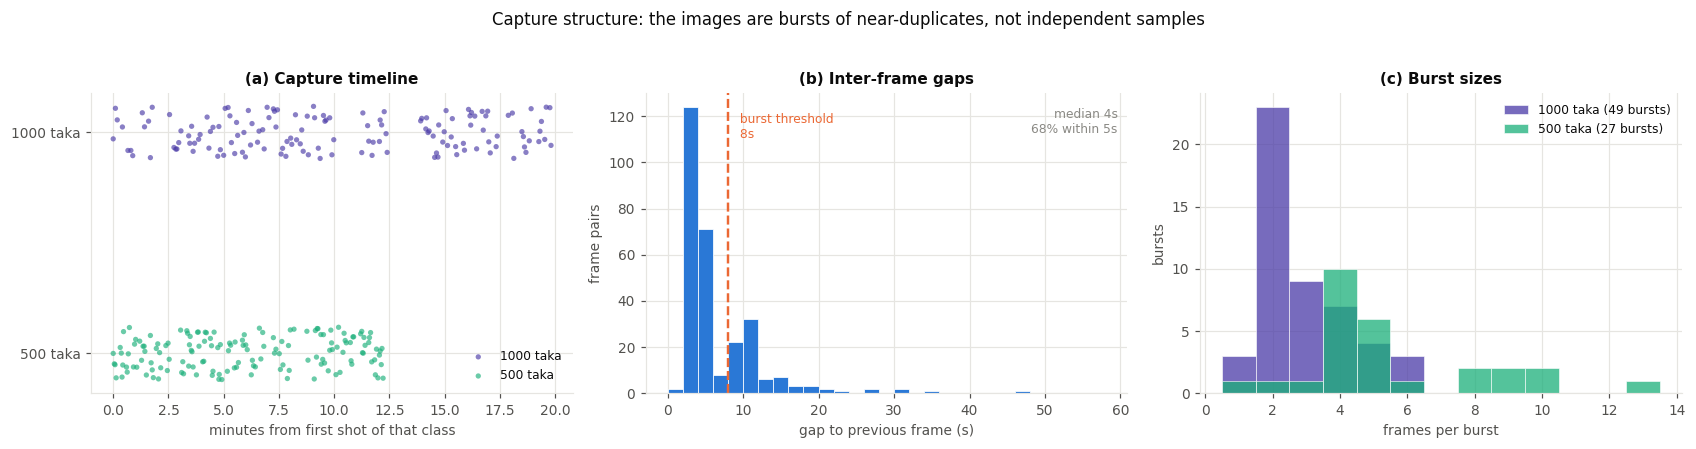

In [6]:
# ---------------------------------------------------- Figure: capture timeline and burst structure
fig, ax = plt.subplots(1, 3, figsize=(15.5, 3.9))

for cls, gdf in df.groupby("cls"):
    t0 = gdf.ts.min()
    x = (gdf.ts - t0).dt.total_seconds() / 60
    y = np.full(len(gdf), 0 if cls == "500 taka" else 1)
    ax[0].scatter(x, y + np.random.uniform(-.12, .12, len(gdf)), s=12, alpha=.65,
                  color=CLS_COLOR[cls], label=cls, edgecolors="none")
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["500 taka", "1000 taka"])
ax[0].set_xlabel("minutes from first shot of that class")
ax[0].set_title("(a) Capture timeline"); ax[0].legend(fontsize=8)

ax[1].hist(g, bins=np.arange(0, 60, 2), color=PALETTE[0], edgecolor="white", linewidth=.5)
ax[1].axvline(CFG.burst_gap_s, color=PALETTE[1], ls="--", lw=1.6)
ax[1].text(CFG.burst_gap_s + 1, ax[1].get_ylim()[1] * .85,
           f" burst threshold\n {CFG.burst_gap_s}s", fontsize=8, color=PALETTE[1])
ax[1].set_xlabel("gap to previous frame (s)"); ax[1].set_ylabel("frame pairs")
ax[1].set_title("(b) Inter-frame gaps")
ax[1].text(.98, .95, f"median {g.median():.0f}s\n{(g<=5).mean()*100:.0f}% within 5s",
           transform=ax[1].transAxes, ha="right", va="top", fontsize=8, color=INK3)

sizes = df.groupby(["cls", "burst_id"]).size().reset_index(name="n")
for i, (cls, gg) in enumerate(sizes.groupby("cls")):
    ax[2].hist(gg.n, bins=np.arange(.5, 14.5, 1), alpha=.75, color=CLS_COLOR[cls],
               label=f"{cls} ({len(gg)} bursts)", edgecolor="white", linewidth=.5)
ax[2].set_xlabel("frames per burst"); ax[2].set_ylabel("bursts")
ax[2].set_title("(c) Burst sizes"); ax[2].legend(fontsize=8)

fig.suptitle("Capture structure: the images are bursts of near-duplicates, not independent samples", y=1.03)
fig.tight_layout()
savefig(fig, "fig01_capture_bursts")

  saved -> outputs/figures/fig02_samples.png


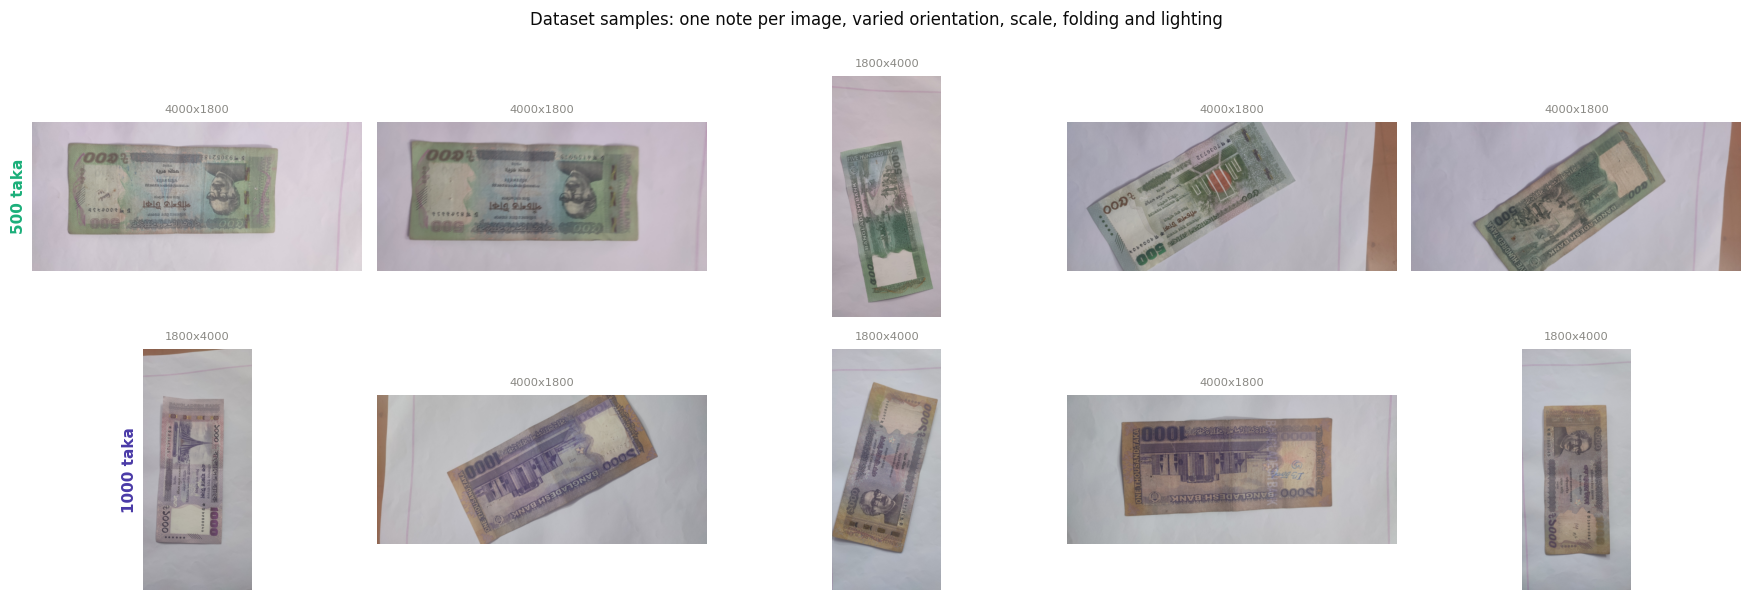

In [7]:
# ---------------------------------------------------- Figure: dataset samples
def load_rgb(path, long=None):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    if long:
        s = long / max(im.size)
        if s < 1:
            im = im.resize((round(im.width * s), round(im.height * s)), Image.BILINEAR)
    return np.asarray(im)

set_seed(11)
fig, axes = plt.subplots(2, 5, figsize=(16, 5.4))
for r, cls in enumerate(CLASS_NAMES):
    sub = df[df.cls == cls].sample(5, random_state=3)
    for c, (_, row) in enumerate(sub.iterrows()):
        axes[r, c].imshow(load_rgb(row.path, 560))
        no_axes(axes[r, c])
        axes[r, c].set_title(f"{row.disp_w}x{row.disp_h}", fontsize=7.5,
                             color=INK3, fontweight="normal")
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    axes[r, 0].grid(False)
    axes[r, 0].set_ylabel(cls, fontsize=10, fontweight="bold", color=CLS_COLOR[cls])
fig.suptitle("Dataset samples: one note per image, varied orientation, scale, folding and lighting", y=1.0)
fig.tight_layout()
savefig(fig, "fig02_samples")

---
## 3. Dataset annotation

### 3.1 Method, and why it is stated openly

The source photographs were captured for an image-level **classification** assignment, so they
carry a class label but **no bounding boxes**. Boxes had to be produced for all 291 images.

They are produced by a **deterministic classical-computer-vision pipeline** --- no neural network
is involved at any stage. This matters: generating boxes with a pre-trained detector and then using
them to evaluate detectors would be circular, and would quietly measure agreement with the
annotating network instead of correctness. The pipeline below uses only colour statistics, Otsu
thresholding, morphology, GrabCut and a convex hull, all of which are independent of every model
evaluated later.

Every box was then **inspected visually** in contact sheets, and the pipeline was revised twice
where the inspection showed it failing (§3.3). The annotation is therefore *automatic with human
verification* rather than hand-drawn, and that is a real limitation on the precision of the
coordinates, discussed in §9.

### 3.2 The pipeline

1. **EXIF transpose** and convert to RGB. 259 of 291 images carry a rotation tag; ignoring it would
   misalign every box.
2. **Estimate the background colour** as the median LAB value of a thin frame around the image
   border --- the sheet the note rests on.
3. **Distance map**: per-pixel LAB distance from that background, with the chroma channels weighted
   $2.5\times$, since the sheet is achromatic and the notes are strongly coloured.
4. **Hysteresis threshold**: Otsu gives a confident "strong" mask; a second threshold at $0.45\times$
   Otsu gives a permissive "weak" mask, and weak components are kept only where they touch a strong
   one. This recovers the pale, over-exposed ends of notes that a single Otsu threshold cuts off.
5. **Morphological** close then open to consolidate the region.
6. **Component selection**: reject anything smaller than 1% of the frame; reject *thin strips that
   hug the image border* (aspect ratio $>4$ and heavy border contact) --- these are the wooden table
   edge visible in some corners --- and score the rest by area $\times$ rectangularity.
7. **GrabCut refinement** seeded by the component (confident interior) inside a box expanded 12%,
   which pulls in low-contrast note regions the threshold missed.
8. **Convex hull** of the result, then its axis-aligned bounding box. A banknote is convex, so the
   hull repairs residual nicks and holes without ever shrinking the extent.

In [8]:
def bg_distance(rgb):
    h, w = rgb.shape[:2]
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    b = max(6, int(0.02 * min(h, w)))
    border = np.concatenate([lab[:b].reshape(-1, 3), lab[-b:].reshape(-1, 3),
                             lab[:, :b].reshape(-1, 3), lab[:, -b:].reshape(-1, 3)])
    bg = np.median(border, 0)
    d = np.sqrt(((lab - bg) ** 2 * np.array([1.0, 2.5, 2.5])).sum(-1))
    return cv2.GaussianBlur(d, (0, 0), 3)


def pick_component(m, h, w):
    n, lbl, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    best, best_score = None, -1
    for i in range(1, n):
        x, y, ww, hh, area = stats[i]
        if area < 0.01 * h * w:
            continue
        comp = (lbl == i)
        bt = (comp[0].mean() + comp[-1].mean() + comp[:, 0].mean() + comp[:, -1].mean()) / 4
        ar = max(ww, hh) / max(1, min(ww, hh))
        # a table/wood edge is a THIN strip hugging the border; a banknote is not
        if (bt > 0.20 and ar > 4.0) or bt > 0.55 or ar > 6.0:
            continue
        score = area * (area / (ww * hh))
        if score > best_score:
            best_score, best = score, (comp, (x, y, ww, hh))
    return best


KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

def note_box(rgb, use_grabcut=True):
    h, w = rgb.shape[:2]
    dn = cv2.normalize(bg_distance(rgb), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    t_hi, _ = cv2.threshold(dn, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    strong = (dn >= t_hi).astype(np.uint8)
    weak = (dn >= 0.45 * t_hi).astype(np.uint8)
    n, lbl = cv2.connectedComponents(weak, 8)[:2]
    keep = np.unique(lbl[strong > 0]); keep = keep[keep > 0]
    m = np.isin(lbl, keep).astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL, iterations=2)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL, iterations=1)

    got = pick_component(m, h, w)
    if got is None:
        return None
    comp, (x, y, ww, hh) = got

    if use_grabcut:
        px, py = int(0.12 * ww), int(0.12 * hh)
        rx0, ry0 = max(0, x - px), max(0, y - py)
        rx1, ry1 = min(w - 1, x + ww + px), min(h - 1, y + hh + py)
        if (rx1 - rx0) > 20 and (ry1 - ry0) > 20:
            gc = np.full((h, w), cv2.GC_BGD, np.uint8)
            gc[ry0:ry1, rx0:rx1] = cv2.GC_PR_FGD
            gc[cv2.erode(comp.astype(np.uint8), KERNEL, iterations=2) > 0] = cv2.GC_FGD
            try:
                bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
                cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), gc, None, bgd, fgd,
                            4, cv2.GC_INIT_WITH_MASK)
                m2 = np.isin(gc, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8) * 255
                m2 = cv2.morphologyEx(m2, cv2.MORPH_CLOSE, KERNEL, iterations=2)
                got2 = pick_component(m2, h, w)
                if got2 is not None:
                    comp = got2[0]
            except cv2.error:
                pass

    cnts, _ = cv2.findContours(comp.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None
    hull = cv2.convexHull(np.vstack(cnts))
    x, y, ww, hh = cv2.boundingRect(hull)
    return dict(x=int(x), y=int(y), w=int(ww), h=int(hh), img_w=w, img_h=h,
                fill=float(cv2.contourArea(hull) / max(1, ww * hh)),
                ar=float(max(ww, hh) / max(1, min(ww, hh))),
                rel_area=float(ww * hh / (w * h)))
print("annotation pipeline defined")

annotation pipeline defined


  saved -> outputs/figures/fig03_annotation_pipeline.png


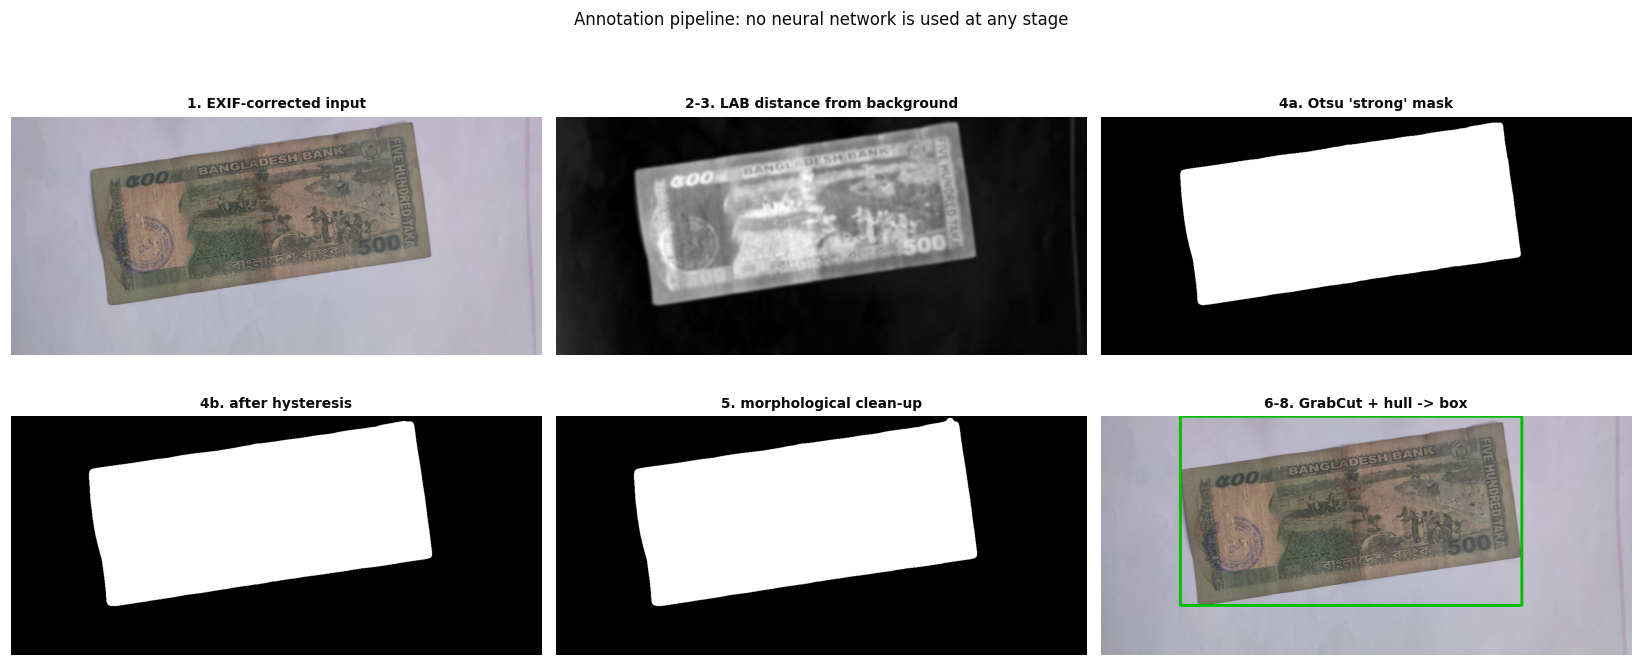

In [9]:
# ---------------------------------------------------- Figure: the pipeline, stage by stage
_sub = df[df.cls == "500 taka"]
demo = _sub.iloc[min(60, len(_sub) - 1)]
rgb = load_rgb(demo.path, CFG.export_long_side)
h, w = rgb.shape[:2]
d = bg_distance(rgb)
dn = cv2.normalize(d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
t_hi, _ = cv2.threshold(dn, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
strong = (dn >= t_hi).astype(np.uint8) * 255
weakm = (dn >= 0.45 * t_hi).astype(np.uint8)
nl, lbl = cv2.connectedComponents(weakm, 8)[:2]
keep = np.unique(lbl[strong > 0]); keep = keep[keep > 0]
hyst = np.isin(lbl, keep).astype(np.uint8) * 255
clean = cv2.morphologyEx(cv2.morphologyEx(hyst, cv2.MORPH_CLOSE, KERNEL, iterations=2),
                         cv2.MORPH_OPEN, KERNEL, iterations=1)
box = note_box(rgb)
final = rgb.copy()
cv2.rectangle(final, (box["x"], box["y"]), (box["x"] + box["w"], box["y"] + box["h"]),
              (0, 190, 0), 6)

panels = [(rgb, "1. EXIF-corrected input"), (dn, "2-3. LAB distance from background"),
          (strong, "4a. Otsu 'strong' mask"), (hyst, "4b. after hysteresis"),
          (clean, "5. morphological clean-up"), (final, "6-8. GrabCut + hull -> box")]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4))
for ax, (im, title) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=None if im.ndim == 3 else "gray")
    ax.set_title(title, fontsize=9); no_axes(ax)
fig.suptitle("Annotation pipeline: no neural network is used at any stage", y=1.01)
fig.tight_layout()
savefig(fig, "fig03_annotation_pipeline")

### 3.3 Running the pipeline, and what inspection changed

Two revisions were made after looking at the output, both recorded here because they illustrate how
the boxes were validated rather than assumed:

* **First pass** rejected 19 images outright. The cause was over-strict filters: a note rotated
  45 degrees, or a folded one, produces an almost *square* bounding box (aspect ratio 1.03--1.26),
  which fell below an aspect-ratio floor intended to describe a banknote's 2.2:1 shape. The floor
  was removed; only the upper bound and the thin-strip rule are needed to reject the table edge.
* **Second pass** succeeded everywhere but, on inspection of the hardest cases, was systematically
  **clipping** rotated notes: the pale over-exposed end fell below the Otsu threshold, so the box
  covered only part of the note. The hysteresis threshold, GrabCut refinement and convex hull in
  steps 4--8 were added to fix this. Median box rectangularity rose from 0.72 to 0.91 as a result.

In [10]:
ANN_PATH = RES / "annotations.json"
if ANN_PATH.exists():
    ann = {k: v for k, v in json.loads(ANN_PATH.read_text()).items()}
    print(f"loaded {len(ann)} cached annotations")
else:
    from concurrent.futures import ThreadPoolExecutor
    def annotate(row):
        rgb = load_rgb(row.path, CFG.export_long_side)
        b = note_box(rgb, use_grabcut=True)
        if b is None:                                   # fallback: no GrabCut refinement
            b = note_box(rgb, use_grabcut=False)
        return row.file, b
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        pairs = list(tqdm(ex.map(annotate, [r for _, r in df.iterrows()]),
                          total=len(df), desc="annotating", ncols=78))
    ann = {k: v for k, v in pairs}
    ANN_PATH.write_text(json.dumps(ann, indent=1))
    print(f"annotated {len(ann)} images in {time.time()-t0:.0f}s")

fails = [k for k, v in ann.items() if v is None]
print(f"boxes produced: {len(ann)-len(fails)}/{len(ann)}   failures: {fails}")

for k in ["rel_area", "fill", "ar"]:
    v = np.array([a[k] for a in ann.values() if a])
    print(f"{k:9s} min {v.min():.3f}  p5 {np.percentile(v,5):.3f}  med {np.median(v):.3f}  "
          f"p95 {np.percentile(v,95):.3f}  max {v.max():.3f}")
df["box"] = df.file.map(ann)
df = df[df.box.notna()].reset_index(drop=True)
print(f"\nusable annotated images: {len(df)}")

loaded 291 cached annotations
boxes produced: 290/291   failures: ['IMG_20260918_210305.jpg']
rel_area  min 0.127  p5 0.362  med 0.512  p95 0.811  max 0.941
fill      min 0.558  p5 0.781  med 0.910  p95 0.964  max 0.986
ar        min 1.051  p5 1.516  med 2.058  p95 2.337  max 3.534

usable annotated images: 290


  saved -> outputs/figures/fig04_annotation_qc.png


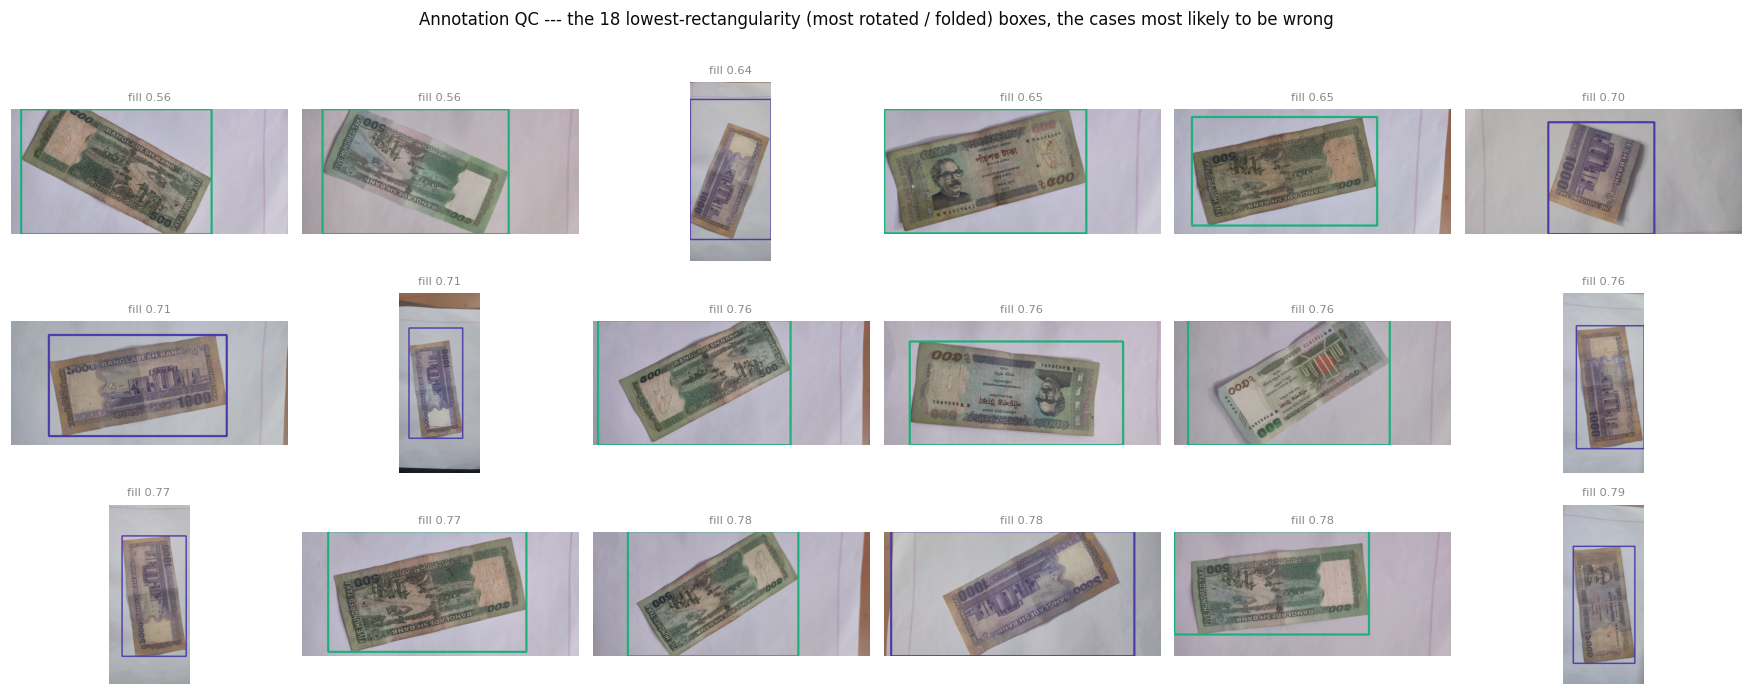

In [11]:
# ---------------------------------------------------- Figure: QC contact sheet (hardest cases)
hard = df.assign(fill=[b["fill"] for b in df.box]).nsmallest(18, "fill")
fig, axes = plt.subplots(3, 6, figsize=(16, 6.2))
for ax, (_, row) in zip(axes.ravel(), hard.iterrows()):
    rgb = load_rgb(row.path, 640); b = row.box
    s = 640 / CFG.export_long_side
    vis = rgb.copy()
    cv2.rectangle(vis, (int(b["x"]*s), int(b["y"]*s)),
                  (int((b["x"]+b["w"])*s), int((b["y"]+b["h"])*s)),
                  hex2bgr(CLS_COLOR[row.cls])[::-1], 4)
    ax.imshow(vis); no_axes(ax)
    ax.set_title(f"fill {b['fill']:.2f}", fontsize=7.5, color=INK3, fontweight="normal")
fig.suptitle("Annotation QC --- the 18 lowest-rectangularity (most rotated / folded) boxes, "
             "the cases most likely to be wrong", y=1.01)
fig.tight_layout()
savefig(fig, "fig04_annotation_qc")

  saved -> outputs/figures/fig05_box_stats.png


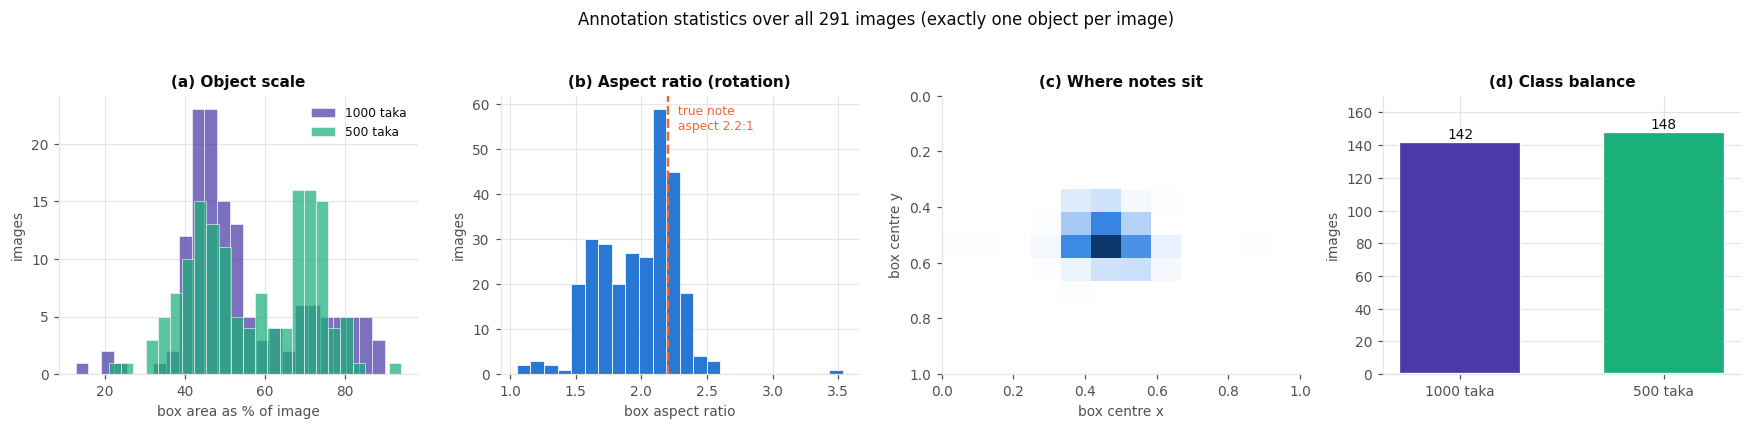

In [12]:
# ---------------------------------------------------- Figure: box statistics
areas = np.array([b["rel_area"] for b in df.box])
ars   = np.array([b["ar"] for b in df.box])
cx    = np.array([(b["x"] + b["w"] / 2) / b["img_w"] for b in df.box])
cy    = np.array([(b["y"] + b["h"] / 2) / b["img_h"] for b in df.box])

fig, ax = plt.subplots(1, 4, figsize=(16, 3.7))
for cls, g in df.groupby("cls"):
    a = np.array([b["rel_area"] for b in g.box])
    ax[0].hist(a * 100, bins=24, alpha=.72, color=CLS_COLOR[cls], label=cls,
               edgecolor="white", linewidth=.5)
ax[0].set_xlabel("box area as % of image"); ax[0].set_ylabel("images")
ax[0].set_title("(a) Object scale"); ax[0].legend(fontsize=8)

ax[1].hist(ars, bins=24, color=PALETTE[0], edgecolor="white", linewidth=.5)
ax[1].axvline(2.2, color=PALETTE[1], ls="--", lw=1.6)
ax[1].text(2.25, ax[1].get_ylim()[1]*.88, " true note\n aspect 2.2:1", fontsize=8, color=PALETTE[1])
ax[1].set_xlabel("box aspect ratio"); ax[1].set_ylabel("images")
ax[1].set_title("(b) Aspect ratio (rotation)")

hb = ax[2].hist2d(cx, cy, bins=12, range=[[0, 1], [0, 1]], cmap=SEQ_BLUE)
ax[2].set_xlabel("box centre x"); ax[2].set_ylabel("box centre y")
ax[2].set_title("(c) Where notes sit"); ax[2].grid(False)
ax[2].invert_yaxis()

n = df.groupby("cls").size()
b = ax[3].bar(n.index, n.values, color=[CLS_COLOR[c] for c in n.index],
              edgecolor="white", linewidth=1.5, width=.6)
for r, v in zip(b, n.values):
    ax[3].text(r.get_x()+r.get_width()/2, v+2, str(v), ha="center", fontsize=9)
ax[3].set_ylabel("images"); ax[3].set_title("(d) Class balance")
ax[3].set_ylim(0, n.max()*1.15)

fig.suptitle("Annotation statistics over all 291 images (exactly one object per image)", y=1.04)
fig.tight_layout()
savefig(fig, "fig05_box_stats")

---
## 4. Train / validation / test split and YOLO export

### 4.1 A burst-grouped split, not a random one

§2.3 showed the images are bursts of near-duplicates. The split therefore operates on **whole
bursts**: all frames of a burst go to the same split, so no test image has a near-twin in training.
Bursts are assigned greedily, largest first, to whichever split is furthest below its target share,
separately per class so the class balance is preserved.

A **random** split is also built, purely so §9.4 can measure how much it would have inflated the
results. It is never used for the reported model.

In [13]:
def grouped_split(frame, fracs=CFG.split, seed=CFG.seed):
    rng = np.random.default_rng(seed)
    assign = {}
    for cls, g in frame.groupby("cls"):
        bursts = g.groupby("burst_id").size().sort_values(ascending=False)
        target = {k: f * len(g) for k, f in zip(["train", "val", "test"], fracs)}
        got = {k: 0 for k in target}
        order = list(bursts.items())
        for bid, n in order:
            # whichever split is furthest below its target, measured as a deficit
            k = max(target, key=lambda s: (target[s] - got[s]) / max(target[s], 1e-9))
            assign[bid] = k; got[k] += n
    return frame.burst_id.map(assign)

df["split"] = grouped_split(df)

rng = np.random.default_rng(CFG.seed)
rand = np.array(["train"] * len(df), dtype=object)
for cls, g in df.groupby("cls"):
    idx = rng.permutation(g.index.values)
    n_tr = int(round(CFG.split[0] * len(idx))); n_va = int(round(CFG.split[1] * len(idx)))
    rand[idx[n_tr:n_tr + n_va]] = "val"; rand[idx[n_tr + n_va:]] = "test"
df["split_random"] = rand

tab = pd.crosstab(df.split, df.cls, margins=True)
print("burst-grouped split:\n", tab.to_string())
print("\nshares:", {k: round(v / len(df), 3) for k, v in df.split.value_counts().items()})
leak = df.groupby("burst_id")["split"].nunique()
print(f"\nbursts spanning more than one split: {int((leak > 1).sum())}   (must be 0)")
leak_r = df.groupby("burst_id")["split_random"].nunique()
print(f"same for the RANDOM split:            {int((leak_r > 1).sum())}   "
      f"of {df.burst_id.nunique()} bursts -> that is the leakage §9.4 quantifies")

burst-grouped split:
 cls    1000 taka  500 taka  All
split                          
test          22        23   45
train         98       102  200
val           22        23   45
All          142       148  290

shares: {'train': 0.69, 'val': 0.155, 'test': 0.155}

bursts spanning more than one split: 0   (must be 0)
same for the RANDOM split:            48   of 76 bursts -> that is the leakage §9.4 quantifies


  saved -> outputs/figures/fig06_split.png


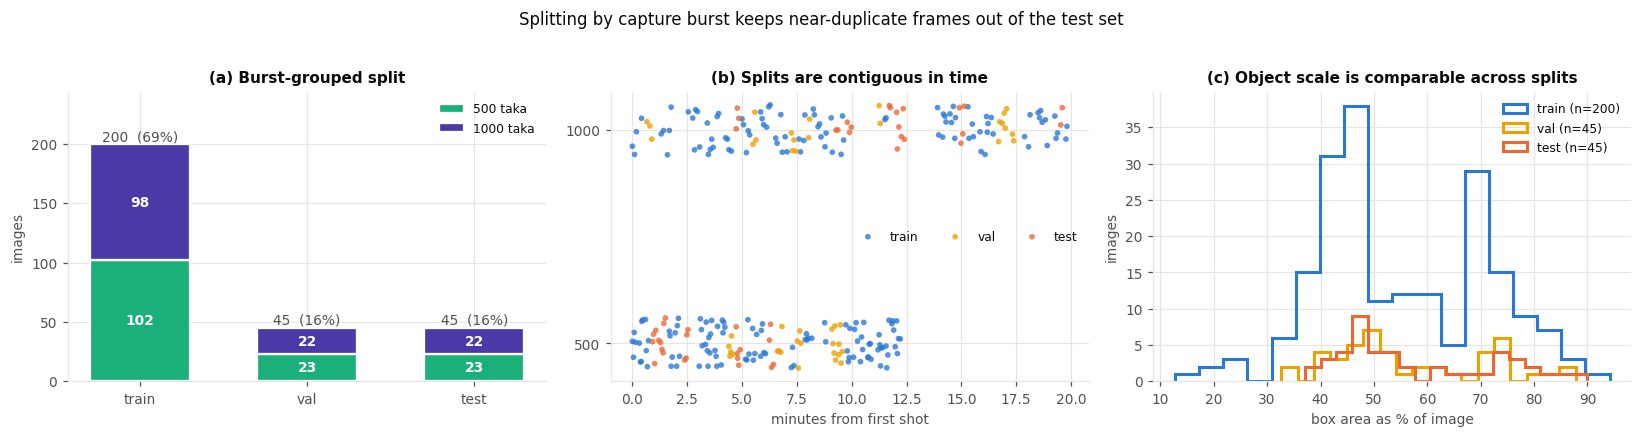

In [14]:
# ---------------------------------------------------- Figure: split composition
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

order = ["train", "val", "test"]
bot = np.zeros(3)
for cls in CLASS_NAMES:
    v = [int(((df.split == s) & (df.cls == cls)).sum()) for s in order]
    ax[0].bar(order, v, bottom=bot, color=CLS_COLOR[cls], label=cls,
              edgecolor="white", linewidth=1.5, width=.6)
    for i, (b, vv) in enumerate(zip(bot, v)):
        if vv: ax[0].text(i, b + vv/2, str(vv), ha="center", va="center",
                          fontsize=9, color="white", fontweight="bold")
    bot += v
for i, s in enumerate(order):
    ax[0].text(i, bot[i] + 3, f"{int(bot[i])}  ({bot[i]/len(df)*100:.0f}%)",
               ha="center", fontsize=9, color=INK2)
ax[0].set_ylabel("images"); ax[0].set_title("(a) Burst-grouped split"); ax[0].legend(fontsize=8)
ax[0].set_ylim(0, bot.max()*1.22)

SPL_COLOR = {"train": PALETTE[0], "val": PALETTE[3], "test": PALETTE[1]}
for cls, gdf in df.groupby("cls"):
    t0 = gdf.ts.min()
    for s in order:
        sub = gdf[gdf.split == s]
        ax[1].scatter((sub.ts - t0).dt.total_seconds()/60,
                      np.full(len(sub), 0 if cls == "500 taka" else 1) +
                      np.random.uniform(-.12, .12, len(sub)),
                      s=14, color=SPL_COLOR[s], label=s if cls == "500 taka" else None,
                      edgecolors="none", alpha=.8)
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["500", "1000"])
ax[1].set_xlabel("minutes from first shot"); ax[1].set_title("(b) Splits are contiguous in time")
ax[1].legend(fontsize=8, ncol=3)

for s in order:
    a = np.array([b["rel_area"] for b in df[df.split == s].box]) * 100
    ax[2].hist(a, bins=18, histtype="step", lw=2, color=SPL_COLOR[s], label=f"{s} (n={len(a)})")
ax[2].set_xlabel("box area as % of image"); ax[2].set_ylabel("images")
ax[2].set_title("(c) Object scale is comparable across splits"); ax[2].legend(fontsize=8)

fig.suptitle("Splitting by capture burst keeps near-duplicate frames out of the test set", y=1.03)
fig.tight_layout()
savefig(fig, "fig06_split")

### 4.2 Export to YOLO format

YOLO expects one `.txt` per image beside it, each line
`class_id  x_centre  y_centre  width  height`, all **normalised to [0,1]**. Images are written at
1280 px on the long side (down from 4000x1800) with EXIF orientation already applied, so nothing
downstream has to think about rotation again.

In [15]:
def export_yolo(frame, root, split_col="split", force=False):
    root = Path(root)
    if root.exists() and not force and (root / "data.yaml").exists():
        print(f"{root.name}: already exported"); return root / "data.yaml"
    for s in ["train", "val", "test"]:
        (root / "images" / s).mkdir(parents=True, exist_ok=True)
        (root / "labels" / s).mkdir(parents=True, exist_ok=True)
    n = 0
    for _, row in tqdm(list(frame.iterrows()), desc=f"export {root.name}", ncols=78):
        s = row[split_col]
        rgb = load_rgb(row.path, CFG.export_long_side)
        h, w = rgb.shape[:2]
        b = row.box
        sx, sy = w / b["img_w"], h / b["img_h"]
        x, y, bw, bh = b["x"]*sx, b["y"]*sy, b["w"]*sx, b["h"]*sy
        xc, yc = (x + bw/2) / w, (y + bh/2) / h
        nw, nh = bw / w, bh / h
        stem = f"{row.cls_id}_{Path(row.file).stem}"
        cv2.imwrite(str(root/"images"/s/f"{stem}.jpg"),
                    cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 92])
        (root/"labels"/s/f"{stem}.txt").write_text(
            f"{row.cls_id} {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}\n")
        n += 1
    yml = {"path": str(root.resolve()), "train": "images/train", "val": "images/val",
           "test": "images/test", "nc": NC, "names": {i: c for i, c in enumerate(CLASS_NAMES)}}
    (root/"data.yaml").write_text(yaml.safe_dump(yml, sort_keys=False))
    print(f"{root.name}: wrote {n} images + labels")
    return root / "data.yaml"

DATA_YAML = export_yolo(df, YOLO_DS, "split")
DATA_YAML_RAND = export_yolo(df, DATA / "yolo_random", "split_random")
print("\n" + (YOLO_DS/"data.yaml").read_text())
for s in ["train", "val", "test"]:
    print(f"  {s:5s}: {len(list((YOLO_DS/'images'/s).glob('*.jpg')))} images, "
          f"{len(list((YOLO_DS/'labels'/s).glob('*.txt')))} labels")

yolo: already exported
yolo_random: already exported

path: D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\data\yolo
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: 500 taka
  1: 1000 taka

  train: 200 images, 200 labels
  val  : 45 images, 45 labels
  test : 45 images, 45 labels


  saved -> outputs/figures/fig07_exported_labels.png


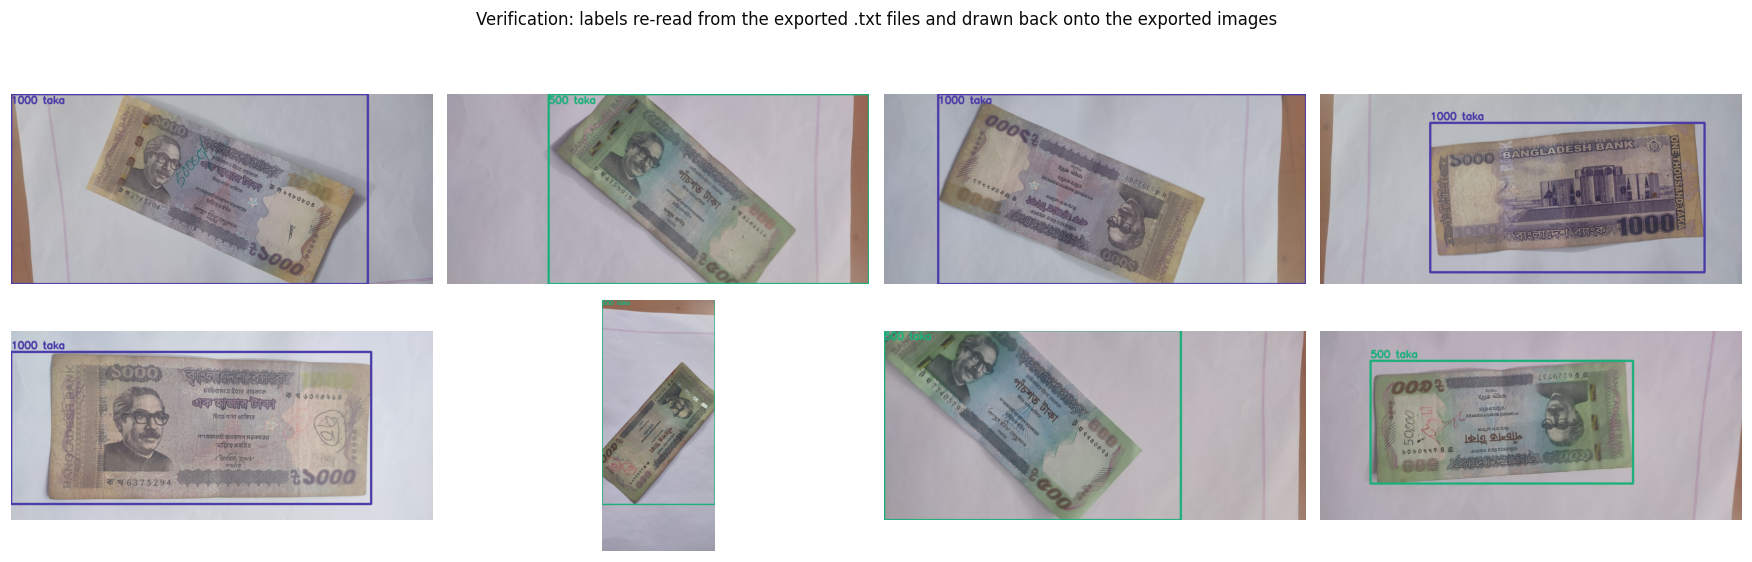

In [16]:
# ---------------------------------------------------- Figure: exported labels, read back from disk
import glob
files = sorted(glob.glob(str(YOLO_DS/"images"/"train"/"*.jpg")))
set_seed(2); pick = np.random.choice(len(files), 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 5.0))
for ax, i in zip(axes.ravel(), pick):
    p = Path(files[i])
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    for line in (YOLO_DS/"labels"/"train"/f"{p.stem}.txt").read_text().split("\n"):
        if not line.strip(): continue
        cid, xc, yc, bw, bh = line.split()
        cid = int(cid); xc, yc, bw, bh = (float(v) for v in (xc, yc, bw, bh))
        x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
        x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
        col = hex2bgr(CLS_COLOR[CLASS_NAMES[cid]])[::-1]
        cv2.rectangle(im, (x1, y1), (x2, y2), col, 5)
        cv2.putText(im, CLASS_NAMES[cid], (x1, max(28, y1-10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, col, 3)
    ax.imshow(im); no_axes(ax)
fig.suptitle("Verification: labels re-read from the exported .txt files and drawn back onto the exported images", y=1.01)
fig.tight_layout()
savefig(fig, "fig07_exported_labels")

---
## 5. Data augmentation

### 5.1 What the augmentation has to compensate for

The source photographs are clean: every note is fully visible, well lit, unobstructed, and lying on
the same plain sheet. The assignment asks for a detector that works under **partial occlusion,
varying illumination and complex backgrounds**, and the practical requirement is that the model
should still find a note that is *partly hidden, noisy, blurred or dirty*. None of that exists in
the 291 source images, so it has to be **synthesised during training**.

Augmentation here therefore has two jobs, and they are kept separate:

* **Geometric** variation --- handled by YOLO's own pipeline (mosaic, rotation, scale, translation,
  shear, perspective, flips). This also manufactures the multi-object scenes the dataset lacks:
  every source image contains exactly one note, but mosaic stitches four images into one, so the
  model does see several notes at once during training. That matters directly for the counting
  application in the bonus script.
* **Photometric and destructive** variation --- occlusion, sensor noise, blur, dirt, shadow,
  compression. YOLO does not provide these for detection, so a **custom Albumentations pipeline is
  injected** into the training data loader.

### 5.2 The injected pipeline

| Transform | p | Simulates |
|---|---|---|
| `CoarseDropout` (1--6 holes, 8--28% of side) | 0.45 | **partial occlusion** --- a finger, another note, or an object lying across the banknote |
| `GaussNoise`, `ISONoise` | 0.30 / 0.20 | **sensor noise** in low light or at high ISO |
| `MotionBlur`, `Defocus` | 0.20 / 0.10 | handheld camera shake, missed focus |
| `Spatter` | 0.25 | **dirt, stains and grime** on a worn note |
| `RandomShadow` | 0.25 | a hand or object casting shadow across the note |
| `RandomBrightnessContrast`, `RandomGamma`, `CLAHE` | 0.50 / 0.30 / 0.20 | **varying illumination**, under- and over-exposure |
| `HueSaturationValue` (hue limited to $\pm8$) | 0.30 | colour cast from different light sources |
| `ToGray` | 0.05 | forces the model not to rely on colour alone |
| `ImageCompression` (quality 35--90) | 0.30 | JPEG artefacts from messaging apps / cheap cameras |

Two deliberate choices:

**The hue shift is kept small.** Assignment 9 established that these two notes are separable by
colour almost on its own --- 500 is green/teal, 1000 is purple. A large hue rotation would push a
500 into the 1000 region and inject label noise. `hue_shift_limit=8` (out of 180) stays well inside
each note's colour band.

**`ToGray` is kept at p = 0.05 rather than dropped.** Because colour is such a strong cue, a model
trained without it will lean on colour entirely and collapse under unusual lighting. Occasionally
removing colour forces the network to also read the printed numerals and the portrait/building
layout, which are the cues that survive a colour cast.

**Boxes are deliberately *not* updated by `CoarseDropout`.** When a hole is punched over part of a
note, the ground-truth box still covers the whole note. That is the intended lesson: *the object is
still there and still that size, even though you can only see part of it*.

In [17]:
import albumentations as A

def build_alb_pipeline():
    # Pixel-level only: boxes are intentionally left untouched, so an occluded note keeps
    # its full-extent ground-truth box.
    return A.Compose([
        # --- partial occlusion -------------------------------------------------
        A.CoarseDropout(num_holes_range=(1, 6),
                        hole_height_range=(0.08, 0.28), hole_width_range=(0.08, 0.28),
                        fill="random_uniform", p=0.45),
        # --- sensor noise ------------------------------------------------------
        A.GaussNoise(std_range=(0.03, 0.14), p=0.30),
        A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=0.20),
        # --- blur --------------------------------------------------------------
        A.OneOf([A.MotionBlur(blur_limit=(3, 9)), A.Defocus(radius=(2, 6))], p=0.22),
        # --- dirt / grime ------------------------------------------------------
        A.Spatter(mean=(0.6, 0.72), std=(0.25, 0.35), cutout_threshold=(0.62, 0.70),
                  mode="mud", p=0.25),
        # --- illumination ------------------------------------------------------
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 2), p=0.25),
        A.RandomBrightnessContrast(brightness_limit=(-0.35, 0.3),
                                   contrast_limit=(-0.3, 0.35), p=0.50),
        A.RandomGamma(gamma_limit=(65, 145), p=0.30),
        A.CLAHE(clip_limit=(1, 4), p=0.20),
        # --- colour ------------------------------------------------------------
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=28,
                             val_shift_limit=22, p=0.30),
        A.ToGray(p=0.05),
        # --- capture / codec ---------------------------------------------------
        A.ImageCompression(quality_range=(35, 90), p=0.30),
    ])


import ultralytics.data.augment as _ua
_ORIG_ALB_INIT = getattr(_ua.Albumentations, "_orig_init", _ua.Albumentations.__init__)
_ua.Albumentations._orig_init = _ORIG_ALB_INIT      # keep a handle for the §9.3 ablation

def patch_ultralytics_albumentations(custom=True):
    # Replace ultralytics' fixed default Albumentations set with ours. contains_spatial=False
    # makes ultralytics call transform(image=...) only, leaving bounding boxes alone.
    if not custom:
        _ua.Albumentations.__init__ = _ORIG_ALB_INIT
        print("ultralytics Albumentations restored to its DEFAULT set")
        return
    pipeline = build_alb_pipeline()
    def _init(self, p=1.0):
        self.p = p
        self.contains_spatial = False
        self.transform = pipeline
    _ua.Albumentations.__init__ = _init
    print("ultralytics Albumentations patched with the custom occlusion/noise/dirt pipeline")

patch_ultralytics_albumentations(True)
ALB = build_alb_pipeline()
print(f"{len(ALB.transforms)} transform groups in the injected pipeline")

ultralytics Albumentations patched with the custom occlusion/noise/dirt pipeline
12 transform groups in the injected pipeline


### 5.3 Geometric augmentation (YOLO hyper-parameters)

These are passed to `model.train()` and are reported in full in §6.3. They are set more
aggressively than the ultralytics defaults because the dataset is small and highly repetitive.

| Hyper-parameter | Value | Default | Why changed |
|---|---|---|---|
| `mosaic` | 1.0 | 1.0 | 4-image composites; the only source of multi-note scenes |
| `close_mosaic` | 15 | 10 | last 15 epochs train on un-mosaicked images to fix the train/test gap |
| `degrees` | 25.0 | 0.0 | notes appear at every angle in the data; rotation must be learned |
| `translate` | 0.25 | 0.1 | pushes notes off the frame edge -> **partially visible objects** |
| `scale` | 0.6 | 0.5 | note area already spans 13--94%; widen it further |
| `shear` | 6.0 | 0.0 | approximates off-axis viewing |
| `perspective` | 0.0005 | 0.0 | mild keystone, as when shooting from a tilt |
| `fliplr` | 0.5 | 0.5 | --- |
| `flipud` | 0.3 | 0.0 | a note photographed upside down is perfectly normal |
| `mixup` | 0.1 | 0.0 | mild; discourages over-confidence on a tiny dataset |
| `hsv_h / hsv_s / hsv_v` | 0.015 / 0.7 / 0.4 | same | hue kept small to protect the colour cue |

In [18]:
AUG_HYP = dict(
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=25.0, translate=0.25, scale=0.6, shear=6.0, perspective=0.0005,
    flipud=0.3, fliplr=0.5, mosaic=1.0, close_mosaic=15, mixup=0.1, copy_paste=0.0,
)
pd.DataFrame([{"hyper-parameter": k, "value": v} for k, v in AUG_HYP.items()])

,hyper-parameter,value
0,hsv_h,0.0150
1,hsv_s,0.7000
2,hsv_v,0.4000
3,degrees,25.0000
4,translate,0.2500
5,scale,0.6000
6,shear,6.0000
7,perspective,0.0005
8,flipud,0.3000
9,fliplr,0.5000


  saved -> outputs/figures/fig08_augmentation_families.png


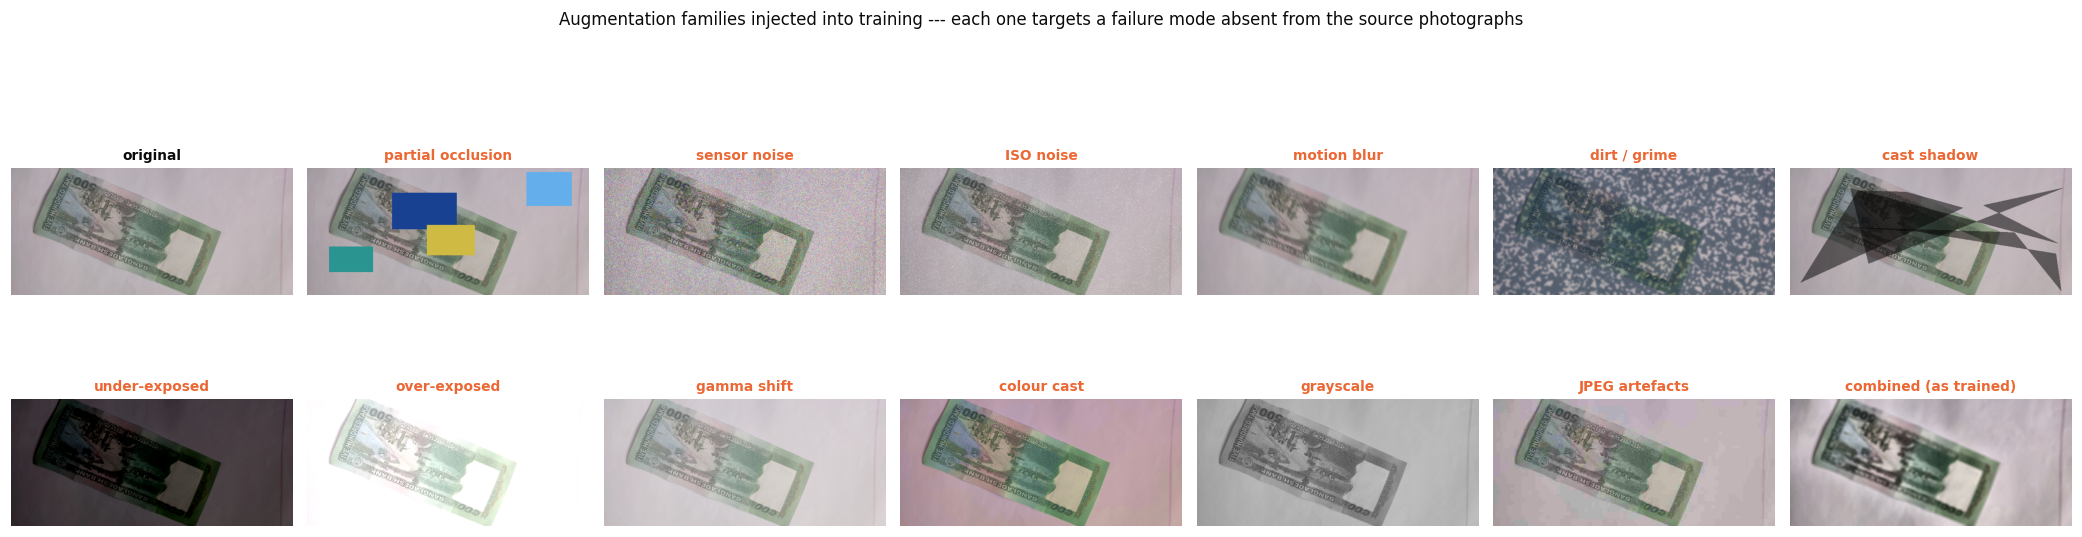

In [19]:
# ---------------------------------------------------- Figure: what each augmentation family does
demo_path = sorted((YOLO_DS/"images"/"train").glob("*.jpg"))[7]
base = cv2.cvtColor(cv2.imread(str(demo_path)), cv2.COLOR_BGR2RGB)
base = cv2.resize(base, (640, int(640*base.shape[0]/base.shape[1])))

families = [
    ("original", None),
    ("partial occlusion", A.CoarseDropout(num_holes_range=(3, 6), hole_height_range=(0.15, 0.3),
                                          hole_width_range=(0.15, 0.3), fill="random_uniform", p=1.0)),
    ("sensor noise", A.GaussNoise(std_range=(0.10, 0.16), p=1.0)),
    ("ISO noise", A.ISONoise(color_shift=(0.03, 0.05), intensity=(0.4, 0.6), p=1.0)),
    ("motion blur", A.MotionBlur(blur_limit=(9, 13), p=1.0)),
    ("dirt / grime", A.Spatter(mean=(0.62, 0.68), std=(0.3, 0.35),
                               cutout_threshold=(0.6, 0.66), mode="mud", p=1.0)),
    ("cast shadow", A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(2, 3), p=1.0)),
    ("under-exposed", A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.35),
                                                 contrast_limit=(-0.2, -0.1), p=1.0)),
    ("over-exposed", A.RandomBrightnessContrast(brightness_limit=(0.3, 0.4),
                                                contrast_limit=(-0.1, 0.1), p=1.0)),
    ("gamma shift", A.RandomGamma(gamma_limit=(45, 60), p=1.0)),
    ("colour cast", A.HueSaturationValue(hue_shift_limit=(7, 8), sat_shift_limit=(25, 30),
                                         val_shift_limit=(-10, 10), p=1.0)),
    ("grayscale", A.ToGray(p=1.0)),
    ("JPEG artefacts", A.ImageCompression(quality_range=(12, 18), p=1.0)),
    ("combined (as trained)", "ALL"),
]
set_seed(4)
fig, axes = plt.subplots(2, 7, figsize=(19, 5.6))
for ax, (name, tf) in zip(axes.ravel(), families):
    if tf is None:
        im = base
    elif tf == "ALL":
        im = ALB(image=base)["image"]
    else:
        im = A.Compose([tf])(image=base)["image"]
    ax.imshow(im); no_axes(ax)
    ax.set_title(name, fontsize=9, color=INK if name == "original" else PALETTE[1])
fig.suptitle("Augmentation families injected into training --- each one targets a failure mode "
             "absent from the source photographs", y=1.02)
fig.tight_layout()
savefig(fig, "fig08_augmentation_families")

  saved -> outputs/figures/fig09_occlusion_levels.png


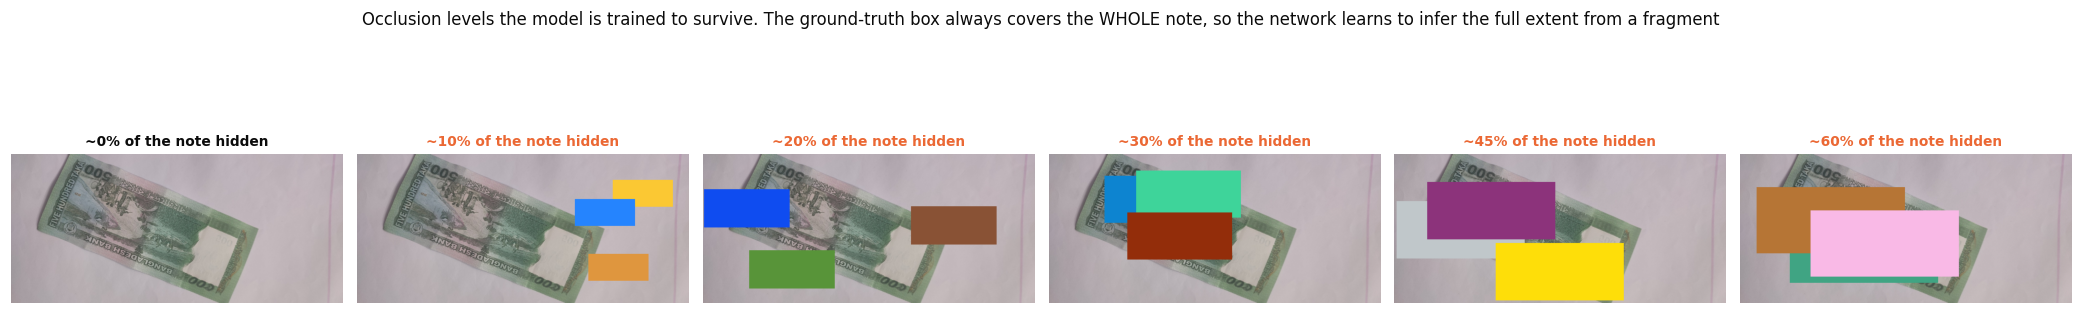

In [20]:
# ---------------------------------------------------- Figure: occlusion severity sweep
fig, axes = plt.subplots(1, 6, figsize=(19, 3.4))
for ax, frac in zip(axes, [0.0, 0.1, 0.2, 0.3, 0.45, 0.6]):
    if frac == 0:
        im = base
    else:
        side = float(np.sqrt(frac / 3))
        im = A.Compose([A.CoarseDropout(
            num_holes_range=(3, 3), hole_height_range=(side, side),
            hole_width_range=(side, side), fill="random_uniform", p=1.0)])(image=base)["image"]
    ax.imshow(im); no_axes(ax)
    ax.set_title(f"~{frac*100:.0f}% of the note hidden", fontsize=9,
                 color=INK if frac == 0 else PALETTE[1])
fig.suptitle("Occlusion levels the model is trained to survive. The ground-truth box always covers "
             "the WHOLE note, so the network learns to infer the full extent from a fragment", y=1.04)
fig.tight_layout()
savefig(fig, "fig09_occlusion_levels")

  saved -> outputs/figures/fig10_mosaic.png


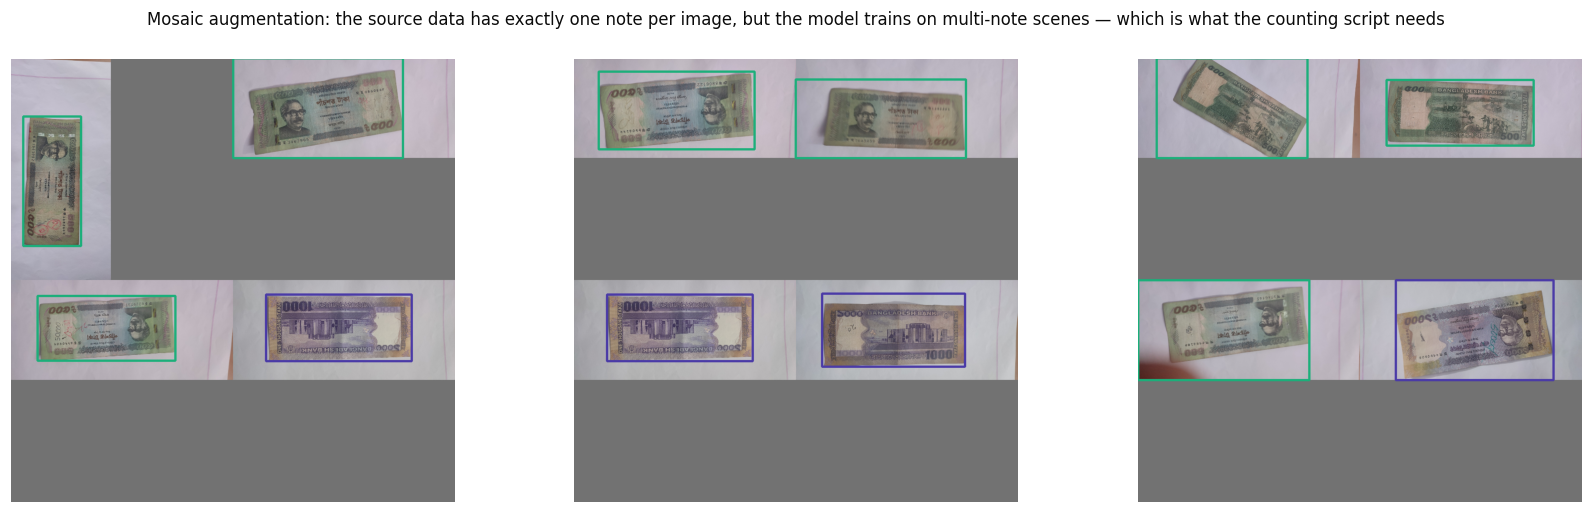

In [21]:
# ---------------------------------------------------- Figure: mosaic -> multi-note scenes
# Build a mosaic by hand to show what YOLO's loader produces internally.
files = sorted((YOLO_DS/"images"/"train").glob("*.jpg"))
set_seed(9)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
for ax in axes:
    pick = np.random.choice(len(files), 4, replace=False)
    S = 480
    canvas = np.full((S*2, S*2, 3), 114, np.uint8)
    for k, i in enumerate(pick):
        p = Path(files[i])
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = im.shape[:2]
        sc = S / max(h, w)
        im2 = cv2.resize(im, (int(w*sc), int(h*sc)))
        hh, ww = im2.shape[:2]
        oy, ox = (k//2)*S, (k%2)*S
        canvas[oy:oy+hh, ox:ox+ww] = im2
        for line in (YOLO_DS/"labels"/"train"/f"{p.stem}.txt").read_text().split("\n"):
            if not line.strip(): continue
            cid, xc, yc, bw, bh = line.split(); cid = int(cid)
            xc, yc, bw, bh = (float(v) for v in (xc, yc, bw, bh))
            x1 = int(ox + (xc-bw/2)*ww); y1 = int(oy + (yc-bh/2)*hh)
            x2 = int(ox + (xc+bw/2)*ww); y2 = int(oy + (yc+bh/2)*hh)
            cv2.rectangle(canvas, (x1, y1), (x2, y2),
                          hex2bgr(CLS_COLOR[CLASS_NAMES[cid]])[::-1], 4)
    ax.imshow(canvas); no_axes(ax)
fig.suptitle("Mosaic augmentation: the source data has exactly one note per image, but the model "
             "trains on multi-note scenes — which is what the counting script needs", y=1.0)
fig.tight_layout()
savefig(fig, "fig10_mosaic")

---
## 6. Model architecture and training configuration

### 6.1 Why YOLOv8, and which size

**YOLOv8** is used because the bonus deliverable is a real-time webcam counter, which rules out
two-stage detectors: a single forward pass that emits boxes and classes directly is what makes
30+ FPS on a webcam feasible.

Two sizes are fine-tuned so the capacity question can be answered rather than assumed:

* **YOLOv8n** (3.16 M parameters) --- the model deployed in the live script.
* **YOLOv8s** (11.17 M parameters) --- 3.5x the capacity, to test whether this task needs it.

### 6.2 Architecture

YOLOv8 has three parts:

* **Backbone --- CSPDarknet.** Five downsampling stages built from `Conv` blocks and `C2f`
  (cross-stage partial) blocks, ending in an `SPPF` module that pools at several kernel sizes to
  widen the receptive field cheaply. Produces feature maps at strides 8, 16 and 32.
* **Neck --- PAN-FPN.** A top-down path carries semantic information from deep layers down to
  high-resolution ones, then a bottom-up path carries localisation detail back up. The result is
  three fused scales, which is what lets one model handle a note filling 13% of the frame and one
  filling 94%.
* **Head --- decoupled and anchor-free.** Classification and box regression have separate branches.
  Unlike YOLOv5 there are no anchor boxes: the head predicts distances from a point to the four box
  edges, using a Distribution Focal Loss formulation. This removes anchor tuning entirely, which
  matters here because banknotes have an unusual 2.2:1 aspect ratio that COCO anchors would fit
  poorly.

**What fine-tuning changes.** The detection head's classification branch is rebuilt for `nc=2`
instead of `nc=80`; everything else starts from the COCO weights. The backbone and neck are *not*
frozen --- with 2 classes of a texture that COCO never contained, the feature extractor itself
needs to adapt.

In [22]:
from ultralytics import YOLO
from ultralytics.nn.tasks import DetectionModel

def arch_summary(weights):
    m = YOLO(weights)
    nl = len(list(m.model.modules()))
    npar = sum(p.numel() for p in m.model.parameters())
    ngrad = sum(p.numel() for p in m.model.parameters() if p.requires_grad)
    try:
        from ultralytics.utils.torch_utils import get_flops
        gf = get_flops(m.model, CFG.imgsz)
    except Exception:
        gf = float("nan")
    return dict(model=weights, modules=nl, params_M=round(npar/1e6, 3),
                trainable_M=round(ngrad/1e6, 3), GFLOPs=round(gf, 2),
                coco_classes=len(m.names))

arch = pd.DataFrame([arch_summary(CFG.base_model), arch_summary(CFG.second_model)])
arch.to_csv(RES/"architecture.csv", index=False)
display(arch)

# layer-type census of the backbone/neck, to document the architecture concretely
m = YOLO(CFG.base_model)
types = Counter(type(x).__name__ for x in m.model.model)
print("\nYOLOv8n top-level module sequence:")
print("  " + ", ".join(f"{k} x{v}" for k, v in types.items()))
print(f"\ndetection head strides: {m.model.model[-1].stride.tolist()}")
del m

,model,modules,params_M,trainable_M,GFLOPs,coco_classes
0,yolov8n.pt,225,3.157,0.0,8.86,80
1,yolov8s.pt,225,11.167,0.0,28.82,80



YOLOv8n top-level module sequence:
  Conv x7, C2f x8, SPPF x1, Upsample x2, Concat x4, Detect x1

detection head strides: [8.0, 16.0, 32.0]


### 6.3 Training configuration

Both models are trained with exactly the same recipe, so the comparison isolates capacity.

In [23]:
TRAIN_CFG = dict(
    data=str(DATA_YAML), imgsz=CFG.imgsz, epochs=CFG.epochs, batch=CFG.batch,
    optimizer=CFG.optimizer, lr0=CFG.lr0, lrf=0.01, momentum=0.937, weight_decay=0.0005,
    warmup_epochs=3.0, cos_lr=True, patience=CFG.patience,
    seed=CFG.seed, deterministic=True, device=DEV, workers=NWORKERS,
    pretrained=True, val=True, plots=True, save=True, exist_ok=True,
    project=str(RUNS), **AUG_HYP,
)
rows = [{"setting": k, "value": str(v)} for k, v in TRAIN_CFG.items()
        if k not in ("project",)]
cfg_df = pd.DataFrame(rows)
cfg_df.to_csv(RES/"train_config.csv", index=False)
print(f"hardware: {HARDWARE}")
display(cfg_df)

hardware: NVIDIA GeForce RTX 5070 Ti, 17.1 GB VRAM


,setting,value
0,data,D:\Study\MSc\2nd semester\Computer Vision\Assi...
1,imgsz,640
2,epochs,100
3,batch,16
4,optimizer,auto
5,lr0,0.01
6,lrf,0.01
7,momentum,0.937
8,weight_decay,0.0005
9,warmup_epochs,3.0


### 6.4 Fine-tuning

`patience=30` stops training if validation mAP has not improved for 30 epochs, and ultralytics
always keeps `best.pt` (highest validation fitness) separately from `last.pt`, so the reported
model is selected on **validation**, never on test.

In [24]:
FORCE_RETRAIN = False

def finetune(weights, name):
    out = RUNS / name / "weights" / "best.pt"
    if out.exists() and not FORCE_RETRAIN:
        print(f"[{name}] already trained -> {out}")
        return out
    patch_ultralytics_albumentations()     # re-assert after any ultralytics reload
    set_seed(CFG.seed)
    model = YOLO(weights)
    t0 = time.time()
    model.train(name=name, **TRAIN_CFG)
    print(f"[{name}] trained in {(time.time()-t0)/60:.1f} min")
    return out

BEST_N = finetune(CFG.base_model, "finetune_yolov8n")
BEST_S = finetune(CFG.second_model, "finetune_yolov8s")
print("\n", BEST_N, "\n", BEST_S)

[finetune_yolov8n] already trained -> D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\finetune_yolov8n\weights\best.pt
[finetune_yolov8s] already trained -> D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\finetune_yolov8s\weights\best.pt

 D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\finetune_yolov8n\weights\best.pt 
 D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\finetune_yolov8s\weights\best.pt


  saved -> outputs/figures/fig11_training_curves.png


,Model,Epochs run,Best epoch,Best val mAP50,Best val mAP50-95,Final train box loss,Final val box loss
0,Fine-tuned YOLOv8n,100,87,0.995,0.7301,0.9783,1.1111
1,Fine-tuned YOLOv8s,100,95,0.995,0.7338,0.9718,1.0960


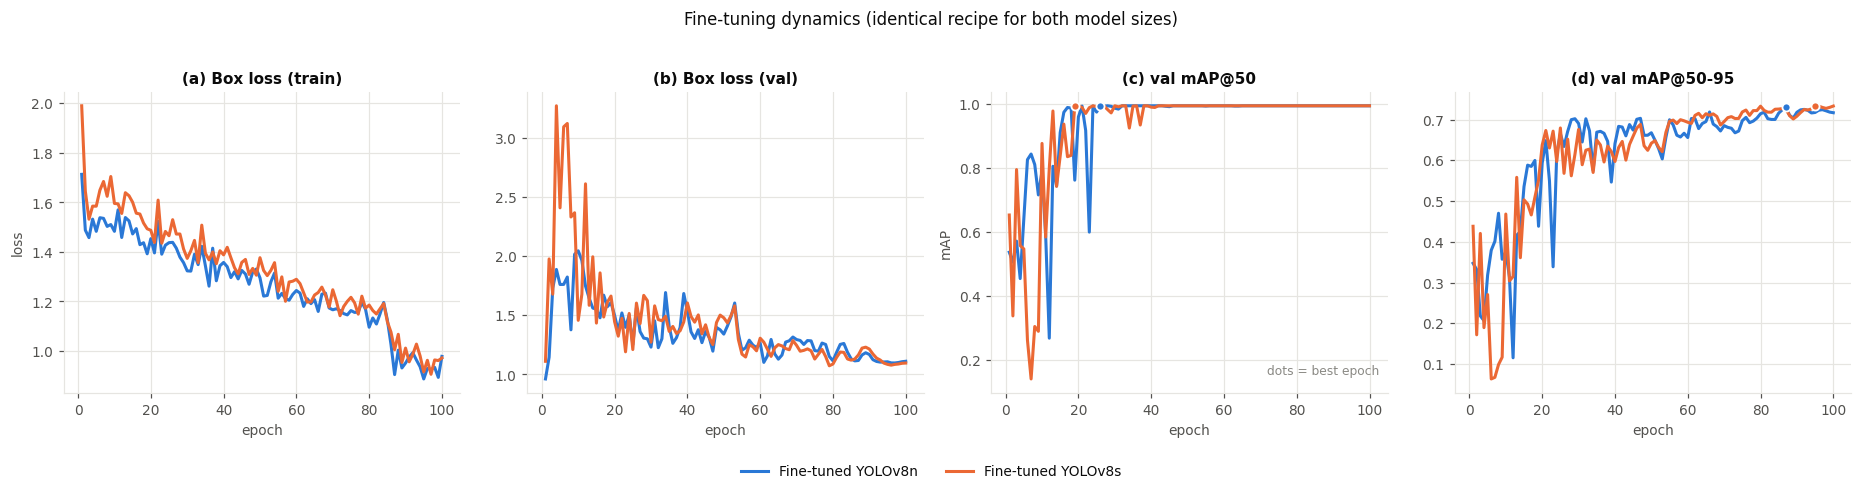

In [25]:
# ---------------------------------------------------- Figure: training curves
def read_results(name):
    p = RUNS / name / "results.csv"
    if not p.exists(): return None
    r = pd.read_csv(p); r.columns = [c.strip() for c in r.columns]
    return r

RUN_NAMES = {"Fine-tuned YOLOv8n": "finetune_yolov8n", "Fine-tuned YOLOv8s": "finetune_yolov8s"}
curves = {k: read_results(v) for k, v in RUN_NAMES.items()}

fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
specs = [("train/box_loss", "(a) Box loss (train)"), ("val/box_loss", "(b) Box loss (val)"),
         ("metrics/mAP50(B)", "(c) val mAP@50"), ("metrics/mAP50-95(B)", "(d) val mAP@50-95")]
for j, (col, title) in enumerate(specs):
    for k, r in curves.items():
        if r is None or col not in r: continue
        ax[j].plot(r["epoch"], r[col], color=MODEL_COLOR[k], label=k)
        if col.startswith("metrics"):
            i = int(np.argmax(r[col]))
            ax[j].scatter([r["epoch"][i]], [r[col][i]], s=28, color=MODEL_COLOR[k],
                          zorder=5, edgecolor="white", linewidth=1.2)
    ax[j].set_xlabel("epoch"); ax[j].set_title(title)
ax[0].set_ylabel("loss"); ax[2].set_ylabel("mAP")
ax[2].text(.98, .06, "dots = best epoch", transform=ax[2].transAxes, ha="right",
           fontsize=8, color=INK3)
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.09))
fig.suptitle("Fine-tuning dynamics (identical recipe for both model sizes)", y=1.03)
fig.tight_layout()
savefig(fig, "fig11_training_curves")

conv = []
for k, r in curves.items():
    if r is None: continue
    i = int(np.argmax(r["metrics/mAP50-95(B)"]))
    conv.append({"Model": k, "Epochs run": int(r["epoch"].max()),
                 "Best epoch": int(r["epoch"][i]),
                 "Best val mAP50": round(float(r["metrics/mAP50(B)"].max()), 4),
                 "Best val mAP50-95": round(float(r["metrics/mAP50-95(B)"][i]), 4),
                 "Final train box loss": round(float(r["train/box_loss"].iloc[-1]), 4),
                 "Final val box loss": round(float(r["val/box_loss"].iloc[-1]), 4)})
conv_df = pd.DataFrame(conv); conv_df.to_csv(RES/"convergence.csv", index=False)
display(conv_df)

---
## 7. Performance evaluation

Evaluated on the **held-out test split**, which the models have never seen and which contains no
frame from any training burst. Metrics are the standard detection set:

* **Precision / Recall** at the confidence that maximises F1.
* **mAP@50** --- mean average precision at IoU 0.5, the usual headline number. Forgiving about box
  tightness.
* **mAP@50-95** --- averaged over IoU thresholds 0.50 to 0.95 in steps of 0.05. This is the metric
  that punishes loose boxes, and it is where annotation precision shows up.
* **Inference speed** --- frames per second.
* **Detection latency** --- milliseconds per image, broken into preprocess, inference and
  postprocess (NMS), because for the live application the total is what matters, not just the
  network forward pass.

In [26]:
def evaluate(weights, name, split="test", data=None):
    model = YOLO(str(weights))
    r = model.val(data=str(data or DATA_YAML), split=split, imgsz=CFG.imgsz,
                  batch=CFG.batch, conf=CFG.conf_eval, iou=0.6, device=DEV, workers=NWORKERS,
                  plots=True, save_json=False, project=str(RUNS), name=f"val_{name}_{split}",
                  exist_ok=True, verbose=False)
    b = r.box
    out = {"Model": name,
           "Precision": float(b.mp), "Recall": float(b.mr),
           "mAP50": float(b.map50), "mAP50-95": float(b.map),
           "F1": float(2*b.mp*b.mr/(b.mp+b.mr+1e-9))}
    for i, c in enumerate(CLASS_NAMES):
        out[f"AP50[{c}]"] = float(b.ap50[i]) if i < len(b.ap50) else float("nan")
        out[f"AP[{c}]"] = float(b.ap[i]) if i < len(b.ap) else float("nan")
        out[f"P[{c}]"] = float(b.p[i]) if i < len(b.p) else float("nan")
        out[f"R[{c}]"] = float(b.r[i]) if i < len(b.r) else float("nan")
    out["speed_preprocess_ms"] = r.speed["preprocess"]
    out["speed_inference_ms"] = r.speed["inference"]
    out["speed_postprocess_ms"] = r.speed["postprocess"]
    out["speed_total_ms"] = sum(r.speed.values())
    out["FPS_val"] = 1000.0 / max(out["speed_total_ms"], 1e-9)
    del model
    return out

EVAL = {}
EVAL["Fine-tuned YOLOv8n"] = evaluate(BEST_N, "yolov8n")
EVAL["Fine-tuned YOLOv8s"] = evaluate(BEST_S, "yolov8s")
for k, v in EVAL.items():
    print(f"{k:22s} P {v['Precision']:.4f}  R {v['Recall']:.4f}  "
          f"mAP50 {v['mAP50']:.4f}  mAP50-95 {v['mAP50-95']:.4f}")

Ultralytics 8.3.162  Python-3.11.9 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)


Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 1858.1359.3 MB/s, size: 112.4 KB)


val: Scanning D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\data\yolo\labels\test.cache... 45 images, 0 backgrounds, 0 corrupt: 100%|██████████| 45/45 [00:00<?, ?it/s]

val: Scanning D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\data\yolo\labels\test.cache... 45 images, 0 backgrounds, 0 corrupt: 100%|██████████| 45/45 [00:00<?, ?it/s]

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:00<00:00,  6.57it/s]

                   all         45         45      0.996          1      0.995      0.711


Speed: 0.1ms preprocess, 1.5ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\val_yolov8s_test


Fine-tuned YOLOv8n     P 0.9937  R 1.0000  mAP50 0.9950  mAP50-95 0.7303
Fine-tuned YOLOv8s     P 0.9958  R 1.0000  mAP50 0.9950  mAP50-95 0.7113


### 7.2 Inference speed and detection latency

`model.val()` reports speed under batched evaluation, which is optimistic for a webcam application
that processes **one frame at a time**. The benchmark below therefore measures single-image latency
the way the live script will actually experience it, on GPU and on CPU, including the full
preprocess -> inference -> NMS path.

**A measurement caveat that had to be fixed.** A first version of this benchmark reported YOLOv8s
as *faster* than YOLOv8n, despite having 3.5x the parameters --- an impossible result. The cause
was that whichever model was timed first absorbed the GPU's clock ramp-up and cuDNN autotuning. The
benchmark therefore now warms the GPU once globally, warms each model for 40 iterations, runs three
timed repeats and reports the **fastest** one, with explicit `torch.cuda.synchronize()` around each
timing window.

Even after that correction the two models time almost identically on GPU, and halving the input
from 640 to 320 px barely helps either. That is not a measurement error: at **batch size 1** on this
GPU both networks are **kernel-launch-latency bound, not compute bound**. The hardware is nowhere
near saturated, so per-call Python and CUDA launch overhead dominates and model capacity is almost
invisible. The CPU row is where the real arithmetic difference shows up. The practical consequence
for the live script is that choosing YOLOv8n over YOLOv8s buys nothing on a GPU --- it only matters
on CPU, where YOLOv8n is the only one of the two that holds a usable frame rate.

In [27]:
def _gpu_warm():
    # Bring the GPU to steady clocks ONCE before any timing. Without this the first
    # model measured absorbs clock ramp-up and cuDNN autotuning, which made a 11.2M
    # parameter model appear faster than a 3.2M one.
    if DEV == "cpu":
        return
    x = torch.randn(8, 3, CFG.imgsz, CFG.imgsz, device="cuda")
    for _ in range(40):
        (x * 1.0001).sum()
    torch.cuda.synchronize()

def benchmark(weights, name, imgsz=CFG.imgsz, n=60, device=DEV, warmup=40, repeats=3):
    model = YOLO(str(weights))
    files = sorted((YOLO_DS/"images"/"test").glob("*.jpg"))
    imgs = [cv2.imread(str(p)) for p in files[:min(len(files), 24)]]
    _gpu_warm()
    for i in range(warmup):
        model.predict(imgs[i % len(imgs)], imgsz=imgsz, device=device, verbose=False)
    best = None
    for _ in range(repeats):                 # report the best repeat: least contaminated
        pre = inf = post = 0.0
        if device != "cpu":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for i in range(n):
            r = model.predict(imgs[i % len(imgs)], imgsz=imgsz, device=device, verbose=False)[0]
            pre += r.speed["preprocess"]; inf += r.speed["inference"]; post += r.speed["postprocess"]
        if device != "cpu":
            torch.cuda.synchronize()
        wall = (time.perf_counter() - t0) / n * 1000
        if best is None or wall < best["wall_ms"]:
            best = {"preprocess_ms": pre/n, "inference_ms": inf/n, "postprocess_ms": post/n,
                    "pipeline_ms": (pre+inf+post)/n, "wall_ms": wall}
    del model
    return {"Model": name, "device": "GPU" if device != "cpu" else "CPU", "imgsz": imgsz,
            **best, "FPS": 1000.0/best["wall_ms"]}

bench = []
for nm, w in [("Fine-tuned YOLOv8n", BEST_N), ("Fine-tuned YOLOv8s", BEST_S)]:
    bench.append(benchmark(w, nm, device=DEV))
for nm, w in [("Fine-tuned YOLOv8n", BEST_N)]:
    bench.append(benchmark(w, nm, device="cpu", n=25))
    bench.append(benchmark(w, nm, imgsz=320, device=DEV))
bench_df = pd.DataFrame(bench).round(3)
bench_df.to_csv(RES/"latency.csv", index=False)
display(bench_df)
for _, r in bench_df.iterrows():
    print(f"{r['Model']:20s} {r['device']:3s} @{int(r['imgsz'])}px : "
          f"{r['wall_ms']:.1f} ms/frame -> {r['FPS']:.0f} FPS")

,Model,device,imgsz,preprocess_ms,inference_ms,postprocess_ms,pipeline_ms,wall_ms,FPS
0,Fine-tuned YOLOv8n,GPU,640,0.489,5.087,1.213,6.790,6.874,145.484
1,Fine-tuned YOLOv8s,GPU,640,0.493,5.123,1.247,6.863,6.948,143.919
2,Fine-tuned YOLOv8n,CPU,640,0.624,17.962,0.410,18.997,19.120,52.302
3,Fine-tuned YOLOv8n,GPU,320,0.281,5.045,1.226,6.552,6.636,150.701


Fine-tuned YOLOv8n   GPU @640px : 6.9 ms/frame -> 145 FPS
Fine-tuned YOLOv8s   GPU @640px : 6.9 ms/frame -> 144 FPS
Fine-tuned YOLOv8n   CPU @640px : 19.1 ms/frame -> 52 FPS
Fine-tuned YOLOv8n   GPU @320px : 6.6 ms/frame -> 151 FPS


  saved -> outputs/figures/fig12_latency_accuracy.png


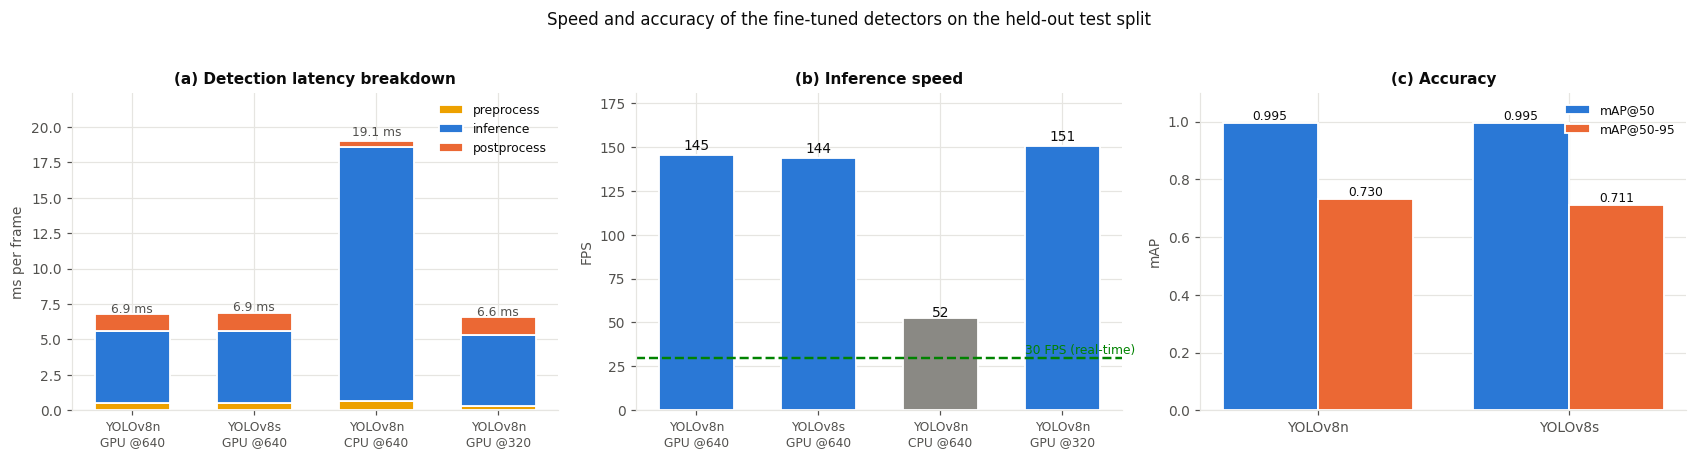

In [28]:
# ---------------------------------------------------- Figure: latency breakdown + speed
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.0))

lab = [f"{r['Model'].replace('Fine-tuned ','')}\n{r['device']} @{int(r['imgsz'])}"
       for _, r in bench_df.iterrows()]
parts = ["preprocess_ms", "inference_ms", "postprocess_ms"]
cols = [PALETTE[3], PALETTE[0], PALETTE[1]]
bot = np.zeros(len(bench_df))
for p, c in zip(parts, cols):
    v = bench_df[p].values
    ax[0].bar(lab, v, bottom=bot, color=c, label=p.replace("_ms", ""),
              edgecolor="white", linewidth=1.2, width=.62)
    bot += v
for i, r in enumerate(bench_df.itertuples()):
    ax[0].text(i, bot[i]*1.02, f"{r.wall_ms:.1f} ms", ha="center", fontsize=8, color=INK2)
ax[0].set_ylabel("ms per frame"); ax[0].set_title("(a) Detection latency breakdown")
ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", labelsize=8)
ax[0].set_ylim(0, bot.max()*1.18)

f = bench_df.FPS.values
b = ax[1].bar(lab, f, color=[PALETTE[0] if d == "GPU" else INK3 for d in bench_df.device],
              edgecolor="white", linewidth=1.2, width=.62)
ax[1].axhline(30, color=PALETTE[5], ls="--", lw=1.6)
ax[1].text(len(f)-.4, 32, "30 FPS (real-time)", fontsize=8, color=PALETTE[5], ha="right")
for r, v in zip(b, f):
    ax[1].text(r.get_x()+r.get_width()/2, v*1.02, f"{v:.0f}", ha="center", fontsize=9)
ax[1].set_ylabel("FPS"); ax[1].set_title("(b) Inference speed")
ax[1].tick_params(axis="x", labelsize=8); ax[1].set_ylim(0, f.max()*1.2)

names = list(EVAL)
w = .38; xs = np.arange(len(names))
ax[2].bar(xs-w/2, [EVAL[n]["mAP50"] for n in names], w, label="mAP@50",
          color=PALETTE[0], edgecolor="white", linewidth=1.2)
ax[2].bar(xs+w/2, [EVAL[n]["mAP50-95"] for n in names], w, label="mAP@50-95",
          color=PALETTE[1], edgecolor="white", linewidth=1.2)
for i, n in enumerate(names):
    ax[2].text(i-w/2, EVAL[n]["mAP50"]+.012, f"{EVAL[n]['mAP50']:.3f}", ha="center", fontsize=8)
    ax[2].text(i+w/2, EVAL[n]["mAP50-95"]+.012, f"{EVAL[n]['mAP50-95']:.3f}", ha="center", fontsize=8)
ax[2].set_xticks(xs); ax[2].set_xticklabels([n.replace("Fine-tuned ", "") for n in names])
ax[2].set_ylim(0, 1.1); ax[2].set_ylabel("mAP"); ax[2].set_title("(c) Accuracy")
ax[2].legend(fontsize=8)

fig.suptitle("Speed and accuracy of the fine-tuned detectors on the held-out test split", y=1.03)
fig.tight_layout()
savefig(fig, "fig12_latency_accuracy")

Precision-Recall curve: outputs/figures/fig13_PR_curve.png


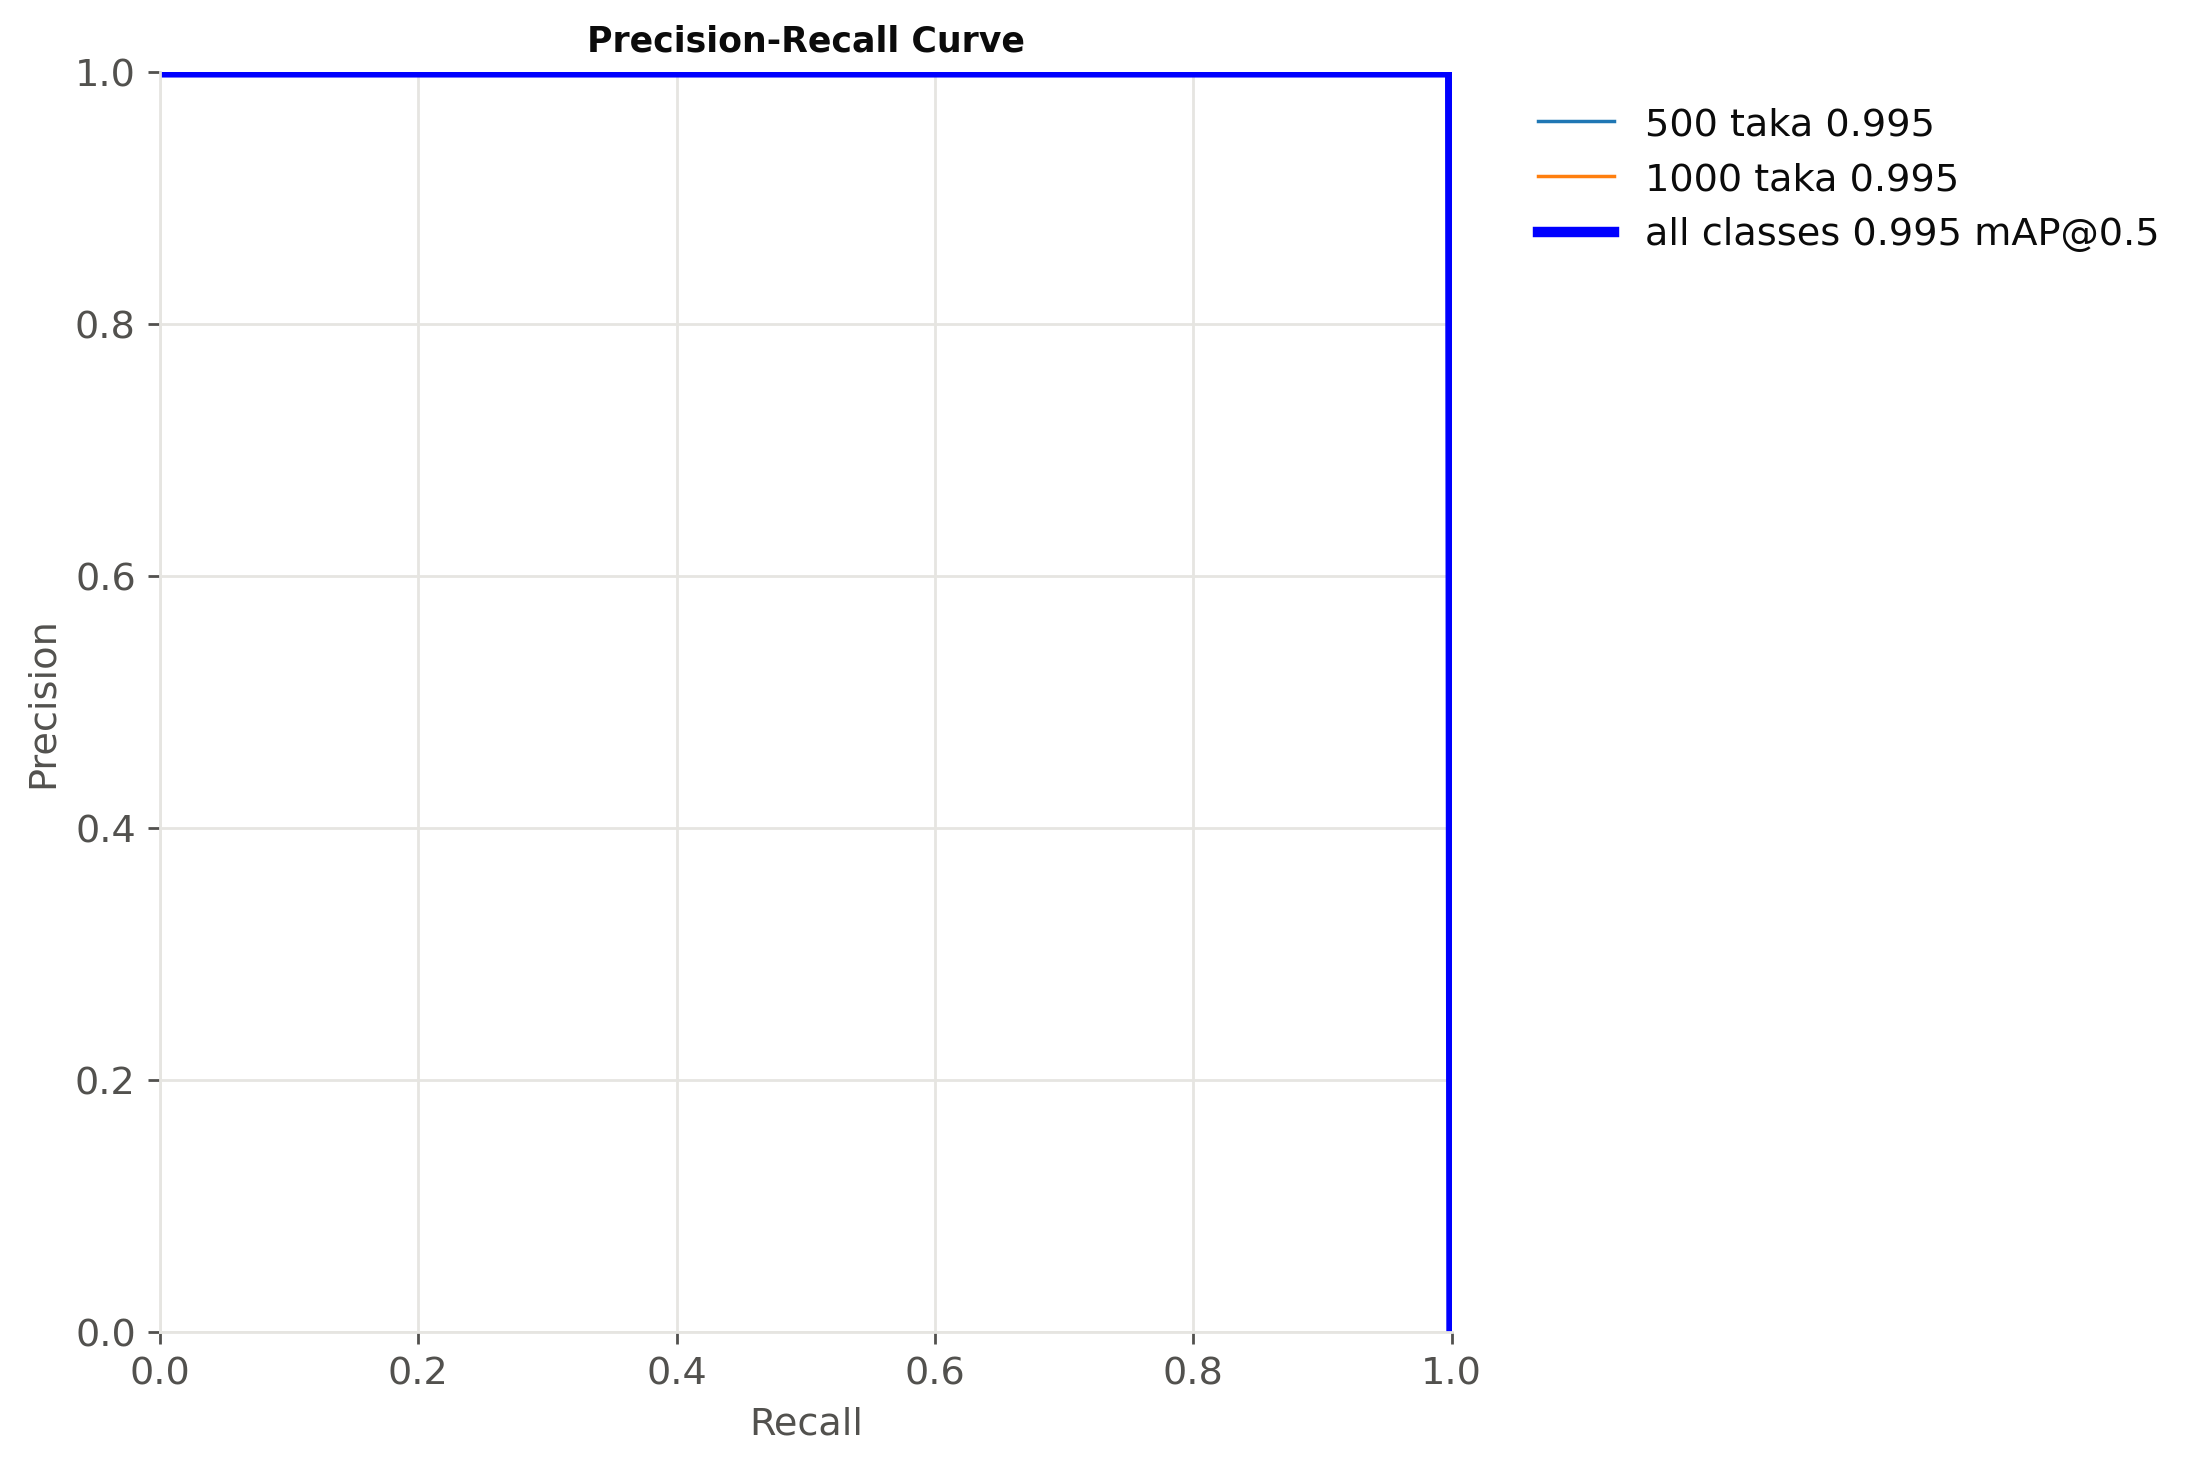

F1 vs confidence: outputs/figures/fig13_F1_curve.png


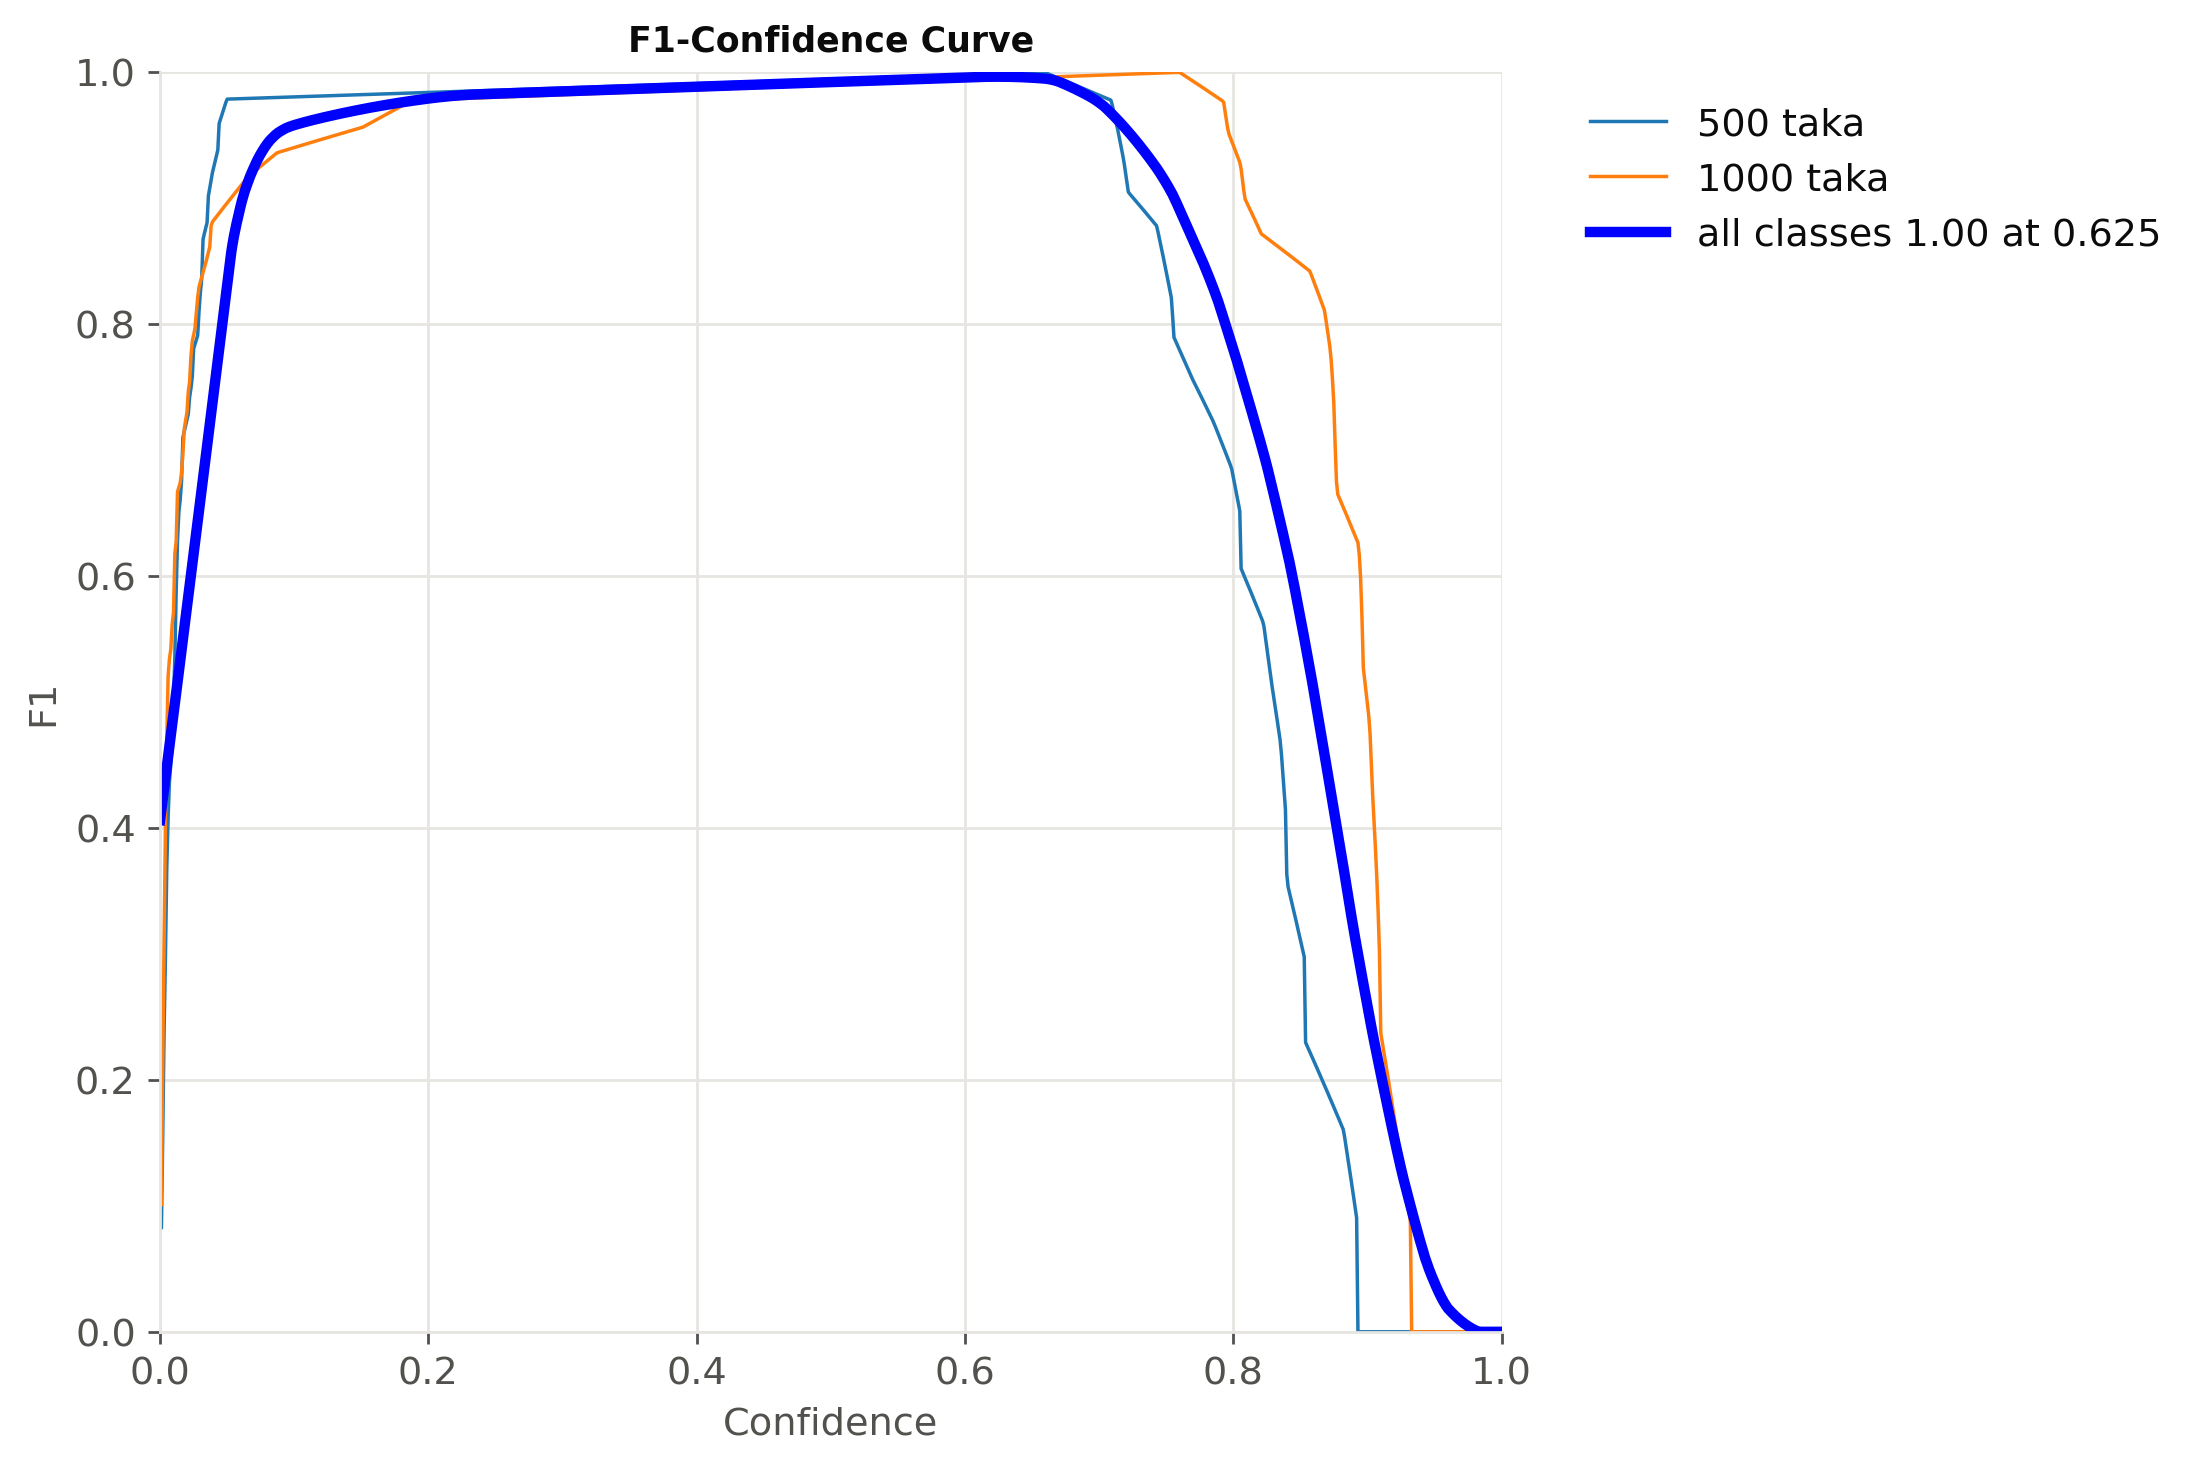

Precision vs confidence: outputs/figures/fig13_P_curve.png


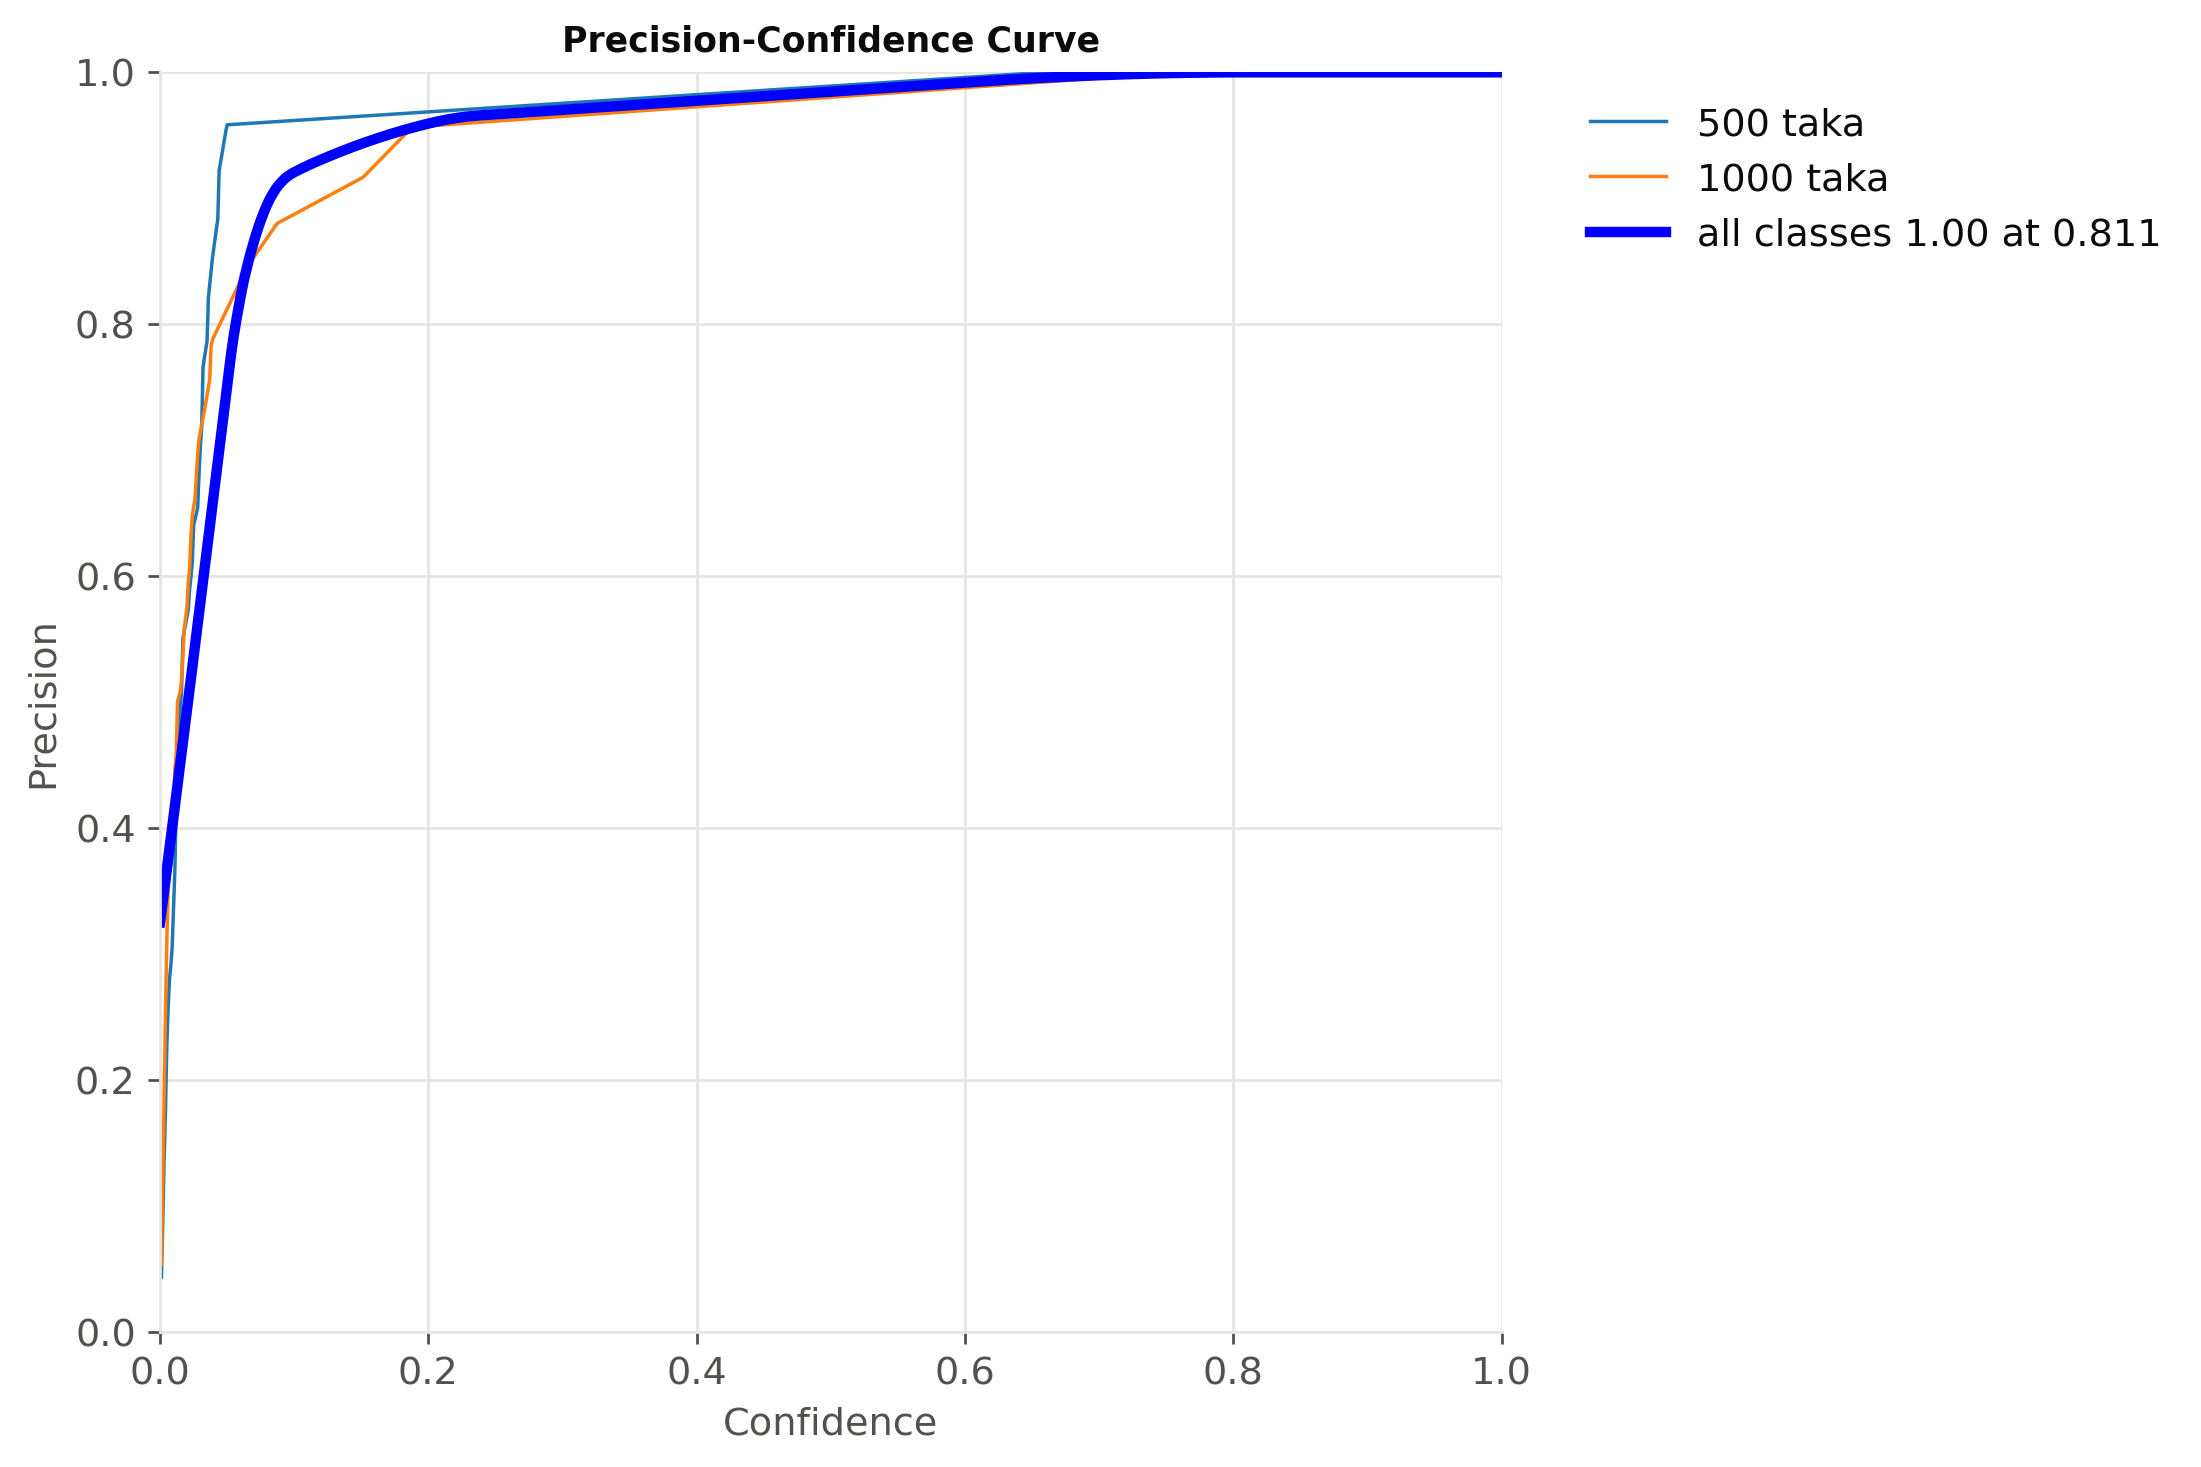

Recall vs confidence: outputs/figures/fig13_R_curve.png


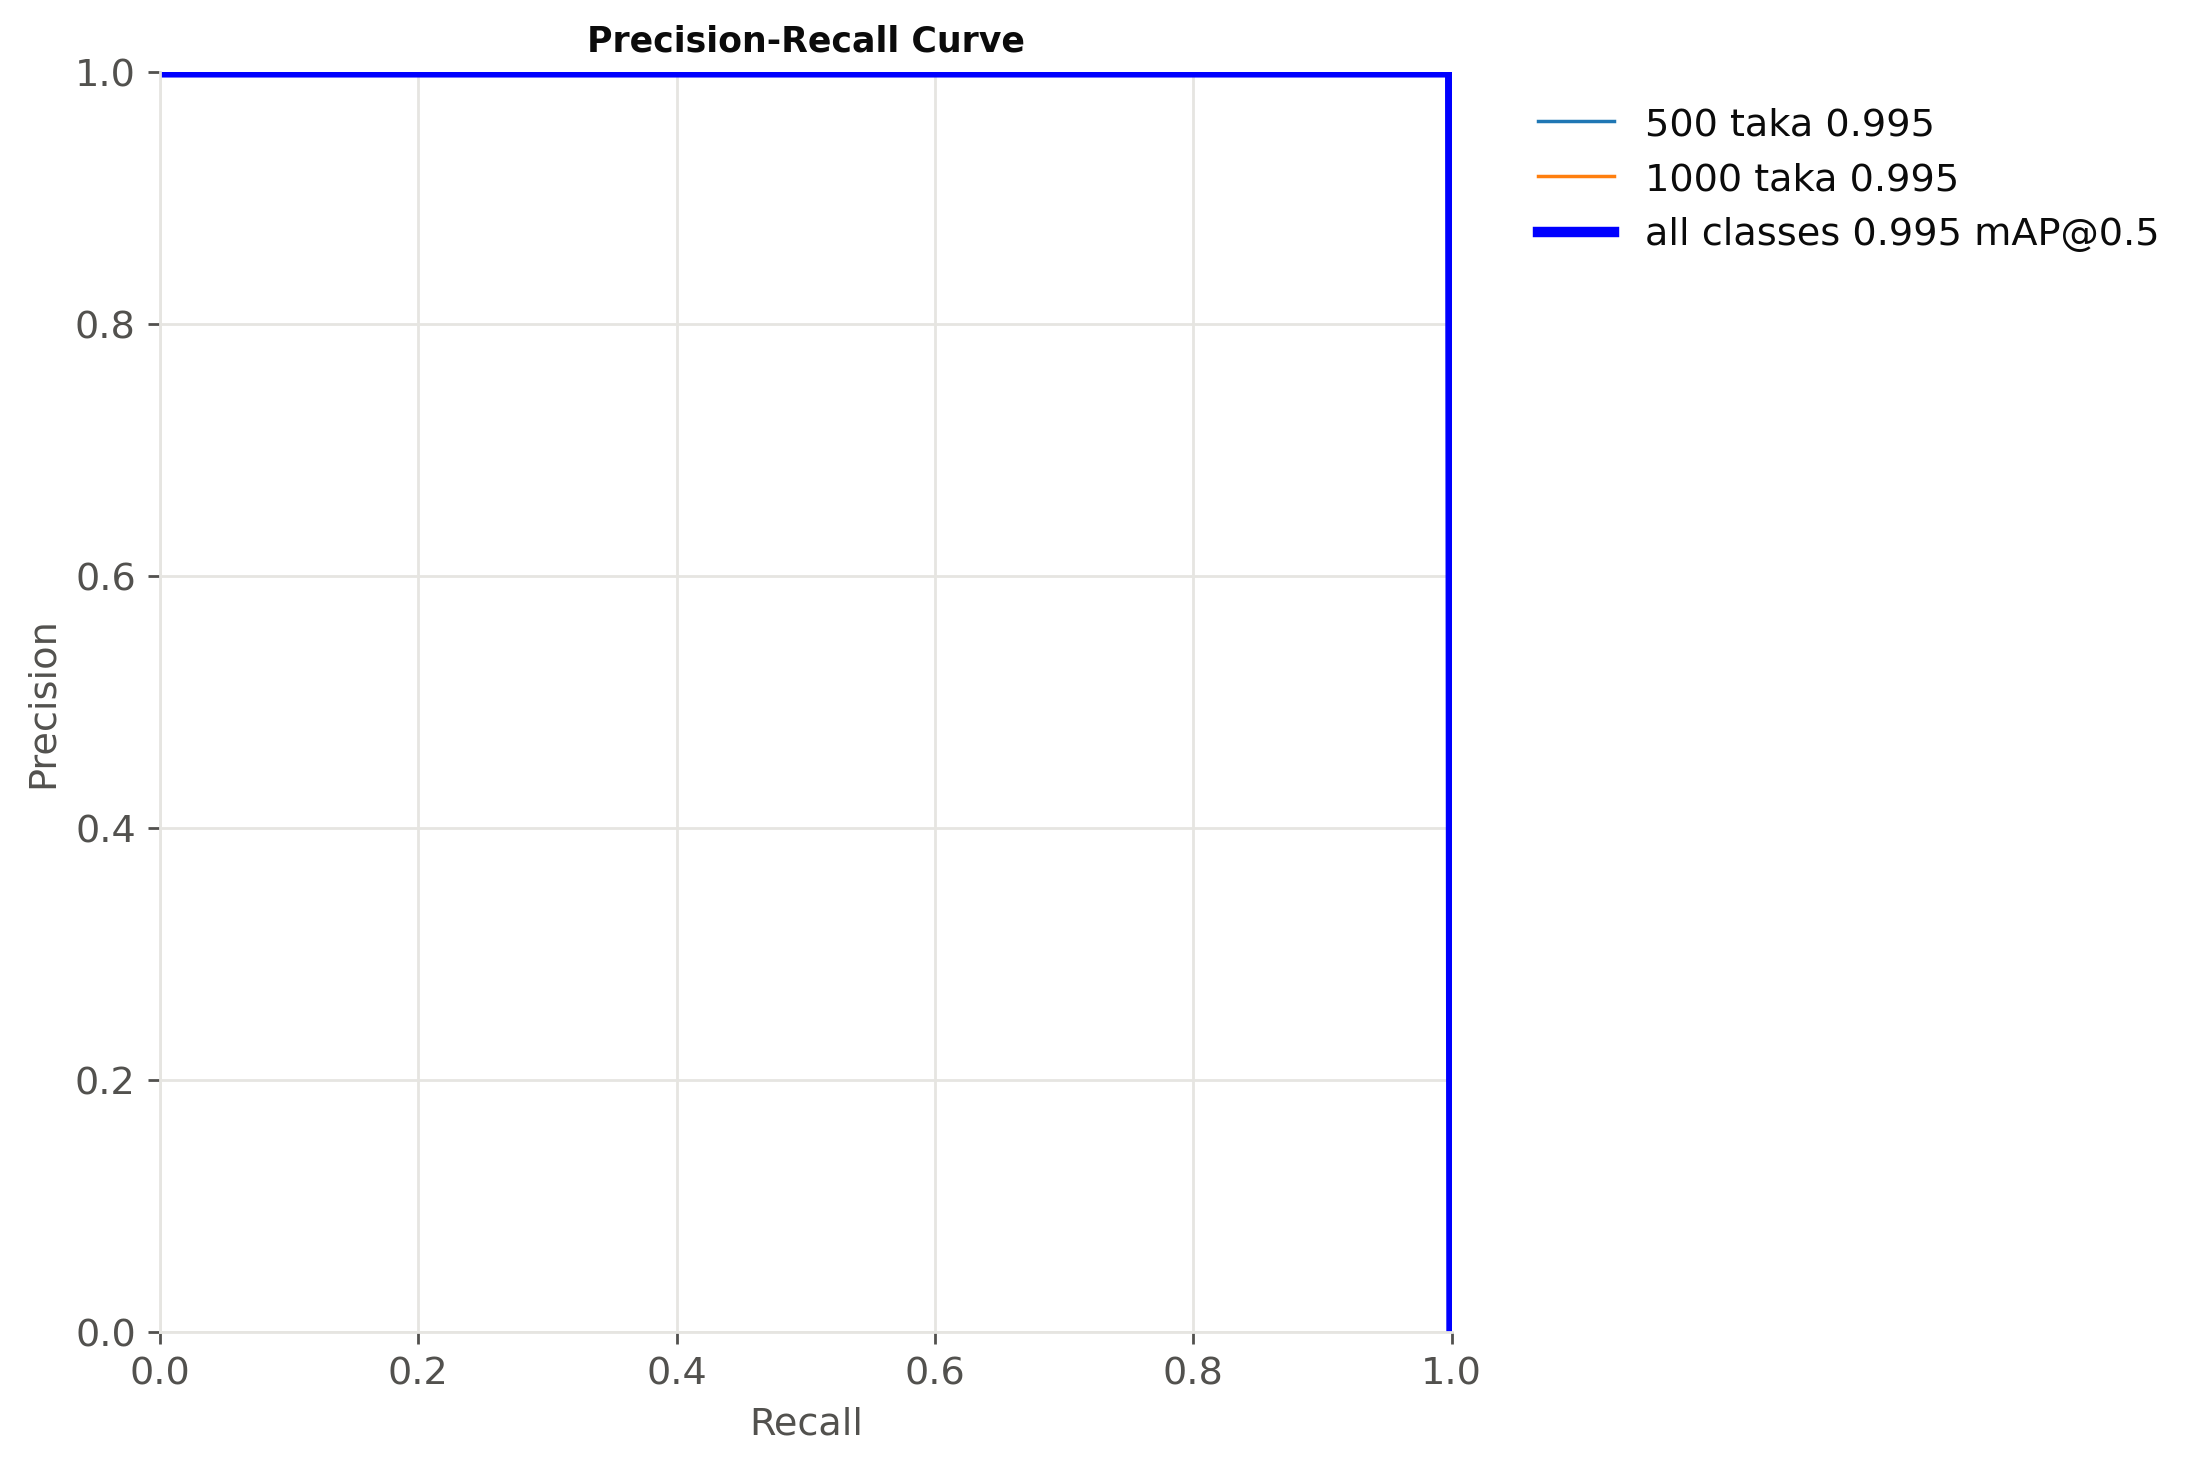

Normalised confusion matrix: outputs/figures/fig13_confusion_matrix_normalized.png


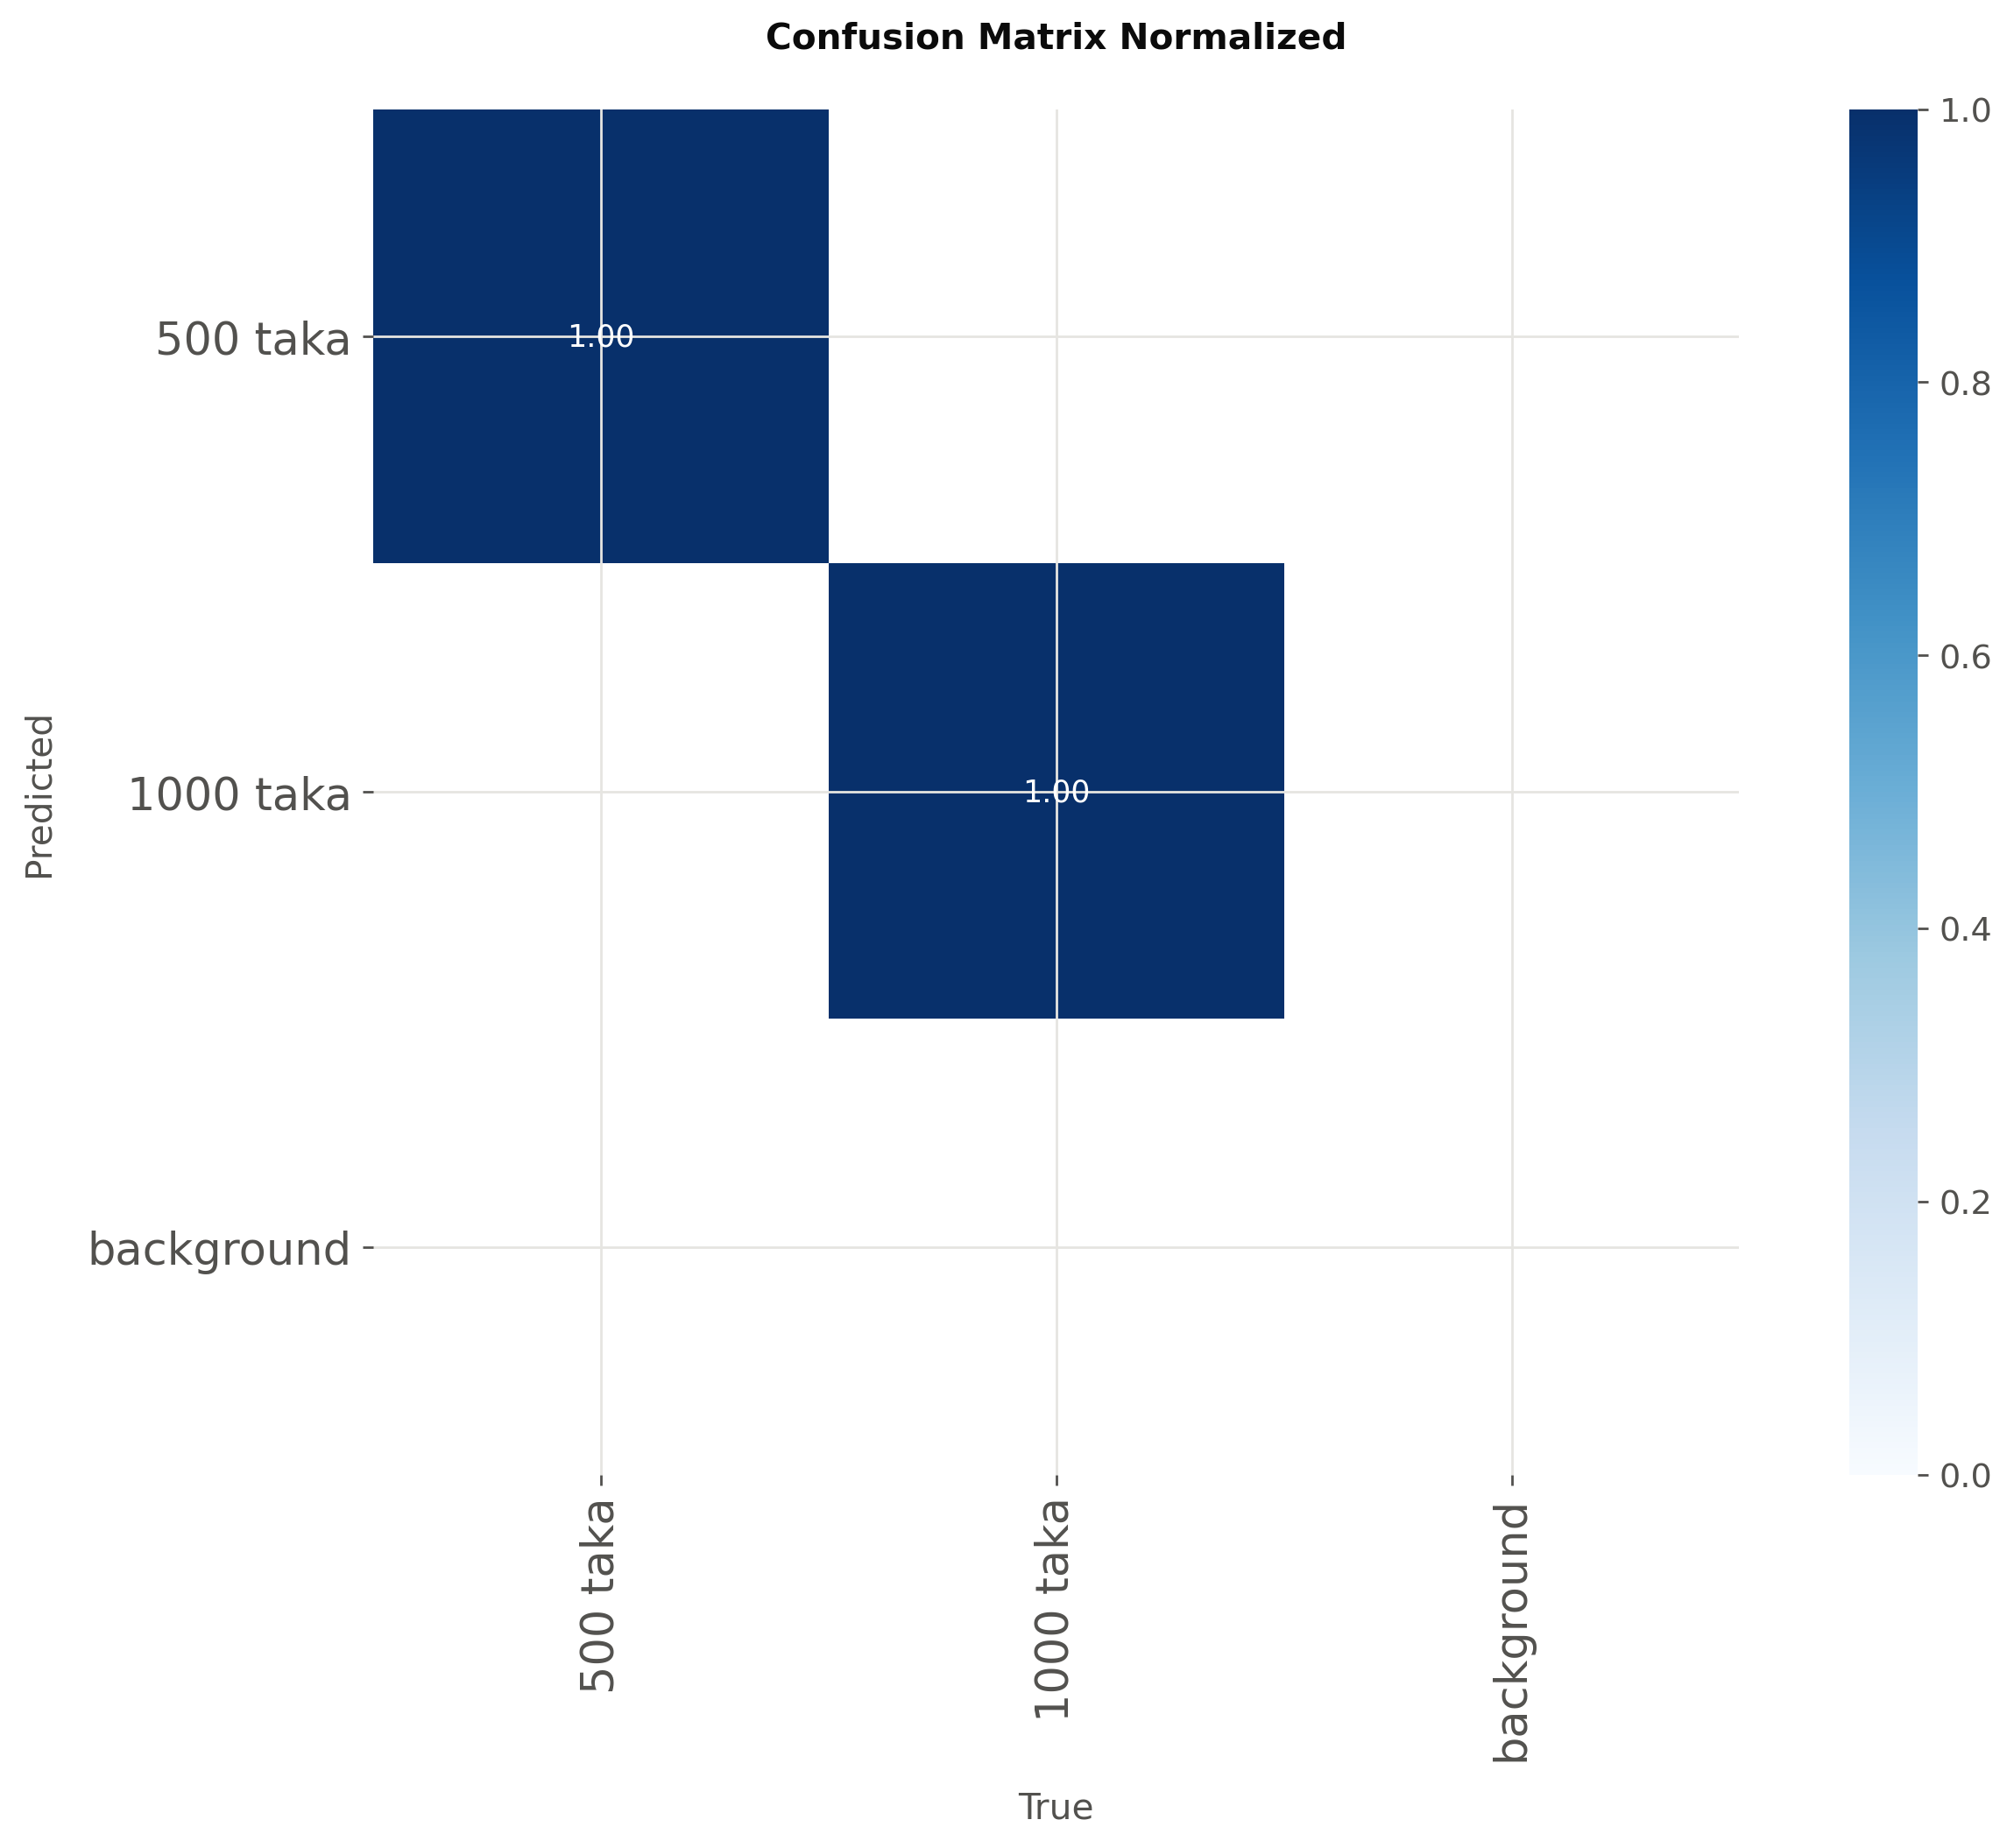

In [29]:
# ---------------------------------------------------- ultralytics' own PR / confusion plots
from IPython.display import Image as IPImage, display as ipydisplay
vdir = RUNS / "val_yolov8n_test"
# ultralytics prefixes detection plots with "Box" (BoxPR_curve.png, not PR_curve.png),
# so match on a suffix rather than an exact name.
wanted = [("PR_curve", "Precision-Recall curve"),
          ("F1_curve", "F1 vs confidence"),
          ("P_curve", "Precision vs confidence"),
          ("R_curve", "Recall vs confidence"),
          ("confusion_matrix_normalized", "Normalised confusion matrix")]
found = {p.stem: p for p in vdir.glob("*.png")} if vdir.exists() else {}
for key, cap in wanted:
    hit = next((p for stem, p in found.items() if stem.endswith(key)), None)
    if hit is None:
        print(f"  (missing: {key})"); continue
    dst = FIG / f"fig13_{key}.png"
    shutil.copy(hit, dst)
    print(f"{cap}: outputs/figures/{dst.name}")
    ipydisplay(IPImage(filename=str(hit), width=520))

---
## 8. Comparison with the original pre-trained model

### 8.1 What this comparison can and cannot show

The stock YOLOv8 is trained on COCO, whose 80 classes contain **no banknote and no currency of any
kind**. So on the taka classes its average precision is $0$ *by construction* --- it has no output
neuron that could ever fire for "500 taka". Reporting "0.000 vs 0.99" and stopping there would be
technically correct and almost completely uninformative.

The evaluation below therefore asks three progressively more interesting questions:

1. **What does the pre-trained model actually predict** on these images? Which COCO classes does it
   reach for, and how often does it output nothing at all?
2. **Does it localise the note even though it cannot name it?** Ignoring labels entirely, do any of
   its boxes overlap the ground-truth note? This is a *class-agnostic* recall, and it separates
   "the detector cannot see the object" from "the detector sees it but has no word for it".
3. **What is the best it could possibly do?** Given an oracle that relabels each of its boxes with
   the correct taka class for free, what mAP would it reach? That is a hard upper bound on what the
   COCO model's localisation alone is worth, and the honest ceiling for the comparison.

In [30]:
def load_gt(split="test"):
    gt = {}
    for lp in sorted((YOLO_DS/"labels"/split).glob("*.txt")):
        ip = YOLO_DS/"images"/split/f"{lp.stem}.jpg"
        im = cv2.imread(str(ip)); h, w = im.shape[:2]
        boxes = []
        for line in lp.read_text().split("\n"):
            if not line.strip(): continue
            cid, xc, yc, bw, bh = line.split(); cid = int(cid)
            xc, yc, bw, bh = (float(v) for v in (xc, yc, bw, bh))
            boxes.append((cid, (xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h))
        gt[str(ip)] = dict(boxes=boxes, w=w, h=h)
    return gt

def iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0, ix2-ix1), max(0, iy2-iy1)
    inter = iw*ih
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/ua if ua > 0 else 0.0

GT = load_gt("test")
print(f"test images: {len(GT)}  ground-truth objects: {sum(len(v['boxes']) for v in GT.values())}")

test images: 45  ground-truth objects: 45


In [31]:
# ---- what does the stock COCO model predict on these images? ----
coco = YOLO(CFG.base_model)
pred_rows, coco_hits = [], Counter()
for path, g in tqdm(GT.items(), desc="pretrained COCO", ncols=78):
    r = coco.predict(path, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    names = r.names
    dets = []
    for b in r.boxes:
        cid = int(b.cls.item()); conf = float(b.conf.item())
        xy = b.xyxy[0].tolist()
        dets.append((names[cid], conf, xy)); coco_hits[names[cid]] += 1
    best = max((iou_xyxy(d[2], g["boxes"][0][1:]) for d in dets), default=0.0)
    pred_rows.append(dict(path=path, n_det=len(dets), best_iou=best,
                          top=dets[0][0] if dets else "(nothing)"))
coco_df = pd.DataFrame(pred_rows)

print(f"\nimages where the COCO model output NOTHING at conf>={CFG.conf_show}: "
      f"{int((coco_df.n_det==0).sum())}/{len(coco_df)} "
      f"({(coco_df.n_det==0).mean()*100:.0f}%)")
print(f"mean detections per image: {coco_df.n_det.mean():.2f}")
print("\nCOCO classes it reached for:")
for k, v in coco_hits.most_common(10):
    print(f"   {k:16s} {v}")
print(f"\nclass-agnostic localisation (ignoring labels entirely):")
for t in [0.3, 0.5, 0.75]:
    print(f"   recall @IoU>={t}: {(coco_df.best_iou>=t).mean()*100:5.1f}%")
print(f"   mean best IoU: {coco_df.best_iou.mean():.3f}")
coco_df.to_csv(RES/"pretrained_predictions.csv", index=False)
del coco

pretrained COCO:   0%|                                 | 0/45 [00:00<?, ?it/s]

pretrained COCO:   7%|█▋                       | 3/45 [00:00<00:01, 29.44it/s]

pretrained COCO:  31%|███████▍                | 14/45 [00:00<00:00, 74.49it/s]

pretrained COCO:  56%|█████████████▎          | 25/45 [00:00<00:00, 88.16it/s]

pretrained COCO:  78%|██████████████████▋     | 35/45 [00:00<00:00, 89.90it/s]

pretrained COCO: 100%|████████████████████████| 45/45 [00:00<00:00, 87.20it/s]


images where the COCO model output NOTHING at conf>=0.25: 9/45 (20%)
mean detections per image: 1.07

COCO classes it reached for:
   book             32
   person           13
   tv               2
   tie              1

class-agnostic localisation (ignoring labels entirely):
   recall @IoU>=0.3:  75.6%
   recall @IoU>=0.5:  75.6%
   recall @IoU>=0.75:  68.9%
   mean best IoU: 0.663


In [32]:
# ---- oracle upper bound: relabel every COCO box with the correct class for free ----
def ap_from_scores(scores, matched, n_gt):
    # standard 101-point interpolated AP
    o = np.argsort(-np.asarray(scores)); m = np.asarray(matched)[o]
    tp = np.cumsum(m); fp = np.cumsum(1-m)
    rec = tp/max(n_gt, 1); prec = tp/np.maximum(tp+fp, 1e-9)
    ap = 0.0
    for t in np.linspace(0, 1, 101):
        p = prec[rec >= t].max() if np.any(rec >= t) else 0.0
        ap += p/101
    return ap

coco = YOLO(CFG.base_model)
orc = {0.5: [], 0.75: []}
scores_all, gtn = [], 0
raw = []
for path, g in tqdm(GT.items(), desc="oracle bound", ncols=78):
    r = coco.predict(path, imgsz=CFG.imgsz, conf=0.001, device=DEV, verbose=False)[0]
    gt_box = g["boxes"][0][1:]; gtn += 1
    dets = sorted([(float(b.conf.item()), b.xyxy[0].tolist()) for b in r.boxes],
                  key=lambda t: -t[0])[:20]
    raw.append((path, dets, gt_box))
for thr in [0.5, 0.75]:
    sc, mt = [], []
    for path, dets, gt_box in raw:
        used = False
        for conf, xy in dets:
            hit = (not used) and iou_xyxy(xy, gt_box) >= thr
            if hit: used = True
            sc.append(conf); mt.append(1 if hit else 0)
    orc[thr] = ap_from_scores(sc, mt, gtn)
print(f"\nORACLE upper bound for the pre-trained model (labels granted for free):")
print(f"   AP@50  = {orc[0.5]:.4f}")
print(f"   AP@75  = {orc[0.75]:.4f}")
print("With its real COCO labels it scores 0.0000 on both taka classes, because no COCO class")
print("corresponds to a banknote.")
del coco

oracle bound:   0%|                                    | 0/45 [00:00<?, ?it/s]

oracle bound:   7%|█▊                          | 3/45 [00:00<00:01, 30.00it/s]

oracle bound:  29%|███████▊                   | 13/45 [00:00<00:00, 67.39it/s]

oracle bound:  51%|█████████████▊             | 23/45 [00:00<00:00, 81.47it/s]

oracle bound:  71%|███████████████████▏       | 32/45 [00:00<00:00, 83.79it/s]

oracle bound:  91%|████████████████████████▌  | 41/45 [00:00<00:00, 85.61it/s]

oracle bound: 100%|███████████████████████████| 45/45 [00:00<00:00, 79.31it/s]


ORACLE upper bound for the pre-trained model (labels granted for free):
   AP@50  = 0.7040
   AP@75  = 0.5788
With its real COCO labels it scores 0.0000 on both taka classes, because no COCO class
corresponds to a banknote.


In [33]:
# ---- assemble the comparison table ----
PRE = {"Model": "Pre-trained (COCO)", "Precision": 0.0, "Recall": 0.0,
       "mAP50": 0.0, "mAP50-95": 0.0, "F1": 0.0}
for c in CLASS_NAMES:
    PRE[f"AP50[{c}]"] = 0.0; PRE[f"AP[{c}]"] = 0.0
pb = benchmark(CFG.base_model, "Pre-trained (COCO)", device=DEV)
PRE.update(speed_total_ms=pb["wall_ms"], FPS_val=pb["FPS"])
EVAL["Pre-trained (COCO)"] = PRE

order = ["Pre-trained (COCO)", "Fine-tuned YOLOv8n", "Fine-tuned YOLOv8s"]
cmp_df = pd.DataFrame([{
    "Model": n,
    "Precision": round(EVAL[n]["Precision"], 4),
    "Recall": round(EVAL[n]["Recall"], 4),
    "F1": round(EVAL[n]["F1"], 4),
    "mAP@50": round(EVAL[n]["mAP50"], 4),
    "mAP@50-95": round(EVAL[n]["mAP50-95"], 4),
    "AP50 500": round(EVAL[n]["AP50[500 taka]"], 4),
    "AP50 1000": round(EVAL[n]["AP50[1000 taka]"], 4),
} for n in order])
cmp_df.to_csv(RES/"comparison.csv", index=False)
display(cmp_df)

extra = pd.DataFrame([
    {"quantity": "images with zero detections (conf>=0.25)",
     "pre-trained": f"{(coco_df.n_det==0).mean()*100:.0f}%", "fine-tuned": "see §9"},
    {"quantity": "class-agnostic recall @IoU>=0.5",
     "pre-trained": f"{(coco_df.best_iou>=0.5).mean()*100:.1f}%", "fine-tuned": "-"},
    {"quantity": "mean best IoU with the note",
     "pre-trained": f"{coco_df.best_iou.mean():.3f}", "fine-tuned": "-"},
    {"quantity": "ORACLE AP@50 (labels granted free)",
     "pre-trained": f"{orc[0.5]:.4f}", "fine-tuned": f"{EVAL['Fine-tuned YOLOv8n']['mAP50']:.4f}"},
])
extra.to_csv(RES/"pretrained_diagnostics.csv", index=False)
display(extra)

,Model,Precision,Recall,F1,mAP@50,mAP@50-95,AP50 500,AP50 1000
0,Pre-trained (COCO),0.0000,0.0,0.0000,0.000,0.0000,0.000,0.000
1,Fine-tuned YOLOv8n,0.9937,1.0,0.9968,0.995,0.7303,0.995,0.995
2,Fine-tuned YOLOv8s,0.9958,1.0,0.9979,0.995,0.7113,0.995,0.995


,quantity,pre-trained,fine-tuned
0,images with zero detections (conf>=0.25),20%,see §9
1,class-agnostic recall @IoU>=0.5,75.6%,-
2,mean best IoU with the note,0.663,-
3,ORACLE AP@50 (labels granted free),0.7040,0.9950


  saved -> outputs/figures/fig14_pretrained_vs_finetuned.png


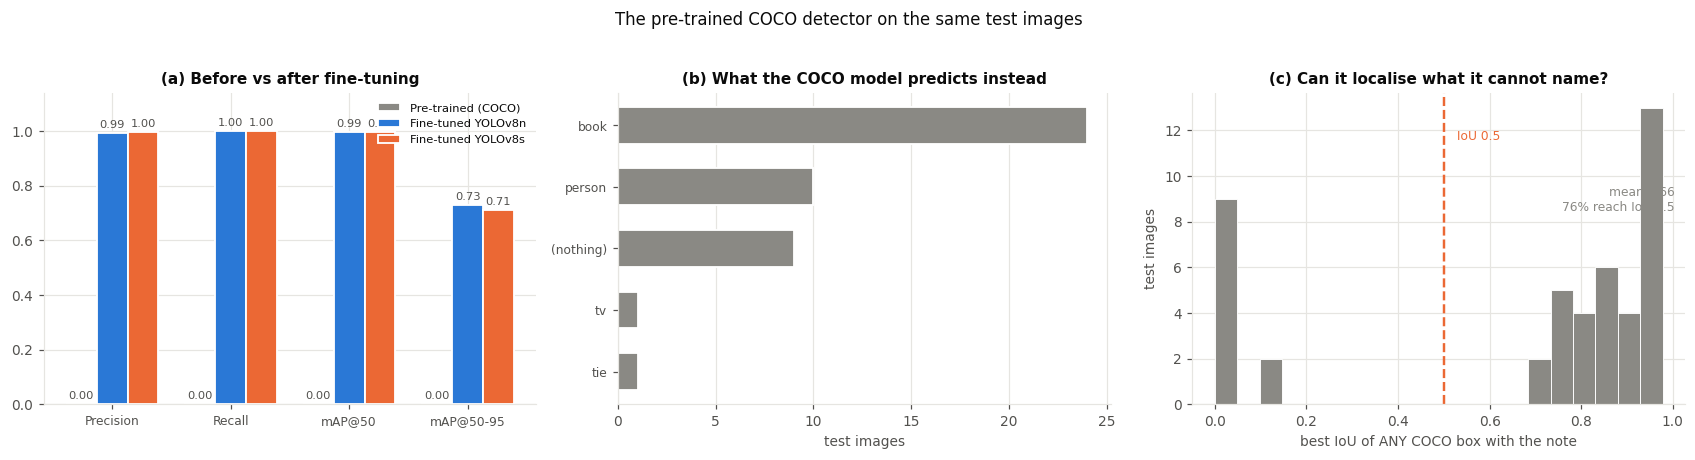

In [34]:
# ---------------------------------------------------- Figure: pretrained vs fine-tuned
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.0))

mets = ["Precision", "Recall", "mAP@50", "mAP@50-95"]
xs = np.arange(len(mets)); w = 0.26
for i, n in enumerate(order):
    v = [cmp_df.loc[cmp_df.Model == n, m].iloc[0] for m in mets]
    ax[0].bar(xs + (i-1)*w, v, w, color=MODEL_COLOR[n], label=n,
              edgecolor="white", linewidth=1.2)
    for x, vv in zip(xs + (i-1)*w, v):
        ax[0].text(x, vv + .02, f"{vv:.2f}", ha="center", fontsize=7.5, color=INK2)
ax[0].set_xticks(xs); ax[0].set_xticklabels(mets, fontsize=8)
ax[0].set_ylim(0, 1.14); ax[0].set_title("(a) Before vs after fine-tuning")
ax[0].legend(fontsize=7.5)

top = coco_df.top.value_counts().head(7)
ax[1].barh(np.arange(len(top))[::-1], top.values, color=INK3,
           edgecolor="white", linewidth=1.2, height=.6)
ax[1].set_yticks(np.arange(len(top))[::-1]); ax[1].set_yticklabels(top.index, fontsize=8)
ax[1].set_xlabel("test images"); ax[1].set_title("(b) What the COCO model predicts instead")
ax[1].grid(axis="y", visible=False)

ax[2].hist(coco_df.best_iou, bins=20, color=INK3, edgecolor="white", linewidth=.6)
ax[2].axvline(0.5, color=PALETTE[1], ls="--", lw=1.6)
ax[2].text(0.52, ax[2].get_ylim()[1]*.85, " IoU 0.5", fontsize=8, color=PALETTE[1])
ax[2].set_xlabel("best IoU of ANY COCO box with the note")
ax[2].set_ylabel("test images")
ax[2].set_title("(c) Can it localise what it cannot name?")
ax[2].text(.98, .62, f"mean {coco_df.best_iou.mean():.2f}\n"
                     f"{(coco_df.best_iou>=0.5).mean()*100:.0f}% reach IoU 0.5",
           transform=ax[2].transAxes, ha="right", fontsize=8, color=INK3)

fig.suptitle("The pre-trained COCO detector on the same test images", y=1.03)
fig.tight_layout()
savefig(fig, "fig14_pretrained_vs_finetuned")

  saved -> outputs/figures/fig15_side_by_side.png


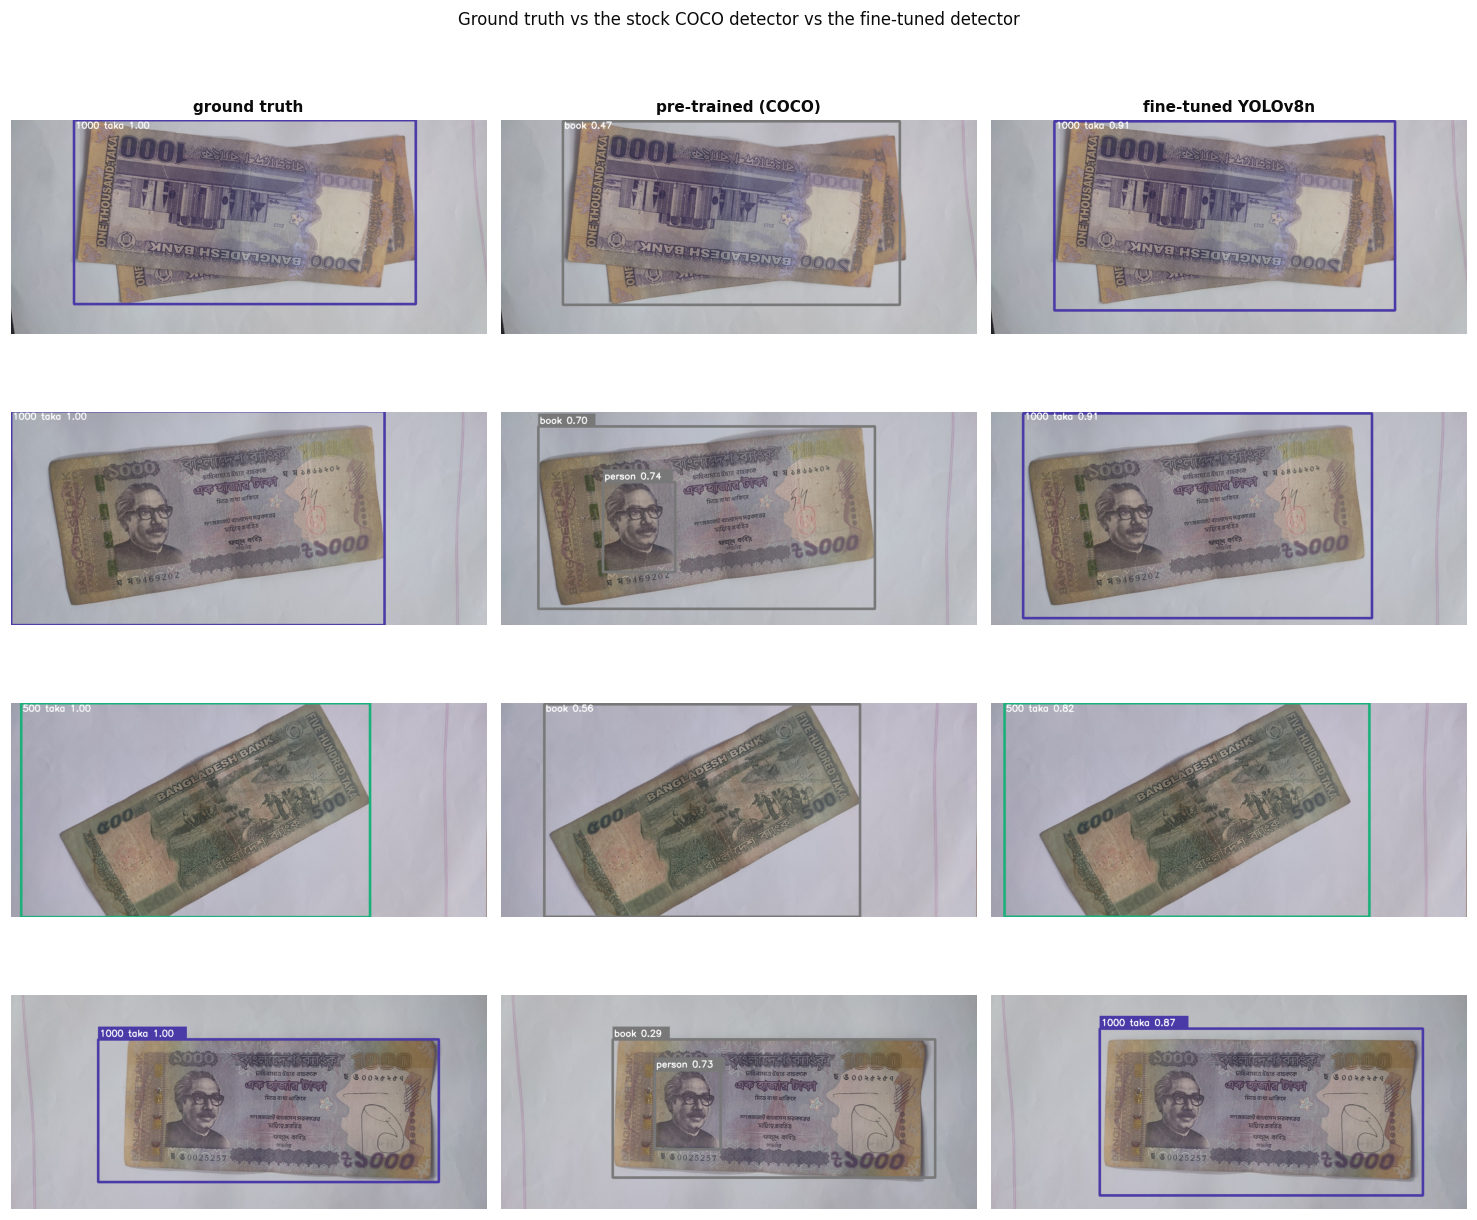

In [35]:
# ---------------------------------------------------- Figure: side-by-side detections
coco = YOLO(CFG.base_model); ft = YOLO(str(BEST_N))
paths = sorted(GT.keys())
set_seed(6); pick = [paths[i] for i in np.random.choice(len(paths), 4, replace=False)]

def draw(img, dets, color_fn, thick=5):
    out = img.copy()
    for lbl, conf, xy in dets:
        x1, y1, x2, y2 = [int(v) for v in xy]
        c = color_fn(lbl)
        cv2.rectangle(out, (x1, y1), (x2, y2), c, thick)
        t = f"{lbl} {conf:.2f}"
        cv2.rectangle(out, (x1, max(0, y1-34)), (x1+len(t)*17, y1), c, -1)
        cv2.putText(out, t, (x1+4, max(22, y1-8)), cv2.FONT_HERSHEY_SIMPLEX, .8, (255, 255, 255), 2)
    return out

fig, axes = plt.subplots(len(pick), 3, figsize=(13.5, 2.9*len(pick)))
for r, p in enumerate(pick):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    g = GT[p]["boxes"][0]
    gt_img = draw(im, [(CLASS_NAMES[g[0]], 1.0, g[1:])], lambda l: hex2bgr(CLS_COLOR[l])[::-1])
    rc = coco.predict(p, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    cdets = [(rc.names[int(b.cls)], float(b.conf), b.xyxy[0].tolist()) for b in rc.boxes]
    rf = ft.predict(p, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    fdets = [(rf.names[int(b.cls)], float(b.conf), b.xyxy[0].tolist()) for b in rf.boxes]
    for c, (img, title) in enumerate([(gt_img, "ground truth"),
                                      (draw(im, cdets, lambda l: (120, 120, 120)), "pre-trained (COCO)"),
                                      (draw(im, fdets, lambda l: hex2bgr(CLS_COLOR[l])[::-1]), "fine-tuned YOLOv8n")]):
        axes[r, c].imshow(img); no_axes(axes[r, c])
        if r == 0: axes[r, c].set_title(title, fontsize=10)
    if not cdets:
        axes[r, 1].text(.5, .5, "no detection", transform=axes[r, 1].transAxes,
                        ha="center", va="center", fontsize=13, color=PALETTE[7], fontweight="bold")
fig.suptitle("Ground truth vs the stock COCO detector vs the fine-tuned detector", y=1.0)
fig.tight_layout()
savefig(fig, "fig15_side_by_side")
del coco, ft

---
## 9. Performance analysis

### 9.1 Qualitative detection results

  saved -> outputs/figures/fig16_qualitative.png


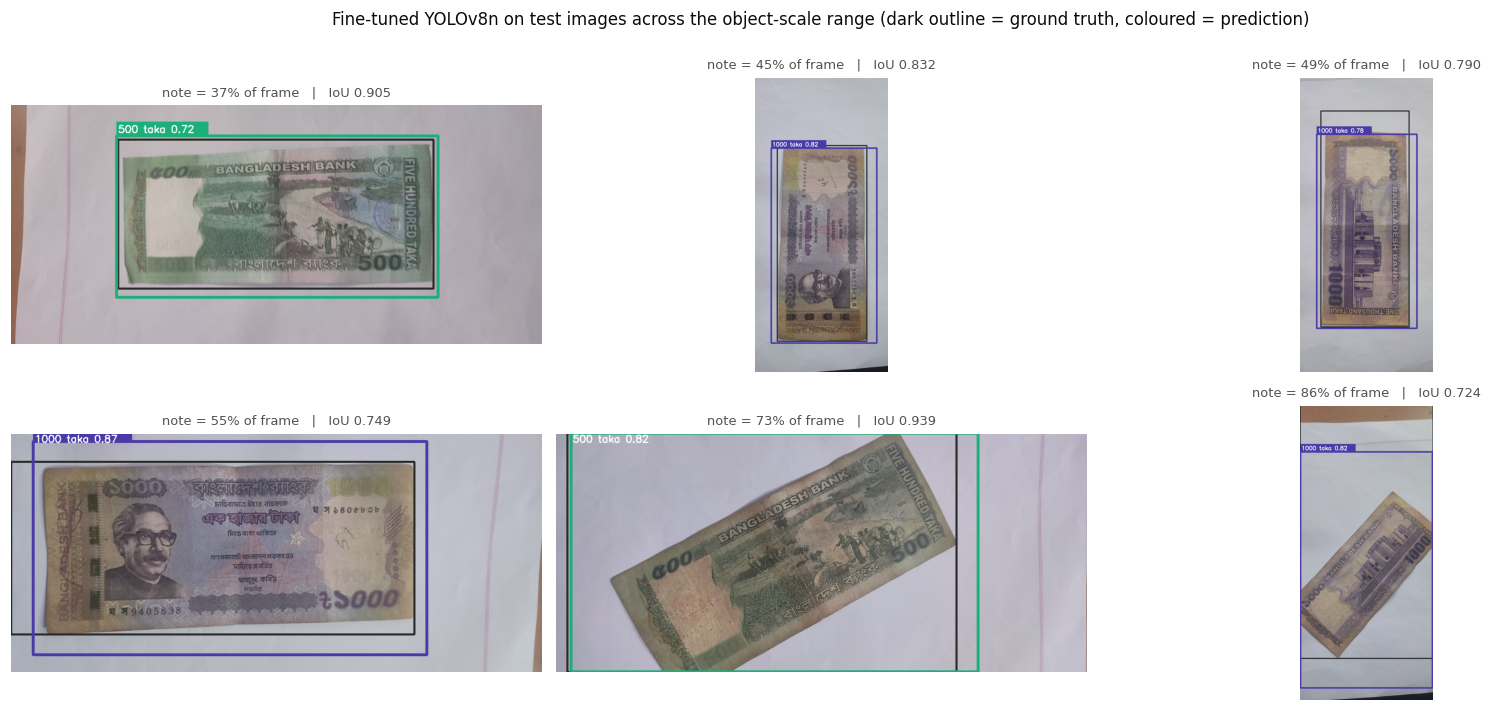

In [36]:
ft = YOLO(str(BEST_N))
paths = sorted(GT.keys())
order_by_area = sorted(paths, key=lambda p: (GT[p]["boxes"][0][3]-GT[p]["boxes"][0][1]) *
                                            (GT[p]["boxes"][0][4]-GT[p]["boxes"][0][2]))
pick = [order_by_area[int(q*(len(order_by_area)-1))] for q in (0.02, 0.2, 0.4, 0.6, 0.8, 0.98)]

fig, axes = plt.subplots(2, 3, figsize=(15, 6.4))
for ax, p in zip(axes.ravel(), pick):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    g = GT[p]["boxes"][0]
    cv2.rectangle(im, (int(g[1]), int(g[2])), (int(g[3]), int(g[4])), (40, 40, 40), 3)
    r = ft.predict(p, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    best = 0.0
    for b in r.boxes:
        lbl = r.names[int(b.cls)]; conf = float(b.conf); xy = b.xyxy[0].tolist()
        best = max(best, iou_xyxy(xy, g[1:]))
        c = hex2bgr(CLS_COLOR[lbl])[::-1]
        cv2.rectangle(im, (int(xy[0]), int(xy[1])), (int(xy[2]), int(xy[3])), c, 5)
        t = f"{lbl} {conf:.2f}"
        cv2.rectangle(im, (int(xy[0]), max(0, int(xy[1])-34)),
                      (int(xy[0])+len(t)*17, int(xy[1])), c, -1)
        cv2.putText(im, t, (int(xy[0])+4, max(22, int(xy[1])-8)),
                    cv2.FONT_HERSHEY_SIMPLEX, .8, (255, 255, 255), 2)
    ax.imshow(im); no_axes(ax)
    rel = (g[3]-g[1])*(g[4]-g[2])/(GT[p]["w"]*GT[p]["h"])
    ax.set_title(f"note = {rel*100:.0f}% of frame   |   IoU {best:.3f}", fontsize=8.5, color=INK2,
                 fontweight="normal")
fig.suptitle("Fine-tuned YOLOv8n on test images across the object-scale range "
             "(dark outline = ground truth, coloured = prediction)", y=1.0)
fig.tight_layout()
savefig(fig, "fig16_qualitative")

### 9.2 Error analysis --- where does it go wrong?

Per-image errors at the operating confidence (0.25), classified into four cases: a correct
detection (right class, IoU >= 0.5), a **misclassification** (box found but wrong denomination), a
**false negative** (nothing found), and **false positives** (extra boxes beyond the one true note).

In [37]:
err = []
for p in tqdm(paths, desc="error analysis", ncols=78):
    g = GT[p]["boxes"][0]; gid, gbox = g[0], g[1:]
    r = ft.predict(p, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    dets = [(int(b.cls), float(b.conf), b.xyxy[0].tolist()) for b in r.boxes]
    dets.sort(key=lambda d: -d[1])
    best_iou, best_cls, best_conf = 0.0, None, 0.0
    for cid, conf, xy in dets:
        i = iou_xyxy(xy, gbox)
        if i > best_iou:
            best_iou, best_cls, best_conf = i, cid, conf
    if not dets:
        case = "false negative"
    elif best_iou < 0.5:
        case = "poor localisation"
    elif best_cls != gid:
        case = "misclassified"
    else:
        case = "correct"
    err.append(dict(path=p, gt_cls=CLASS_NAMES[gid], n_det=len(dets), case=case,
                    best_iou=best_iou, conf=best_conf,
                    rel_area=(gbox[2]-gbox[0])*(gbox[3]-gbox[1])/(GT[p]["w"]*GT[p]["h"]),
                    extra_fp=max(0, len(dets)-1)))
err_df = pd.DataFrame(err)
err_df.to_csv(RES/"error_analysis.csv", index=False)
print(err_df.case.value_counts().to_string())
print(f"\nextra false positives (beyond the one true note): {int(err_df.extra_fp.sum())} "
      f"across {len(err_df)} images")
print(f"mean IoU of the best matching box: {err_df.best_iou.mean():.4f}")
print(f"mean confidence: {err_df.conf.mean():.4f}")

error analysis:   0%|                                  | 0/45 [00:00<?, ?it/s]

error analysis:  24%|█████▊                  | 11/45 [00:00<00:00, 101.81it/s]

error analysis:  49%|███████████▋            | 22/45 [00:00<00:00, 102.62it/s]

error analysis:  73%|█████████████████▌      | 33/45 [00:00<00:00, 103.52it/s]

error analysis:  98%|███████████████████████▍| 44/45 [00:00<00:00, 105.77it/s]

error analysis: 100%|████████████████████████| 45/45 [00:00<00:00, 104.57it/s]

case
correct    45

extra false positives (beyond the one true note): 1 across 45 images
mean IoU of the best matching box: 0.8455
mean confidence: 0.8082


  saved -> outputs/figures/fig17_error_analysis.png


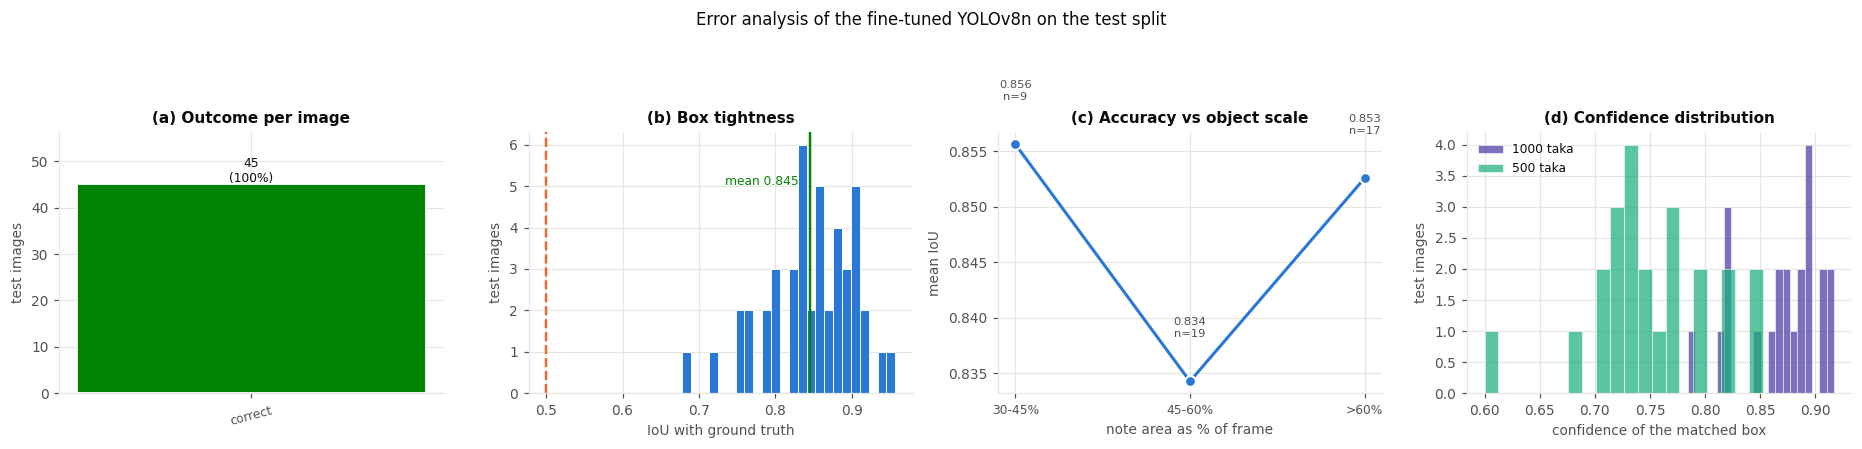

In [38]:
# ---------------------------------------------------- Figure: error analysis
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
CASE_COL = {"correct": PALETTE[5], "misclassified": PALETTE[3],
            "poor localisation": PALETTE[1], "false negative": PALETTE[7]}
vc = err_df.case.value_counts()
b = ax[0].bar(range(len(vc)), vc.values, color=[CASE_COL.get(k, INK3) for k in vc.index],
              edgecolor="white", linewidth=1.2, width=.62)
for r_, v in zip(b, vc.values):
    ax[0].text(r_.get_x()+r_.get_width()/2, v+.5, f"{v}\n({v/len(err_df)*100:.0f}%)",
               ha="center", fontsize=8)
ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index, fontsize=8, rotation=15)
ax[0].set_ylabel("test images"); ax[0].set_title("(a) Outcome per image")
ax[0].set_ylim(0, vc.max()*1.25)

ax[1].hist(err_df.best_iou, bins=24, color=PALETTE[0], edgecolor="white", linewidth=.6)
ax[1].axvline(0.5, color=PALETTE[1], ls="--", lw=1.6)
ax[1].axvline(err_df.best_iou.mean(), color=PALETTE[5], lw=1.6)
ax[1].text(err_df.best_iou.mean()-.01, ax[1].get_ylim()[1]*.8,
           f"mean {err_df.best_iou.mean():.3f} ", ha="right", fontsize=8, color=PALETTE[5])
ax[1].set_xlabel("IoU with ground truth"); ax[1].set_ylabel("test images")
ax[1].set_title("(b) Box tightness")

bins = [0, .15, .3, .45, .6, 1.01]
lab = ["<15%", "15-30%", "30-45%", "45-60%", ">60%"]
err_df["bin"] = pd.cut(err_df.rel_area, bins=bins, labels=lab)
gb = err_df.groupby("bin", observed=True).agg(iou=("best_iou", "mean"), n=("best_iou", "size"))
ax[2].plot(range(len(gb)), gb.iou, marker="o", markersize=7, color=PALETTE[0],
           markeredgecolor="white", markeredgewidth=1.3)
for i, (v, n) in enumerate(zip(gb.iou, gb.n)):
    ax[2].text(i, v+.004, f"{v:.3f}\nn={n}", ha="center", fontsize=7.5, color=INK2)
ax[2].set_xticks(range(len(gb))); ax[2].set_xticklabels(gb.index, fontsize=8)
ax[2].set_xlabel("note area as % of frame"); ax[2].set_ylabel("mean IoU")
ax[2].set_title("(c) Accuracy vs object scale")

for cls, g in err_df.groupby("gt_cls"):
    ax[3].hist(g.conf, bins=20, alpha=.72, color=CLS_COLOR[cls], label=cls,
               edgecolor="white", linewidth=.5)
ax[3].set_xlabel("confidence of the matched box"); ax[3].set_ylabel("test images")
ax[3].set_title("(d) Confidence distribution"); ax[3].legend(fontsize=8)

fig.suptitle("Error analysis of the fine-tuned YOLOv8n on the test split", y=1.03)
fig.tight_layout()
savefig(fig, "fig17_error_analysis")

### 9.3 Robustness to occlusion, noise, blur and dirt

This is the question the augmentation in §5 was built to answer, so it is measured rather than
asserted. Each test image is corrupted synthetically at five severities for six corruption
families, and mAP@50 is recomputed on every corrupted copy.

To show that the custom augmentation is actually responsible for whatever robustness appears, a
**second YOLOv8n is trained with ultralytics' default augmentation only** --- same data, same
split, same schedule, same geometric hyper-parameters, no occlusion/noise/dirt pipeline --- and
both are run over the identical corrupted sets.

In [39]:
# ---- train the ablation model: default augmentation, everything else identical ----
ABL_NAME = "finetune_yolov8n_defaultaug"
abl_best = RUNS / ABL_NAME / "weights" / "best.pt"
if not abl_best.exists() or FORCE_RETRAIN:
    patch_ultralytics_albumentations(custom=False)
    set_seed(CFG.seed)
    YOLO(CFG.base_model).train(name=ABL_NAME, **TRAIN_CFG)
    patch_ultralytics_albumentations(custom=True)
else:
    print(f"[{ABL_NAME}] already trained")
print(abl_best)

[finetune_yolov8n_defaultaug] already trained
D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\finetune_yolov8n_defaultaug\weights\best.pt


In [40]:
# ---- corruption families, applied to the test images ----
def corrupt_fns(sev):
    s = sev / 5.0
    return {
        "occlusion": A.Compose([A.CoarseDropout(
            num_holes_range=(2, 2+sev), hole_height_range=(.10+.05*s, .18+.10*s),
            hole_width_range=(.10+.05*s, .18+.10*s), fill="random_uniform", p=1.0)]),
        "gaussian noise": A.Compose([A.GaussNoise(std_range=(.04*s+.02, .09*s+.04), p=1.0)]),
        "motion blur": A.Compose([A.MotionBlur(blur_limit=(3+2*sev, 5+2*sev), p=1.0)]),
        "dirt / grime": A.Compose([A.Spatter(mean=(.70-.09*s, .74-.09*s), std=(.26, .34),
                                             cutout_threshold=(.68-.08*s, .72-.08*s),
                                             mode="mud", p=1.0)]),
        "low light": A.Compose([A.RandomBrightnessContrast(
            brightness_limit=(-.12*sev, -.10*sev), contrast_limit=(-.08*sev, -.06*sev), p=1.0)]),
        "jpeg artefacts": A.Compose([A.ImageCompression(
            quality_range=(max(5, 60-11*sev), max(8, 65-11*sev)), p=1.0)]),
    }

CORRUPT_ROOT = DATA / "corrupted"
SEVERITIES = [1, 2, 3, 4, 5]
FAMILIES = list(corrupt_fns(1).keys())

def build_corrupted():
    src_i = YOLO_DS/"images"/"test"; src_l = YOLO_DS/"labels"/"test"
    for fam in FAMILIES:
        for sev in SEVERITIES:
            root = CORRUPT_ROOT / f"{fam.replace(' ','_').replace('/','')}_s{sev}"
            if (root/"data.yaml").exists():
                continue
            (root/"images"/"test").mkdir(parents=True, exist_ok=True)
            (root/"labels"/"test").mkdir(parents=True, exist_ok=True)
            tf = corrupt_fns(sev)[fam]
            rng_state = np.random.get_state(); np.random.seed(CFG.seed + sev)
            for ip in sorted(src_i.glob("*.jpg")):
                im = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
                out = tf(image=im)["image"]
                cv2.imwrite(str(root/"images"/"test"/ip.name),
                            cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
                shutil.copy(src_l/f"{ip.stem}.txt", root/"labels"/"test"/f"{ip.stem}.txt")
            np.random.set_state(rng_state)
            yml = {"path": str(root.resolve()), "train": "images/test", "val": "images/test",
                   "test": "images/test", "nc": NC,
                   "names": {i: c for i, c in enumerate(CLASS_NAMES)}}
            (root/"data.yaml").write_text(yaml.safe_dump(yml, sort_keys=False))
    print(f"corrupted sets ready: {len(FAMILIES)} families x {len(SEVERITIES)} severities")

build_corrupted()

corrupted sets ready: 6 families x 5 severities


In [41]:
ROB_PATH = RES / "robustness.csv"
if ROB_PATH.exists():
    rob_df = pd.read_csv(ROB_PATH)
    print("loaded cached robustness results")
else:
    rows = []
    models = {"robust aug (ours)": BEST_N, "default aug": abl_best}
    for mname, w in models.items():
        mdl = YOLO(str(w))
        base = mdl.val(data=str(DATA_YAML), split="test", imgsz=CFG.imgsz, conf=CFG.conf_eval,
                       device=DEV, workers=NWORKERS, plots=False, verbose=False,
                       project=str(RUNS), name="tmp_val", exist_ok=True)
        rows.append(dict(model=mname, family="clean", severity=0,
                         mAP50=float(base.box.map50), mAP=float(base.box.map)))
        for fam in FAMILIES:
            for sev in SEVERITIES:
                root = CORRUPT_ROOT / f"{fam.replace(' ','_').replace('/','')}_s{sev}"
                r = mdl.val(data=str(root/"data.yaml"), split="test", imgsz=CFG.imgsz,
                            conf=CFG.conf_eval, device=DEV, workers=NWORKERS, plots=False, verbose=False,
                            project=str(RUNS), name="tmp_val", exist_ok=True)
                rows.append(dict(model=mname, family=fam, severity=sev,
                                 mAP50=float(r.box.map50), mAP=float(r.box.map)))
                print(f"  {mname:18s} {fam:15s} s{sev}  mAP50={r.box.map50:.4f}")
        del mdl
    rob_df = pd.DataFrame(rows); rob_df.to_csv(ROB_PATH, index=False)
display(rob_df.pivot_table(index=["family","severity"], columns="model", values="mAP50").round(4))

loaded cached robustness results


model                    default aug  robust aug (ours)
family         severity                                
clean          0              0.9950             0.9950
dirt / grime   1              0.4619             0.9923
               2              0.4798             0.9950
               3              0.4336             0.9950
               4              0.4656             0.9888
               5              0.4696             0.9860
gaussian noise 1              0.9933             0.9950
               2              0.9933             0.9950
               3              0.9783             0.9950
               4              0.9764             0.9950
               5              0.8977             0.9950
jpeg artefacts 1              0.9950             0.9950
               2              0.9950             0.9950
               3              0.9950             0.9950
               4              0.9950             0.9950
               5              0.7044             0.9435
low light      1              0.9950             0.9950
               2              0.9950             0.9950
               3              0.7472             0.9950
               4              0.2512             0.5523
               5              0.2592             0.0187
motion blur    1              0.9950             0.9950
               2              0.9950             0.9950
               3              0.9950             0.9950
               4              0.9950             0.9950
               5              0.9950             0.9950
occlusion      1              0.9849             0.9950
               2              0.8693             0.9950
               3              0.8721             0.9950
               4              0.5778             0.9950
               5              0.5333             0.9950

  saved -> outputs/figures/fig18_robustness.png


model,default aug,robust aug (ours),advantage
family,,,
dirt / grime,0.4621,0.9914,0.5293
gaussian noise,0.9678,0.9950,0.0272
jpeg artefacts,0.9369,0.9847,0.0478
low light,0.6495,0.7112,0.0617
motion blur,0.9950,0.9950,0.0000
occlusion,0.7675,0.9950,0.2275
MEAN,0.7965,0.9454,0.1489


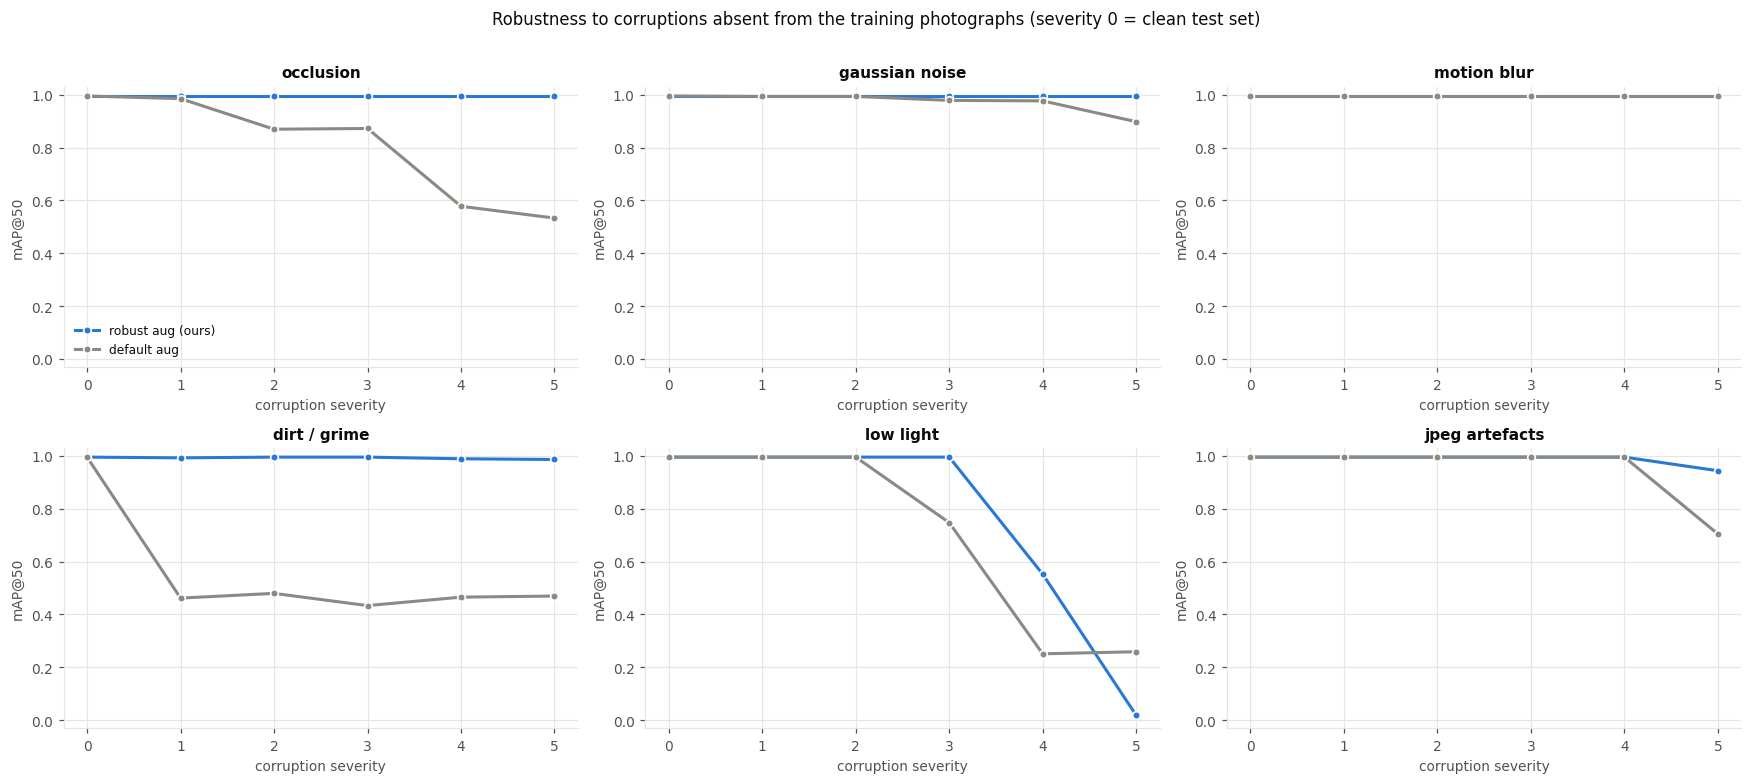

In [42]:
# ---------------------------------------------------- Figure: robustness curves
fig, axes = plt.subplots(2, 3, figsize=(16, 7.0))
clean = {m: rob_df[(rob_df.model == m) & (rob_df.family == "clean")].mAP50.iloc[0]
         for m in rob_df.model.unique()}
MC = {"robust aug (ours)": PALETTE[0], "default aug": INK3}
for ax, fam in zip(axes.ravel(), FAMILIES):
    for m in rob_df.model.unique():
        sub = rob_df[(rob_df.model == m) & (rob_df.family == fam)].sort_values("severity")
        xs = [0] + sub.severity.tolist(); ys = [clean[m]] + sub.mAP50.tolist()
        ax.plot(xs, ys, marker="o", markersize=5, color=MC[m], label=m,
                markeredgecolor="white", markeredgewidth=1.1)
    ax.set_title(fam); ax.set_xlabel("corruption severity"); ax.set_ylabel("mAP@50")
    ax.set_ylim(-0.03, 1.03); ax.set_xticks([0]+SEVERITIES)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Robustness to corruptions absent from the training photographs "
             "(severity 0 = clean test set)", y=1.01)
fig.tight_layout()
savefig(fig, "fig18_robustness")

summ = (rob_df[rob_df.family != "clean"]
        .groupby(["model", "family"]).mAP50.mean().unstack(0).round(4))
summ["advantage"] = (summ["robust aug (ours)"] - summ["default aug"]).round(4)
summ.loc["MEAN"] = summ.mean().round(4)
summ.to_csv(RES/"robustness_summary.csv")
display(summ)

### 9.4 How much would a random split have inflated the results?

§2.3 argued that a random split leaks near-duplicate frames between train and test. The cheapest
way to show the size of that effect is to do it: train the identical model on the **random** split
and compare its test score with the burst-grouped one.

In [43]:
LEAK_NAME = "finetune_yolov8n_randomsplit"
leak_best = RUNS / LEAK_NAME / "weights" / "best.pt"
if not leak_best.exists() or FORCE_RETRAIN:
    patch_ultralytics_albumentations(True)
    set_seed(CFG.seed)
    cfg2 = dict(TRAIN_CFG); cfg2["data"] = str(DATA_YAML_RAND)
    YOLO(CFG.base_model).train(name=LEAK_NAME, **cfg2)
else:
    print(f"[{LEAK_NAME}] already trained")

leak_eval = evaluate(leak_best, "yolov8n_randomsplit", split="test", data=DATA_YAML_RAND)
leak_df = pd.DataFrame([
    {"Split": "burst-grouped (reported)", **{k: round(EVAL["Fine-tuned YOLOv8n"][k], 4)
                                             for k in ["Precision","Recall","mAP50","mAP50-95"]}},
    {"Split": "random (leaky)", **{k: round(leak_eval[k], 4)
                                   for k in ["Precision","Recall","mAP50","mAP50-95"]}},
])
leak_df.loc[2] = ["inflation"] + [round(leak_df.iloc[1, i] - leak_df.iloc[0, i], 4)
                                  for i in range(1, 5)]
leak_df.to_csv(RES/"split_leakage.csv", index=False)
display(leak_df)

[finetune_yolov8n_randomsplit] already trained
Ultralytics 8.3.162  Python-3.11.9 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)


Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 2066.5286.1 MB/s, size: 131.4 KB)


val: Scanning D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\data\yolo_random\labels\test.cache... 44 images, 0 backgrounds, 0 corrupt: 100%|██████████| 44/44 [00:00<?, ?it/s]

val: Scanning D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\data\yolo_random\labels\test.cache... 44 images, 0 backgrounds, 0 corrupt: 100%|██████████| 44/44 [00:00<?, ?it/s]

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:00<00:00,  6.15it/s]

                   all         44         44      0.982      0.991      0.995      0.731


Speed: 0.2ms preprocess, 2.1ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\outputs\runs\val_yolov8n_randomsplit_test


,Split,Precision,Recall,mAP50,mAP50-95
0,burst-grouped (reported),0.9937,1.0000,0.995,0.7303
1,random (leaky),0.9818,0.9908,0.995,0.7311
2,inflation,-0.0119,-0.0092,0.000,0.0008


---
## 10. Multi-note counting check, and export for the live script

The bonus deliverable counts the **total taka value** visible in a webcam frame. The source data
has exactly one note per image, so the counting behaviour has to be checked explicitly on scenes
with several notes. The composites below are built by tiling held-out *test* images, which gives a
known ground-truth total to compare the model's sum against.

,notes_present,detected,true_total,predicted_total,correct
0,2,2,1500,1500,True
1,2,2,1500,1500,True
2,3,4,2500,3000,False
3,2,2,2000,2000,True
4,4,4,3000,3000,True
5,2,2,1000,1000,True



totals correct on 5/6 composite scenes


  saved -> outputs/figures/fig19_counting.png


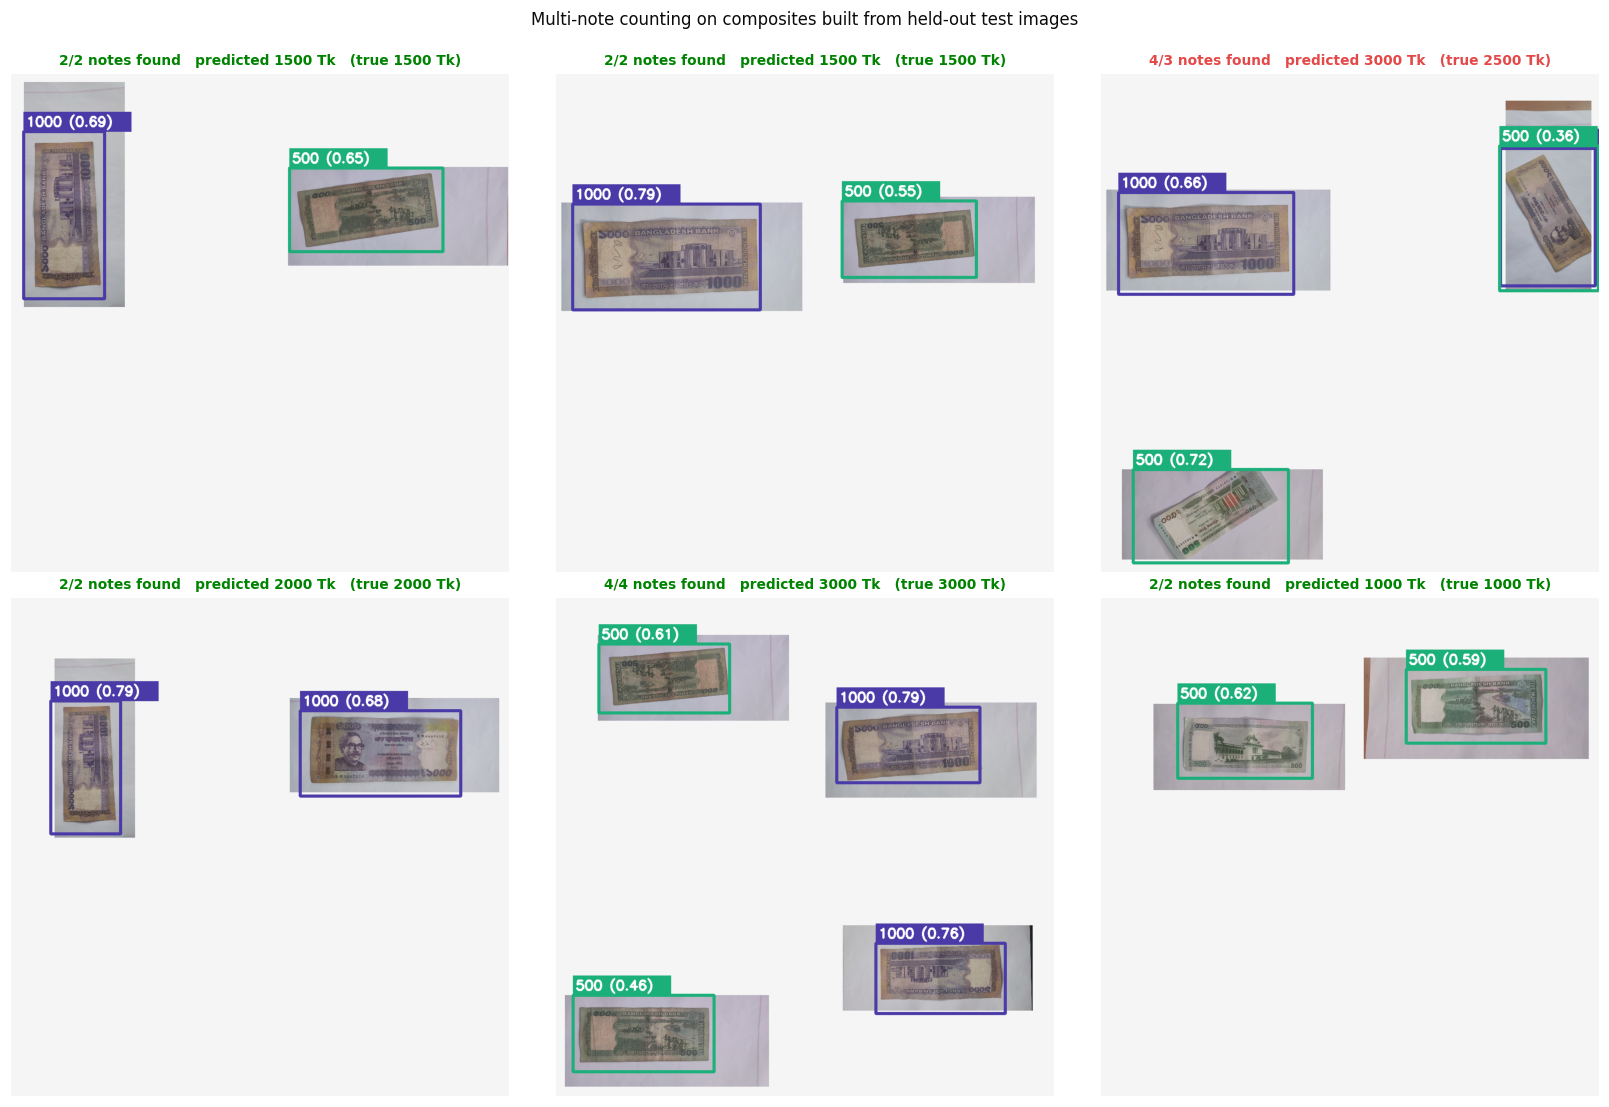

In [44]:
def make_composite(paths, grid=(2, 2), cell=560, jitter=True, rng=None):
    rng = rng or np.random.default_rng(0)
    gh, gw = grid
    canvas = np.full((gh*cell, gw*cell, 3), 245, np.uint8)
    truth = 0
    for k, p in enumerate(paths[:gh*gw]):
        im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        g = GT[p]["boxes"][0]
        truth += CFG.values[g[0]]
        sc = cell / max(im.shape[:2]) * (rng.uniform(.72, .98) if jitter else .95)
        im2 = cv2.resize(im, (int(im.shape[1]*sc), int(im.shape[0]*sc)))
        hh, ww = im2.shape[:2]
        oy = (k//gw)*cell + rng.integers(0, max(1, cell-hh))
        ox = (k%gw)*cell + rng.integers(0, max(1, cell-ww))
        canvas[oy:oy+hh, ox:ox+ww] = im2
    return canvas, truth

ft = YOLO(str(BEST_N))
rng = np.random.default_rng(21)
rows, panels = [], []
for trial in range(6):
    n = int(rng.integers(2, 5))
    sel = [paths[i] for i in rng.choice(len(paths), n, replace=False)]
    comp, truth = make_composite(sel, grid=(2, 2), rng=rng)
    r = ft.predict(comp, imgsz=CFG.imgsz, conf=CFG.conf_show, device=DEV, verbose=False)[0]
    total, vis = 0, comp.copy()
    counts = Counter()
    for b in r.boxes:
        cid = int(b.cls); conf = float(b.conf); xy = [int(v) for v in b.xyxy[0].tolist()]
        total += CFG.values[cid]; counts[CLASS_NAMES[cid]] += 1
        c = hex2bgr(CLS_COLOR[CLASS_NAMES[cid]])[::-1]
        cv2.rectangle(vis, (xy[0], xy[1]), (xy[2], xy[3]), c, 6)
        t = f"{CFG.values[cid]} ({conf:.2f})"
        cv2.rectangle(vis, (xy[0], max(0, xy[1]-44)), (xy[0]+len(t)*22, xy[1]), c, -1)
        cv2.putText(vis, t, (xy[0]+6, max(30, xy[1]-12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 3)
    rows.append(dict(notes_present=n, detected=len(r.boxes), true_total=truth,
                     predicted_total=total, correct=total == truth))
    panels.append((vis, truth, total, len(r.boxes), n))

count_df = pd.DataFrame(rows)
count_df.to_csv(RES/"counting_check.csv", index=False)
display(count_df)
print(f"\ntotals correct on {int(count_df.correct.sum())}/{len(count_df)} composite scenes")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (vis, truth, total, nd, n) in zip(axes.ravel(), panels):
    ax.imshow(vis); no_axes(ax)
    ok = total == truth
    ax.set_title(f"{nd}/{n} notes found   predicted {total} Tk   (true {truth} Tk)",
                 fontsize=9, color=PALETTE[5] if ok else PALETTE[7])
fig.suptitle("Multi-note counting on composites built from held-out test images", y=1.0)
fig.tight_layout()
savefig(fig, "fig19_counting")

## 11. Export the deployed weights

The live script loads `weights/taka_yolov8n.pt`. Copying the chosen checkpoint here means the
script has a stable path that does not depend on ultralytics' run-numbering.

In [45]:
DEPLOY = WEIGHTS / "taka_yolov8n.pt"
shutil.copy(BEST_N, DEPLOY)
shutil.copy(BEST_S, WEIGHTS / "taka_yolov8s.pt")
print(f"deployed: {DEPLOY}  ({DEPLOY.stat().st_size/1e6:.1f} MB)")

m = YOLO(str(DEPLOY))
print(f"classes: {m.names}")
print(f"taka value map: {{{', '.join(f'{i}: {v}' for i, v in enumerate(CFG.values))}}}")
del m

deployed: D:\Study\MSc\2nd semester\Computer Vision\Assignments\11\weights\taka_yolov8n.pt  (6.3 MB)
classes: {0: '500 taka', 1: '1000 taka'}
taka value map: {0: 500, 1: 1000}


In [46]:
# ---------------------------------------------------- consolidated results export
summary = {
    "dataset": {
        "source": "Assignment 9 smartphone photographs of Bangladeshi banknotes",
        "images": int(len(df)), "classes": CLASS_NAMES,
        "per_class": {k: int(v) for k, v in df.cls.value_counts().items()},
        "stored_resolution": "4000x1800", "exported_long_side": CFG.export_long_side,
        "split": {k: int(v) for k, v in df.split.value_counts().items()},
        "split_method": f"burst-grouped (gap > {CFG.burst_gap_s}s), stratified by class",
        "bursts": int(df.burst_id.nunique()),
        "annotation": "classical CV (LAB background distance + hysteresis Otsu + GrabCut + convex hull), visually verified",
    },
    "training": {k: str(v) for k, v in TRAIN_CFG.items()},
    "augmentation_geometric": AUG_HYP,
    "augmentation_photometric": "custom Albumentations: CoarseDropout, GaussNoise, ISONoise, "
                                "MotionBlur/Defocus, Spatter, RandomShadow, RandomBrightnessContrast, "
                                "RandomGamma, CLAHE, HueSaturationValue, ToGray, ImageCompression",
    "hardware": HARDWARE,
    "results_test": {n: {k: float(EVAL[n][k]) for k in
                         ["Precision", "Recall", "F1", "mAP50", "mAP50-95"]} for n in EVAL},
    "latency": bench_df.to_dict("records"),
    "pretrained_diagnostics": {
        "zero_detection_rate": float((coco_df.n_det == 0).mean()),
        "class_agnostic_recall_iou50": float((coco_df.best_iou >= 0.5).mean()),
        "mean_best_iou": float(coco_df.best_iou.mean()),
        "oracle_AP50": float(orc[0.5]), "oracle_AP75": float(orc[0.75]),
    },
    "error_cases": {k: int(v) for k, v in err_df.case.value_counts().items()},
    "robustness_mean_mAP50": {m: float(rob_df[(rob_df.model == m) & (rob_df.family != "clean")].mAP50.mean())
                              for m in rob_df.model.unique()},
    "split_leakage_inflation_mAP50": float(leak_eval["mAP50"] - EVAL["Fine-tuned YOLOv8n"]["mAP50"]),
}
(RES/"summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str)[:2200])
print("\n...")
print(f"\nfigures produced: {len(sorted(FIG.glob('*.png')))}")
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

{
  "dataset": {
    "source": "Assignment 9 smartphone photographs of Bangladeshi banknotes",
    "images": 290,
    "classes": [
      "500 taka",
      "1000 taka"
    ],
    "per_class": {
      "500 taka": 148,
      "1000 taka": 142
    },
    "stored_resolution": "4000x1800",
    "exported_long_side": 1280,
    "split": {
      "train": 200,
      "val": 45,
      "test": 45
    },
    "split_method": "burst-grouped (gap > 8s), stratified by class",
    "bursts": 76,
    "annotation": "classical CV (LAB background distance + hysteresis Otsu + GrabCut + convex hull), visually verified"
  },
  "training": {
    "data": "D:\\Study\\MSc\\2nd semester\\Computer Vision\\Assignments\\11\\data\\yolo\\data.yaml",
    "imgsz": "640",
    "epochs": "100",
    "batch": "16",
    "optimizer": "auto",
    "lr0": "0.01",
    "lrf": "0.01",
    "momentum": "0.937",
    "weight_decay": "0.0005",
    "warmup_epochs": "3.0",
    "cos_lr": "True",
    "patience": "30",
    "seed": "42",
    "determ

---
## 12. Bonus --- real-time webcam detection and taka counting

`detect_taka_live.py` loads `weights/taka_yolov8n.pt`, opens a camera, and on every frame draws the
detected notes and a running **total taka value** in view.

```bash
python detect_taka_live.py                  # default camera, 640px
python detect_taka_live.py --source 1       # a different camera
python detect_taka_live.py --imgsz 320      # faster on a weak CPU
python detect_taka_live.py --source clip.mp4 --save out.mp4
```

Design points that matter for it to be usable rather than just runnable:

* **Temporal smoothing.** A raw per-frame total flickers whenever one detection drops below the
  confidence threshold for a single frame. The script keeps a short history and reports the
  **modal** total over the last N frames, so the displayed amount is stable.
* **Duplicate suppression.** Class-aware NMS plus a minimum box area reject the double-counting
  that happens when one note is covered by two overlapping boxes.
* **Honest readout.** Per-class counts are shown next to the total, so a wrong total can be traced
  to which denomination was miscounted.
* **It degrades gracefully.** If no camera is available it says so instead of crashing, and
  `--source` accepts a video file so the script is testable without hardware.